China A-share factor timing

Run the cells in order. The separate Code Explanation.txt file explains the steps and results.

Imports

In [1]:
from pathlib import Path
import logging
import warnings
import math
import hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from prophet import Prophet
from cmdstanpy.utils import get_logger as get_cmdstanpy_logger
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from IPython.display import display
from matplotlib.dates import DateFormatter

Folders and table display

In [2]:
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "inputs/china_factor_100").is_dir()
)
INPUTS = ROOT / "inputs/china_factor_100"
RESULTS = ROOT / "results/china_factor_timing_final"
RESULTS.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:,.3f}".format
logging.getLogger("prophet").setLevel(logging.WARNING)
print("Project folder:", ROOT.name)

Project folder: CapstoneApplication


Load the company data

In [3]:
companies = pd.read_csv(INPUTS / "stocks.csv", dtype={"code": str})
price_rows = pd.read_csv(INPUTS / "prices.csv", dtype={"code": str}, parse_dates=["date"])
financials = pd.read_csv(
    INPUTS / "financials.csv",
    dtype={"code": str},
    parse_dates=["period", "notice_date", "available_date"],
)
share_rows = pd.read_csv(
    INPUTS / "shares.csv",
    dtype={"code": str},
    parse_dates=["effective_date", "notice_date", "available_date"],
)
companies["is_financial"] = (
    companies.is_financial.astype(str).str.lower().isin(["true", "1", "yes"])
)
financials["usable"] = financials.usable.astype(str).str.lower().isin(["true", "1", "yes"])
financials["balance_usable"] = (
    financials.balance_usable.astype(str).str.lower().isin(["true", "1", "yes"])
)
STOCKS = companies.code.tolist()
if len(STOCKS) != 100 or len(set(STOCKS)) != 100:
    raise ValueError("We need 100 different six-digit company codes.")
if not companies.code.str.fullmatch(r"[0-9]{6}").all():
    raise ValueError("Check the stock codes.")
if price_rows.duplicated(["code", "date"]).any():
    raise ValueError("A stock has more than one price on the same date.")
if not set(price_rows.code).issubset(STOCKS):
    raise ValueError("A price belongs to a company outside the list.")
print("Companies:", len(companies))
print("Price rows:", len(price_rows))
display(companies[["code", "name_en", "name_zh", "listing_date"]].head(10))

Companies: 100
Price rows: 261601


,code,name_en,name_zh,listing_date
0,002371,"NAURA Technology Group Co.,Ltd.",北方華創,2010-03-16
1,002422,"Sichuan Kelun Pharmaceutical Co., Ltd.",科倫藥業,2010-06-03
2,601728,China Telecom Corporation Limited,中國電信,2021-08-20
3,600276,"Jiangsu Hengrui Pharmaceuticals Co.,Ltd.",恒瑞醫藥,2000-10-18
4,600519,"Kweichow Moutai Co.,Ltd.",貴州茅臺,2001-08-27
5,300059,"East Money Information Co.,Ltd.",東方財富,2010-03-19
6,688981,SEMICONDUCTOR MANUFACTURING INTERNATIONAL CORP...,中芯國際,2020-07-16
7,300760,"Shenzhen Mindray Bio-Medical Electronics Co., ...",邁瑞醫療,2018-10-16
8,688271,"Shanghai United Imaging Healthcare Co., Ltd.",聯影醫療,2022-08-22
9,688111,"Beijing Kingsoft Office Software, Inc.",金山辦公,2019-11-18


Prepare daily prices

In [4]:
calendar = pd.DatetimeIndex(
    pd.read_csv(ROOT / "inputs/china_benchmark/market_calendar.csv", parse_dates=["date"]).date
)
calendar = calendar[(calendar >= price_rows.date.min()) & (calendar <= price_rows.date.max())]
price_rows = price_rows.loc[price_rows.date.isin(calendar)].copy()
observed = price_rows.pivot(index="date", columns="code", values="adjusted_close").reindex(
    index=calendar, columns=STOCKS
)
raw_observed = price_rows.pivot(index="date", columns="code", values="raw_close").reindex(
    index=calendar, columns=STOCKS
)
volumes = price_rows.pivot(index="date", columns="code", values="volume").reindex(
    index=calendar, columns=STOCKS
)
observed = observed.where(observed.gt(0))
raw_observed = raw_observed.where(raw_observed.gt(0))
tradable = observed.notna() & raw_observed.notna() & volumes.gt(0)

prices = observed.ffill()
raw_prices = raw_observed.ffill()
first_quote_dates = {}
for stock in STOCKS:
    first_quote_dates[stock] = observed[stock].first_valid_index()
first_quotes = pd.Series(first_quote_dates)
first_quotes.index.name = observed.columns.name
finance_by_code = {
    stock: rows.sort_values(["period", "available_date"])
    for stock, rows in financials.groupby("code")
}
shares_by_code = {
    stock: rows.sort_values(["effective_date", "available_date"])
    for stock, rows in share_rows.groupby("code")
}
company_info = companies.set_index("code")
daily_returns = prices.pct_change(fill_method=None)
if observed.stack().le(0).any():
    raise ValueError("Prices must be positive.")
print("First date:", calendar.min().date())
print("Last date:", calendar.max().date())
print("Trading dates:", len(calendar))

First date: 2015-01-05
Last date: 2026-10-16
Trading dates: 2862


Record the input files

In [5]:
input_record = []
for file in [
    INPUTS / name for name in ["stocks.csv", "prices.csv", "financials.csv", "shares.csv"]
] + [ROOT / "inputs/china_benchmark/market_calendar.csv"]:
    input_record.append(
        {
            "file": str(file.relative_to(ROOT)),
            "sha256": hashlib.sha256(file.read_bytes()).hexdigest(),
        }
    )
pd.DataFrame(input_record).to_csv(RESULTS / "input_files.csv", index=False)

companies.to_csv(RESULTS / "companies.csv", index=False)
print("Input files recorded:", len(input_record))

Input files recorded: 5


Calculate Value, Profitability and Momentum

In [6]:
FACTORS = ["Value", "Profitability", "Momentum"]
MIN_QUOTE_COUNT = 160
STALE_REPORT_MONTHS = 18

month_signals = calendar.to_series().groupby(calendar.to_period("M")).last()
month_signals = pd.DatetimeIndex(month_signals)
score_tables = {}
all_score_rows = []

for signal in month_signals:
    rows = []
    one_month = signal - pd.DateOffset(months=1)
    twelve_months = signal - pd.DateOffset(months=12)

    for stock in STOCKS:
        result = {
            "signal": signal,
            "code": stock,
            "eligible": False,
            "reason": "",
            "Value": np.nan,
            "Profitability": np.nan,
            "Momentum": np.nan,
        }

        if company_info.loc[stock, "is_financial"]:
            result["reason"] = "Financial business"
        elif not bool(tradable.loc[signal, stock]):
            result["reason"] = "No trading quote on the decision date"
        elif pd.isna(first_quotes[stock]) or first_quotes[stock] > twelve_months:
            result["reason"] = "Less than twelve months of price history"
        else:
            accounts = finance_by_code.get(stock, pd.DataFrame())
            known_shares = shares_by_code.get(stock, pd.DataFrame())

            if len(accounts):
                accounts = accounts.loc[accounts.available_date.le(signal)]
                accounts = accounts.sort_values(["period", "available_date"])
                accounts = accounts.drop_duplicates("period", keep="last")
            if len(known_shares):
                known_shares = known_shares.loc[
                    known_shares.available_date.le(signal) & known_shares.effective_date.le(signal)
                ]

            if accounts.empty:
                result["reason"] = "No available annual accounts"
            elif known_shares.empty:
                result["reason"] = "No available total share count"
            else:
                current = accounts.iloc[-1]
                prior = accounts.loc[accounts.period.eq(current.period - pd.DateOffset(years=1))]

                if not bool(current.usable):
                    result["reason"] = "Incomplete EBIT or capital fields"
                elif prior.empty or not bool(prior.iloc[-1].balance_usable):
                    result["reason"] = "No complete opening capital"
                elif signal > current.period + pd.DateOffset(months=STALE_REPORT_MONTHS):
                    result["reason"] = "Annual accounts are more than eighteen months old"
                else:
                    opening = prior.iloc[-1]
                    shares = known_shares.iloc[-1]
                    market_cap = float(raw_prices.loc[signal, stock]) * float(shares.total_shares)
                    enterprise_value = (
                        market_cap + current.interest_debt + current.minority_equity - current.cash
                    )
                    average_capital = (current.invested_capital + opening.invested_capital) / 2
                    history = daily_returns.loc[twelve_months:signal, stock].dropna()
                    quote_count = int(tradable.loc[twelve_months:signal, stock].sum())
                    volatility = history.std(ddof=1) * np.sqrt(252)
                    one_month_prices = prices.loc[:one_month, stock]
                    twelve_month_prices = prices.loc[:twelve_months, stock]
                    one_month_close = (
                        float(one_month_prices.iloc[-1]) if len(one_month_prices) else np.nan
                    )
                    twelve_month_close = (
                        float(twelve_month_prices.iloc[-1]) if len(twelve_month_prices) else np.nan
                    )
                    momentum = one_month_close / twelve_month_close - 1
                    values = [
                        current.ebit,
                        enterprise_value,
                        average_capital,
                        market_cap,
                        volatility,
                        momentum,
                    ]

                    if (
                        not np.isfinite(values).all()
                        or min(enterprise_value, average_capital, market_cap, volatility) <= 0
                    ):
                        result["reason"] = "Invalid factor denominator"
                    elif quote_count < MIN_QUOTE_COUNT:
                        result["reason"] = "Too few daily trading quotes for momentum"
                    else:
                        result.update(
                            {
                                "eligible": True,
                                "reason": "Available",
                                "Value": current.ebit / enterprise_value,
                                "Profitability": current.ebit / average_capital,
                                "Momentum": momentum / volatility,
                                "period": current.period,
                                "available_date": current.available_date,
                                "opening_available_date": opening.available_date,
                                "share_available_date": shares.available_date,
                                "share_effective_date": shares.effective_date,
                                "ebit": current.ebit,
                                "enterprise_value": enterprise_value,
                                "average_capital": average_capital,
                                "market_cap": market_cap,
                                "volatility": volatility,
                            }
                        )

        rows.append(result)

    scores = pd.DataFrame(rows).set_index("code")
    all_score_rows.append(scores.reset_index())
    if len(scores) != 100 or set(scores.index) != set(STOCKS):
        raise ValueError("Every monthly table must contain all 100 companies.")
    score_tables[signal] = scores
print("Monthly score tables:", len(score_tables))
display(score_tables[max(score_tables)][FACTORS].head(10))

Monthly score tables: 142


,Value,Profitability,Momentum
code,,,
002371,0.014,0.180,1.245
002422,0.038,0.093,0.374
601728,0.077,0.107,-0.197
600276,0.032,0.412,-1.071
600519,0.070,0.539,-0.544
300059,NaN,NaN,NaN
688981,0.010,0.038,-0.095
300760,0.051,0.387,-1.172
688271,0.024,0.136,-1.029


Build the long and short baskets

In [7]:
MIN_ELIGIBLE = 12
TAIL_FRACTION = 0.30
SIDE_WEIGHT = 0.50

baskets = {}
basket_rows = []
coverage_rows = []
all_month_scores = score_tables
score_tables = {}
for signal, scores in all_month_scores.items():
    eligible = scores.loc[scores.eligible].sort_index()
    if len(eligible) >= MIN_ELIGIBLE:
        score_tables[signal] = scores
        count = int(math.floor(len(eligible) * TAIL_FRACTION))
        weights = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
        for factor in FACTORS:
            ranked = eligible[factor].sort_values(ascending=False, kind="stable")
            long_codes = ranked.head(count).index
            short_codes = ranked.tail(count).index
            if set(long_codes).intersection(short_codes):
                raise ValueError("The long and short sides overlap.")
            weights.loc[long_codes, factor] = SIDE_WEIGHT / count
            weights.loc[short_codes, factor] = -SIDE_WEIGHT / count
            if not np.isclose(weights[factor].sum(), 0) or not np.isclose(
                weights[factor].abs().sum(), 1
            ):
                raise ValueError("Each basket must have zero net and one unit of gross exposure.")
            for code in long_codes:
                basket_rows.append(
                    {
                        "signal": signal,
                        "factor": factor,
                        "code": code,
                        "side": "Long",
                        "weight": weights.loc[code, factor],
                    }
                )
            for code in short_codes:
                basket_rows.append(
                    {
                        "signal": signal,
                        "factor": factor,
                        "code": code,
                        "side": "Short",
                        "weight": weights.loc[code, factor],
                    }
                )
        baskets[signal] = weights
        coverage_rows.append(
            {
                "signal": signal,
                "listed_companies": len(STOCKS),
                "eligible_companies": len(eligible),
                "long_count": count,
                "short_count": count,
                "eligible_not_held_per_factor": len(eligible) - 2 * count,
                "excluded_companies": len(STOCKS) - len(eligible),
            }
        )
print("Months with factor baskets:", len(baskets))

Months with factor baskets: 100


Save factor scores and data checks

In [8]:
score_history = pd.concat(all_score_rows, ignore_index=True)
score_history.to_csv(RESULTS / "factor_scores.csv", index=False)
eligible_counts = score_history.groupby("signal").eligible.sum().rename("eligible_count")
eligible_counts.to_csv(RESULTS / "eligible_counts.csv")
pd.DataFrame(basket_rows).to_csv(RESULTS / "factor_baskets.csv", index=False)
monthly_coverage = pd.DataFrame(coverage_rows).set_index("signal")
monthly_coverage.to_csv(RESULTS / "monthly_coverage.csv")
exclusion_reasons = (
    score_history.loc[~score_history.eligible]
    .groupby(["signal", "reason"])
    .size()
    .rename("companies")
    .reset_index()
)
exclusion_reasons.to_csv(RESULTS / "exclusion_reasons.csv", index=False)

if not baskets:
    raise ValueError("No month has enough complete company data.")

used = score_history.loc[score_history.eligible]
for field in [
    "available_date",
    "opening_available_date",
    "share_available_date",
    "share_effective_date",
]:
    if not used[field].le(used.signal).all():
        raise ValueError("A factor score uses information from after its decision date.")

display(monthly_coverage.tail(6))
display(score_tables[max(score_tables)].query("eligible")[FACTORS].head(10))

,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
signal,,,,,,
2026-05-29,100,93,27,27,39,7
2026-06-30,100,94,28,28,38,6
2026-07-31,100,94,28,28,38,6
2026-08-31,100,94,28,28,38,6
2026-09-30,100,94,28,28,38,6
2026-10-16,100,94,28,28,38,6


,Value,Profitability,Momentum
code,,,
002371,0.014,0.180,1.245
002422,0.038,0.093,0.374
601728,0.077,0.107,-0.197
600276,0.032,0.412,-1.071
600519,0.070,0.539,-0.544
688981,0.010,0.038,-0.095
300760,0.051,0.387,-1.172
688271,0.024,0.136,-1.029
688111,0.018,0.171,-0.614


Calculate daily factor values

In [9]:
INITIAL_VALUE = 100000.0
LONG_SHARE = 0.50
SHORT_SHARE = 0.50

entries = {}
for signal in score_tables:
    position = calendar.searchsorted(signal, side="right")
    if position < len(calendar):
        entries[signal] = calendar[position]

first_entry = min(entries.values())
first_position = calendar.get_loc(first_entry)
base_date = calendar[first_position - 1] if first_position > 0 else first_entry
factor_dates = calendar[(calendar >= base_date) & (calendar <= calendar[-1])]
factor_curves = {}
factor_exposure_rows = []

for factor in FACTORS:
    schedule = {}
    for signal, entry in entries.items():
        schedule[entry] = baskets[signal][factor].reindex(STOCKS, fill_value=0).to_numpy(float)

    holdings = np.zeros(len(STOCKS))
    cash = INITIAL_VALUE
    values = []
    previous = None

    for day in factor_dates:
        if previous is not None:
            relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
            if not np.isfinite(relative[np.abs(holdings) > 1e-10]).all():
                raise ValueError("A held stock has no valuation price.")
            holdings *= np.where(np.isfinite(relative), relative, 1.0)

        before = cash + holdings.sum()
        if before <= 0 or not np.isfinite(before):
            raise ValueError("A factor basket has no positive capital left.")

        if day in schedule:
            target = schedule[day]
            can_trade = tradable.loc[day].to_numpy(bool)
            frozen = holdings[~can_trade]
            frozen_long = frozen[frozen > 0].sum()
            frozen_short = -frozen[frozen < 0].sum()
            long_budget = max(LONG_SHARE * before - frozen_long, 0.0)
            short_budget = max(SHORT_SHARE * before - frozen_short, 0.0)
            long_target = np.clip(target[can_trade], 0, None)
            short_target = np.clip(-target[can_trade], 0, None)

            holdings[can_trade] = 0.0
            if long_target.sum() > 0:
                holdings[can_trade] += long_budget * long_target / long_target.sum()
            if short_target.sum() > 0:
                holdings[can_trade] -= short_budget * short_target / short_target.sum()
            cash = before - holdings.sum()

            long_value = holdings[holdings > 0].sum()
            short_value = -holdings[holdings < 0].sum()
            balanced = np.isclose(long_value, LONG_SHARE * before) and np.isclose(
                short_value, SHORT_SHARE * before
            )
            if (
                frozen_long <= LONG_SHARE * before
                and frozen_short <= SHORT_SHARE * before
                and long_target.sum() > 0
                and short_target.sum() > 0
                and not balanced
            ):
                raise ValueError("The two sides do not match their planned exposure.")
            factor_exposure_rows.append(
                {
                    "factor": factor,
                    "date": day,
                    "value": before,
                    "long_exposure": long_value / before,
                    "short_exposure": -short_value / before,
                    "gross_exposure": (long_value + short_value) / before,
                    "net_exposure": (long_value - short_value) / before,
                    "frozen_long": frozen_long / before,
                    "frozen_short": frozen_short / before,
                    "unavailable_long_targets": int(((target > 0) & ~can_trade).sum()),
                    "unavailable_short_targets": int(((target < 0) & ~can_trade).sum()),
                    "balanced": balanced,
                }
            )

        value = cash + holdings.sum()
        if value <= 0 or not np.isfinite(value):
            raise ValueError("The factor value is invalid.")
        values.append({"date": day, "value": value, "cash": cash})
        previous = day

    curve = pd.DataFrame(values).set_index("date")
    factor_curves[factor] = curve.value

factor_values = pd.DataFrame(factor_curves)
factor_values.to_csv(RESULTS / "factor_history.csv")
factor_exposure = pd.DataFrame(factor_exposure_rows)
factor_exposure.to_csv(RESULTS / "factor_exposures.csv", index=False)
print("First factor date:", factor_values.index.min().date())
print("Last factor date:", factor_values.index.max().date())

First factor date: 2018-07-31
Last factor date: 2026-10-16


Calculate next-month factor returns

In [10]:
monthly_rows = []
signals = sorted(entries)
for signal, following in zip(signals[:-1], signals[1:]):
    if following.to_period("M") != signal.to_period("M") + 1:
        continue
    entry = entries[signal]
    exit_date = entries[following]
    outcome = factor_values.loc[exit_date] / factor_values.loc[entry] - 1
    monthly_rows.append({"signal": signal, "entry": entry, "exit": exit_date, **outcome.to_dict()})

factor_targets = pd.DataFrame(monthly_rows).set_index("signal")
factor_targets.to_csv(RESULTS / "factor_targets.csv")
display(factor_targets.tail(6))
display(factor_exposure.groupby("factor")[["gross_exposure", "net_exposure"]].agg(["min", "max"]))

,entry,exit,Value,Profitability,Momentum
signal,,,,,
2026-03-31,2026-04-01,2026-05-06,-0.087,0.017,0.079
2026-04-30,2026-05-06,2026-06-01,-0.016,0.030,-0.001
2026-05-29,2026-06-01,2026-07-01,-0.086,0.018,0.023
2026-06-30,2026-07-01,2026-08-03,0.131,-0.008,-0.102
2026-07-31,2026-08-03,2026-09-01,-0.012,0.008,0.023
2026-08-31,2026-09-01,2026-10-08,0.023,-0.012,-0.023


gross_exposure       net_exposure      
                         min   max          min   max
factor                                               
Momentum               1.000 1.000       -0.000 0.000
Profitability          1.000 1.000       -0.000 0.000
Value                  1.000 1.000       -0.000 0.000

Build the weekly model inputs

In [11]:
LOOKBACK = 8
RETURN_WINDOWS = (1, 4, 13)
RISK_WINDOW = 13

sequences = {}
sequence_rows = []
sequence_date_rows = []

for signal in factor_targets.index:
    history = factor_values.loc[:signal]
    weekly = history.groupby(history.index.to_period("W-FRI")).tail(1)
    if len(weekly) < LOOKBACK + max(max(RETURN_WINDOWS), RISK_WINDOW):
        continue

    changes = weekly.pct_change(fill_method=None)
    rows = []
    for index in range(len(weekly) - LOOKBACK, len(weekly)):
        values = {}
        risk_returns = changes.iloc[index - RISK_WINDOW + 1 : index + 1]
        for factor in FACTORS:
            for window in RETURN_WINDOWS:
                values[f"{factor}_{window}w"] = (
                    weekly[factor].iloc[index] / weekly[factor].iloc[index - window] - 1
                )
            values[f"{factor}_volatility"] = risk_returns[factor].std(ddof=1) * np.sqrt(52)

        correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
        values["factor_correlation"] = float(correlations.mean())
        rows.append(values)

    frame = pd.DataFrame(rows, index=weekly.tail(LOOKBACK).index)
    if not np.isfinite(frame.to_numpy()).all():
        continue

    sequences[signal] = frame.to_numpy()
    sequence_rows.append(frame.assign(signal=signal).rename_axis("week").reset_index())
    sequence_date_rows.append(
        {
            "signal": signal,
            "first_input_week": frame.index.min(),
            "last_input_week": frame.index.max(),
        }
    )

sequence_dates = pd.DataFrame(sequence_date_rows).set_index("signal")
sample_signals = pd.DatetimeIndex(sorted(sequences))
samples = factor_targets.loc[sample_signals]
sample_x = np.stack([sequences[signal] for signal in sample_signals])
sample_y = samples[FACTORS].to_numpy()
pd.concat(sequence_rows, ignore_index=True).to_csv(RESULTS / "sequence_inputs.csv", index=False)
print("Input shape:", sample_x.shape)
print("Target shape:", sample_y.shape)

Input shape: (93, 8, 13)
Target shape: (93, 3)


Set the training and evaluation dates

In [12]:
MIN_TRAINING = 36
VALIDATION_START = pd.Timestamp("2023-01-01")
VALIDATION_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")
TEST_END = pd.Timestamp("2026-10-08")

validation_signals = samples.index[
    samples.entry.ge(VALIDATION_START) & samples.exit.le(VALIDATION_END)
]
test_signals = samples.index[samples.entry.ge(TEST_START) & samples.exit.le(TEST_END)]
run_signals = samples.index[samples.entry.ge(VALIDATION_START) & samples.exit.le(TEST_END)]
if len(run_signals) != 45 or pd.Timestamp("2024-11-29") not in run_signals:
    raise ValueError(
        "The continuous forecast history needs 45 periods, including the split boundary."
    )

if len(validation_signals) != 23 or len(test_signals) != 21:
    raise ValueError("We need 23 validation months and 21 completed evaluation months.")
if samples.loc[validation_signals].exit.max() > test_signals.min():
    raise ValueError("Model selection finishes after the first evaluation decision.")
for signal in run_signals:
    count = int(samples.exit.le(signal).sum())
    if count < MIN_TRAINING:
        raise ValueError(f"Only {count} completed training months before {signal.date()}.")

period_table = pd.DataFrame(
    [
        {
            "part": "Validation",
            "first_entry": samples.loc[validation_signals].entry.min(),
            "last_exit": samples.loc[validation_signals].exit.max(),
            "months": len(validation_signals),
        },
        {
            "part": "Evaluation",
            "first_entry": samples.loc[test_signals].entry.min(),
            "last_exit": samples.loc[test_signals].exit.max(),
            "months": len(test_signals),
        },
    ]
)
period_table.to_csv(RESULTS / "periods.csv", index=False)
display(period_table)
display(monthly_coverage.loc[run_signals].agg(["min", "max"]))
if not sequence_dates.last_input_week.le(sequence_dates.index).all():
    raise ValueError("An input uses a week after the forecast decision.")
sequence_dates.to_csv(RESULTS / "sequence_dates.csv")

,part,first_entry,last_exit,months
0,Validation,2023-01-03,2024-12-02,23
1,Evaluation,2025-01-02,2026-10-08,21


,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
min,100,90,27,27,36,6
max,100,94,28,28,39,10


Historical mean

In [13]:
MIN_TRAINING = 36

MODEL_FILES = RESULTS / "model_outputs"
MODEL_FILES.mkdir(parents=True, exist_ok=True)
history_rows = []
training_rows = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = (
        "validation"
        if signal in validation_signals
        else ("evaluation" if signal in test_signals else "bridge")
    )
    if len(training_index) < MIN_TRAINING:
        raise ValueError("Too few completed training months.")
    forecast = sample_y[training_mask].mean(axis=0)
    training_rows.append(
        {
            "signal": signal,
            "split": split,
            "training_months": len(training_index),
            "first_training_signal": training_index[0],
            "last_training_exit": samples.loc[training_index, "exit"].max(),
            "first_input_week": sequence_dates.loc[signal, "first_input_week"],
            "last_input_week": sequence_dates.loc[signal, "last_input_week"],
        }
    )
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        history_rows.append(
            {
                "signal": signal,
                "entry": samples.loc[signal, "entry"],
                "exit": samples.loc[signal, "exit"],
                "split": split,
                "model": "Historical mean",
                "factor": factor,
                "predicted_return": value,
                "actual_return": actual,
            }
        )

history_predictions = pd.DataFrame(history_rows)
training_audit = pd.DataFrame(training_rows)
training_audit.to_csv(RESULTS / "training_dates.csv", index=False)
if not training_audit.last_training_exit.le(training_audit.signal).all():
    raise ValueError("Training includes a return that was not finished.")
if not training_audit.last_input_week.le(training_audit.signal).all():
    raise ValueError("Inputs include a future date.")
print("Historical mean:", len(history_predictions) // 3, "monthly forecasts")
history_predictions.to_csv(MODEL_FILES / "historical_mean_predictions.csv", index=False)
history_audit = training_audit.assign(model="Historical mean")
history_audit.to_csv(MODEL_FILES / "historical_mean_audit.csv", index=False)

prediction_frames = [history_predictions.assign(seed=42)]
model_audits = [history_audit.assign(seed=42)]

Historical mean: 45 monthly forecasts


Ridge

In [14]:
model_seeds = [42]
alpha = 10.0

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    ridge_rows = []
    ridge_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = Ridge(alpha=alpha)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            ridge_warnings.append(
                {"signal": signal, "model": "Ridge", "message": str(warning.message)}
            )
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("Ridge produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            ridge_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Ridge",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    ridge_predictions = pd.DataFrame(ridge_rows)
    print("Ridge | seed:", run_seed, "| monthly forecasts:", len(ridge_predictions) // 3)
    ridge_predictions.to_csv(MODEL_FILES / "ridge_predictions.csv", index=False)
    pd.DataFrame(ridge_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "ridge_warnings.csv", index=False
    )
    ridge_audit = training_audit.assign(model="Ridge")
    ridge_audit.to_csv(MODEL_FILES / "ridge_audit.csv", index=False)
    model_audits.append(ridge_audit.assign(seed=run_seed))

    prediction_frames.append(ridge_predictions.assign(seed=run_seed))

Ridge | seed: 42 | monthly forecasts: 45


Ridge: forecasts

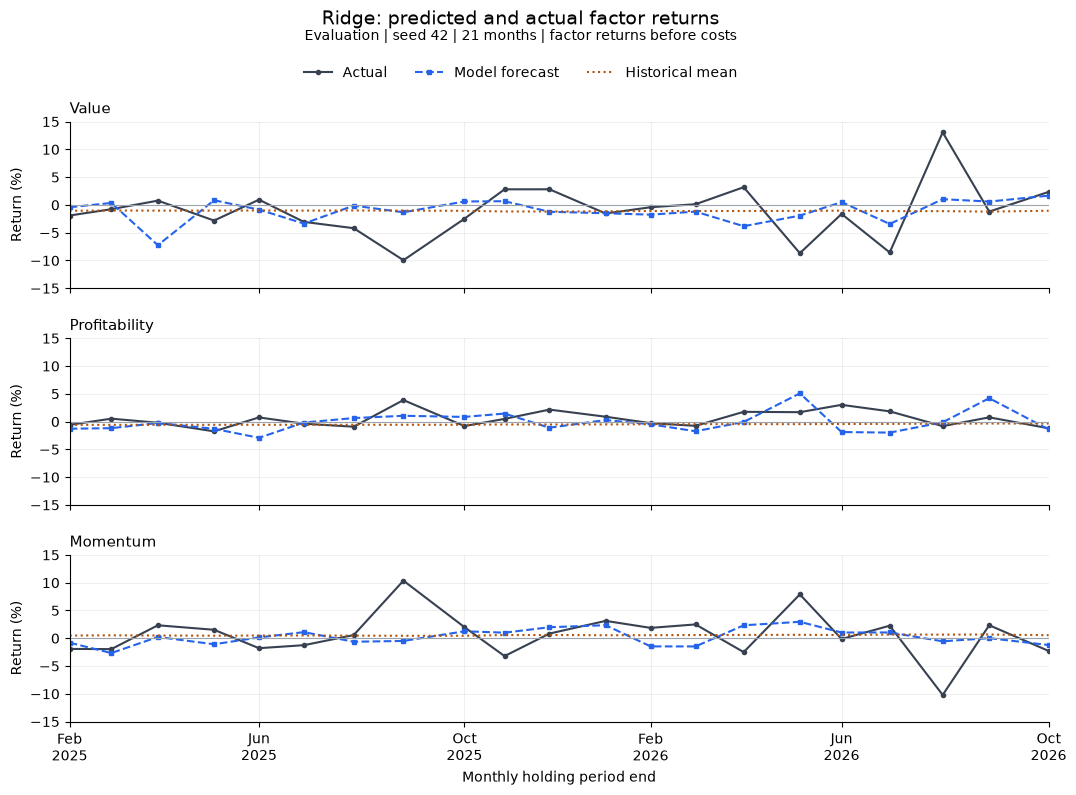

In [15]:
plot_model = "Ridge"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "ridge_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "ridge_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Ridge: errors and direction

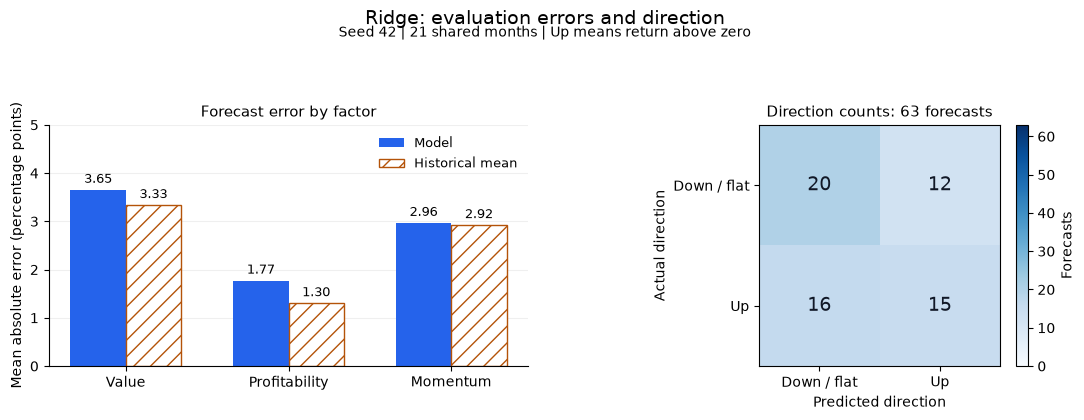

In [16]:
plot_model = "Ridge"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "ridge_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "ridge_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Elastic Net

In [17]:
model_seeds = [42]
alpha = 0.02
l1_ratio = 0.5
max_iterations = 10000

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    elastic_net_rows = []
    elastic_net_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MultiOutputRegressor(
            ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=max_iterations, random_state=seed)
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            elastic_net_warnings.append(
                {"signal": signal, "model": "Elastic Net", "message": str(warning.message)}
            )
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("Elastic Net produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            elastic_net_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Elastic Net",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    elastic_net_predictions = pd.DataFrame(elastic_net_rows)
    print(
        "Elastic Net | seed:", run_seed, "| monthly forecasts:", len(elastic_net_predictions) // 3
    )
    elastic_net_predictions.to_csv(MODEL_FILES / "elastic_net_predictions.csv", index=False)
    pd.DataFrame(elastic_net_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "elastic_net_warnings.csv", index=False
    )
    elastic_net_audit = training_audit.assign(model="Elastic Net")
    elastic_net_audit.to_csv(MODEL_FILES / "elastic_net_audit.csv", index=False)
    model_audits.append(elastic_net_audit.assign(seed=run_seed))

    prediction_frames.append(elastic_net_predictions.assign(seed=run_seed))

Elastic Net | seed: 42 | monthly forecasts: 45


Elastic Net: forecasts

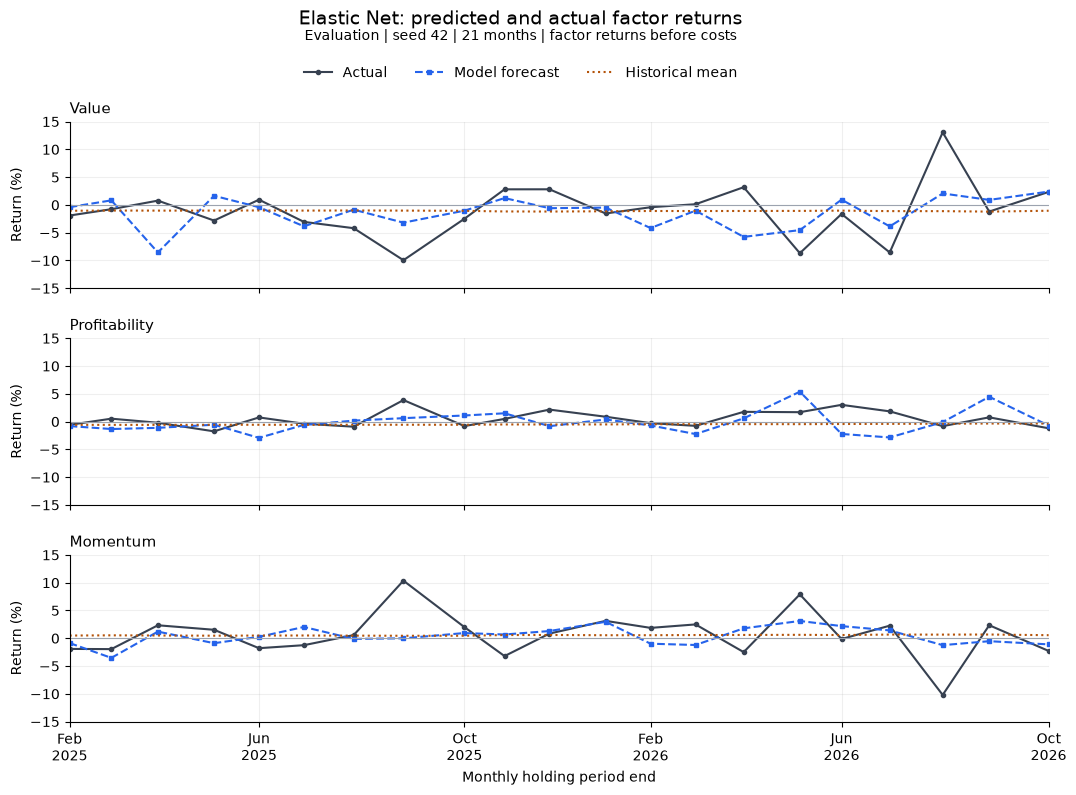

In [18]:
plot_model = "Elastic Net"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "elastic_net_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "elastic_net_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Elastic Net: errors and direction

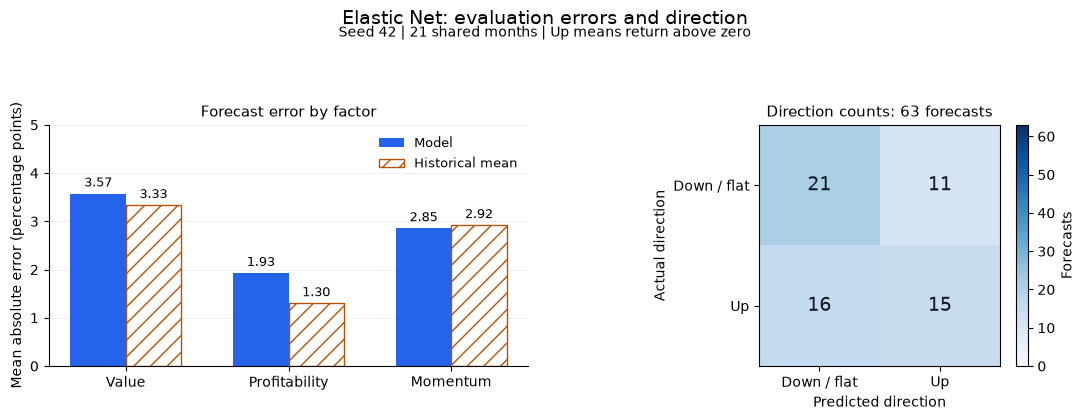

In [19]:
plot_model = "Elastic Net"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "elastic_net_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "elastic_net_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

KNN

In [20]:
model_seeds = [42]
neighbours = 20

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    knn_rows = []
    knn_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = KNeighborsRegressor(n_neighbors=neighbours)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            knn_warnings.append({"signal": signal, "model": "KNN", "message": str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("KNN produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            knn_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "KNN",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    knn_predictions = pd.DataFrame(knn_rows)
    print("KNN | seed:", run_seed, "| monthly forecasts:", len(knn_predictions) // 3)
    knn_predictions.to_csv(MODEL_FILES / "knn_predictions.csv", index=False)
    pd.DataFrame(knn_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "knn_warnings.csv", index=False
    )
    knn_audit = training_audit.assign(model="KNN")
    knn_audit.to_csv(MODEL_FILES / "knn_audit.csv", index=False)
    model_audits.append(knn_audit.assign(seed=run_seed))

    prediction_frames.append(knn_predictions.assign(seed=run_seed))

KNN | seed: 42 | monthly forecasts: 45


KNN: forecasts

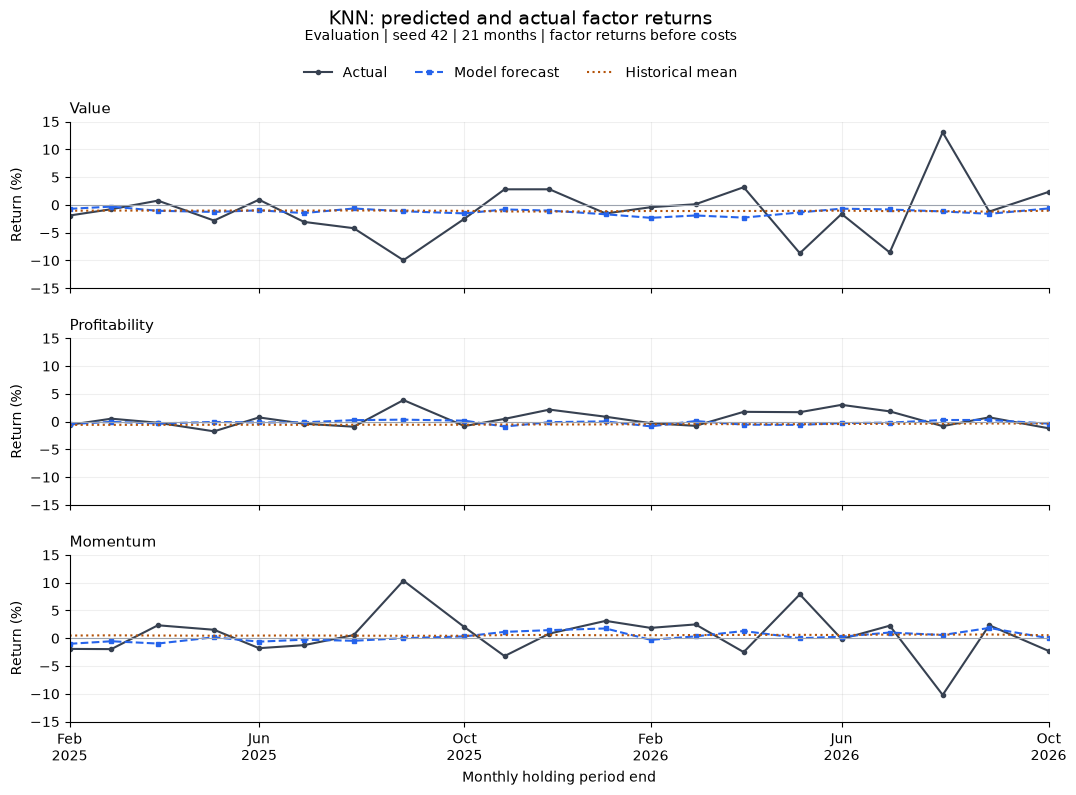

In [21]:
plot_model = "KNN"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "knn_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "knn_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

KNN: errors and direction

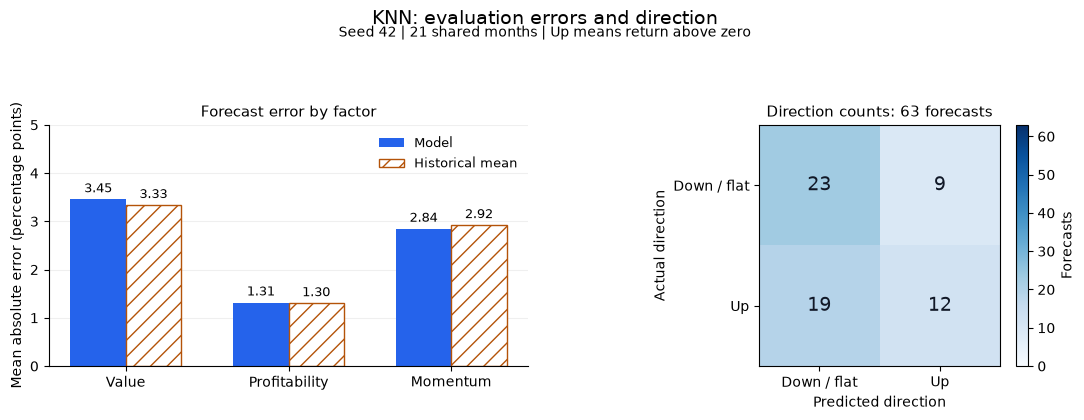

In [22]:
plot_model = "KNN"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "knn_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "knn_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

SVR

In [23]:
model_seeds = [42]
regularization = 1.0
epsilon = 0.1

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    svr_rows = []
    svr_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MultiOutputRegressor(SVR(C=regularization, epsilon=epsilon, kernel="rbf"))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            svr_warnings.append({"signal": signal, "model": "SVR", "message": str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("SVR produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            svr_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "SVR",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    svr_predictions = pd.DataFrame(svr_rows)
    print("SVR | seed:", run_seed, "| monthly forecasts:", len(svr_predictions) // 3)
    svr_predictions.to_csv(MODEL_FILES / "svr_predictions.csv", index=False)
    pd.DataFrame(svr_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "svr_warnings.csv", index=False
    )
    svr_audit = training_audit.assign(model="SVR")
    svr_audit.to_csv(MODEL_FILES / "svr_audit.csv", index=False)
    model_audits.append(svr_audit.assign(seed=run_seed))

    prediction_frames.append(svr_predictions.assign(seed=run_seed))

SVR | seed: 42 | monthly forecasts: 45


SVR: forecasts

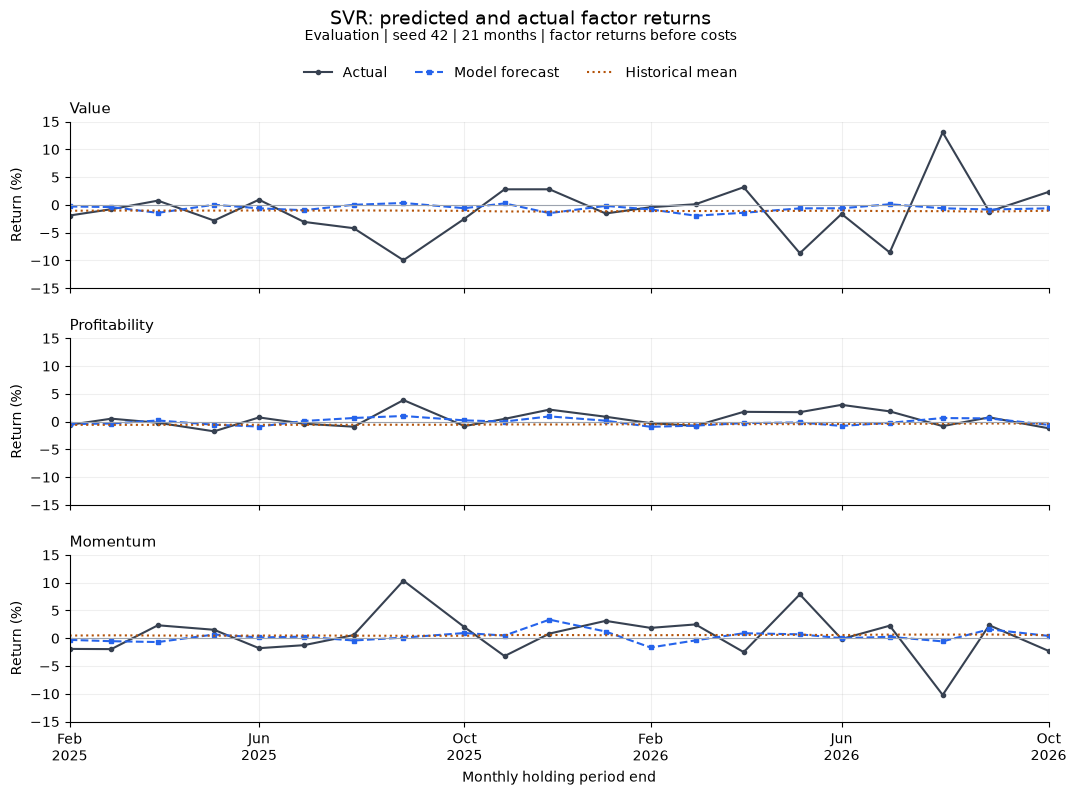

In [24]:
plot_model = "SVR"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "svr_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "svr_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

SVR: errors and direction

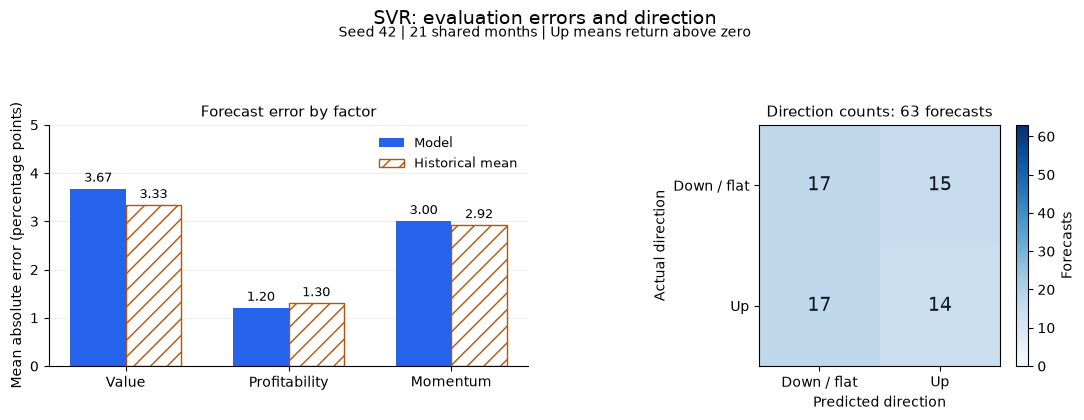

In [25]:
plot_model = "SVR"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "svr_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "svr_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Random Forest

In [26]:
model_seeds = [42, 7, 21, 84, 123]
trees = 150
max_depth = 4
min_leaf = 12

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    random_forest_rows = []
    random_forest_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = RandomForestRegressor(
            n_estimators=trees,
            max_depth=max_depth,
            min_samples_leaf=min_leaf,
            random_state=seed,
            n_jobs=2,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            random_forest_warnings.append(
                {"signal": signal, "model": "Random Forest", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("Random Forest produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            random_forest_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Random Forest",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    random_forest_predictions = pd.DataFrame(random_forest_rows)
    print(
        "Random Forest | seed:",
        run_seed,
        "| monthly forecasts:",
        len(random_forest_predictions) // 3,
    )
    random_forest_predictions.to_csv(MODEL_FILES / "random_forest_predictions.csv", index=False)
    pd.DataFrame(random_forest_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "random_forest_warnings.csv", index=False
    )
    random_forest_audit = training_audit.assign(model="Random Forest")
    random_forest_audit.to_csv(MODEL_FILES / "random_forest_audit.csv", index=False)
    model_audits.append(random_forest_audit.assign(seed=run_seed))

    prediction_frames.append(random_forest_predictions.assign(seed=run_seed))

Random Forest | seed: 42 | monthly forecasts: 45


Random Forest | seed: 7 | monthly forecasts: 45


Random Forest | seed: 21 | monthly forecasts: 45


Random Forest | seed: 84 | monthly forecasts: 45


Random Forest | seed: 123 | monthly forecasts: 45


Random Forest: forecasts

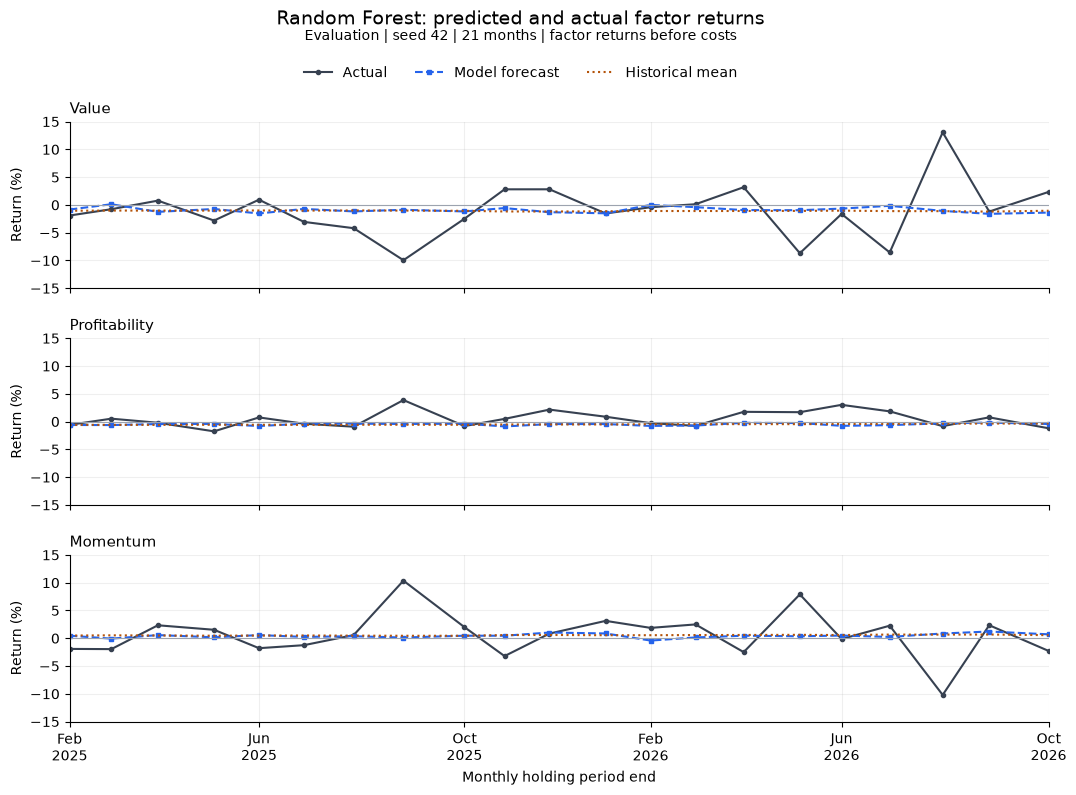

In [27]:
plot_model = "Random Forest"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "random_forest_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "random_forest_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Random Forest: errors and direction

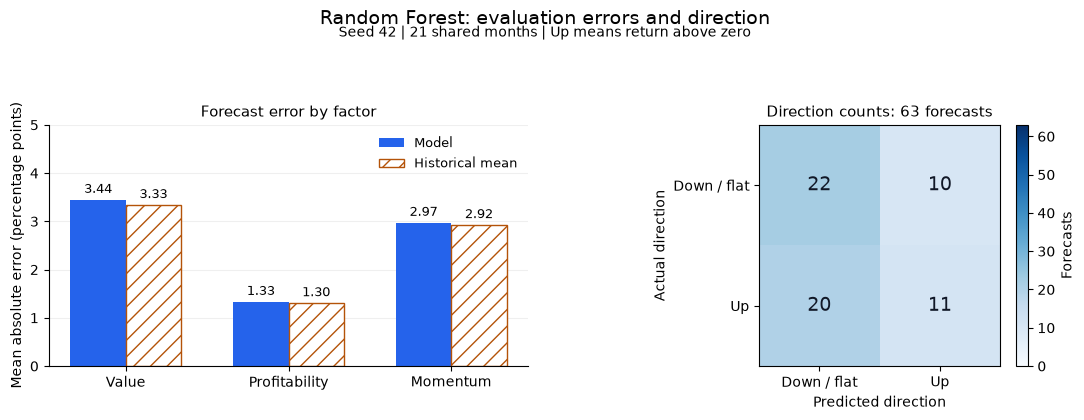

In [28]:
plot_model = "Random Forest"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "random_forest_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "random_forest_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Extra Trees

In [29]:
model_seeds = [42, 7, 21, 84, 123]
trees = 150
max_depth = 4
min_leaf = 12

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    extra_trees_rows = []
    extra_trees_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = ExtraTreesRegressor(
            n_estimators=trees,
            max_depth=max_depth,
            min_samples_leaf=min_leaf,
            random_state=seed,
            n_jobs=2,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            extra_trees_warnings.append(
                {"signal": signal, "model": "Extra Trees", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("Extra Trees produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            extra_trees_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Extra Trees",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    extra_trees_predictions = pd.DataFrame(extra_trees_rows)
    print(
        "Extra Trees | seed:", run_seed, "| monthly forecasts:", len(extra_trees_predictions) // 3
    )
    extra_trees_predictions.to_csv(MODEL_FILES / "extra_trees_predictions.csv", index=False)
    pd.DataFrame(extra_trees_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "extra_trees_warnings.csv", index=False
    )
    extra_trees_audit = training_audit.assign(model="Extra Trees")
    extra_trees_audit.to_csv(MODEL_FILES / "extra_trees_audit.csv", index=False)
    model_audits.append(extra_trees_audit.assign(seed=run_seed))

    prediction_frames.append(extra_trees_predictions.assign(seed=run_seed))

Extra Trees | seed: 42 | monthly forecasts: 45


Extra Trees | seed: 7 | monthly forecasts: 45


Extra Trees | seed: 21 | monthly forecasts: 45


Extra Trees | seed: 84 | monthly forecasts: 45


Extra Trees | seed: 123 | monthly forecasts: 45


Extra Trees: forecasts

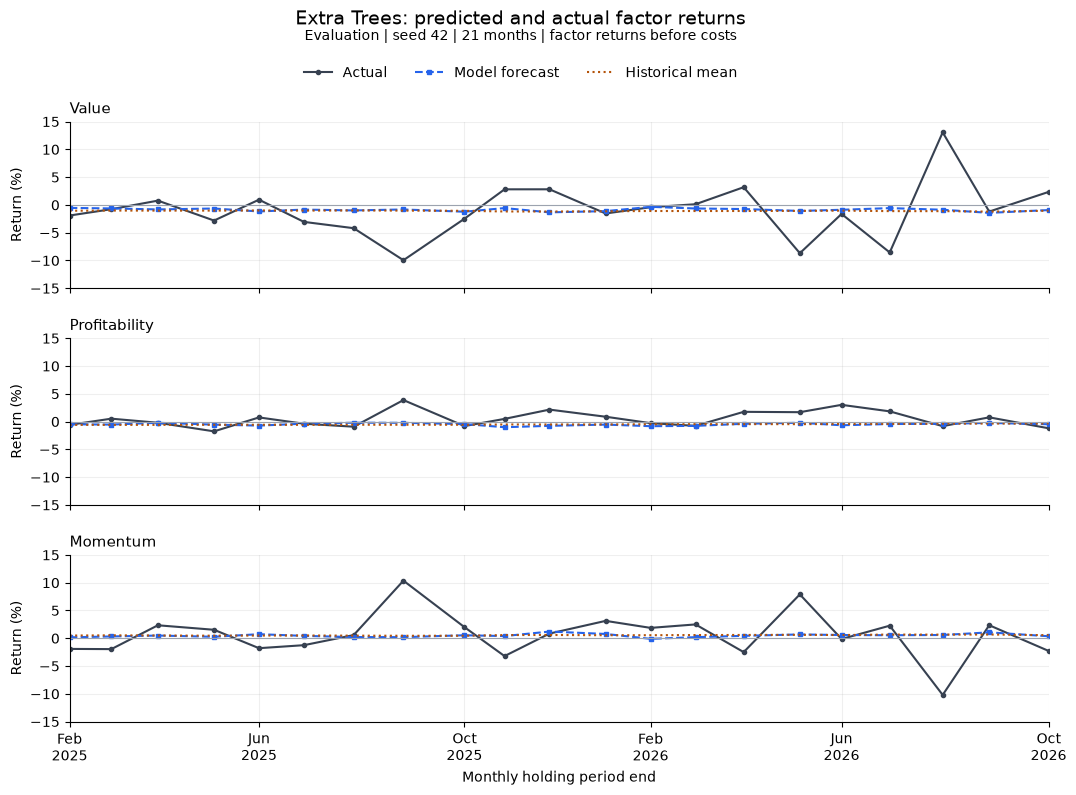

In [30]:
plot_model = "Extra Trees"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "extra_trees_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "extra_trees_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Extra Trees: errors and direction

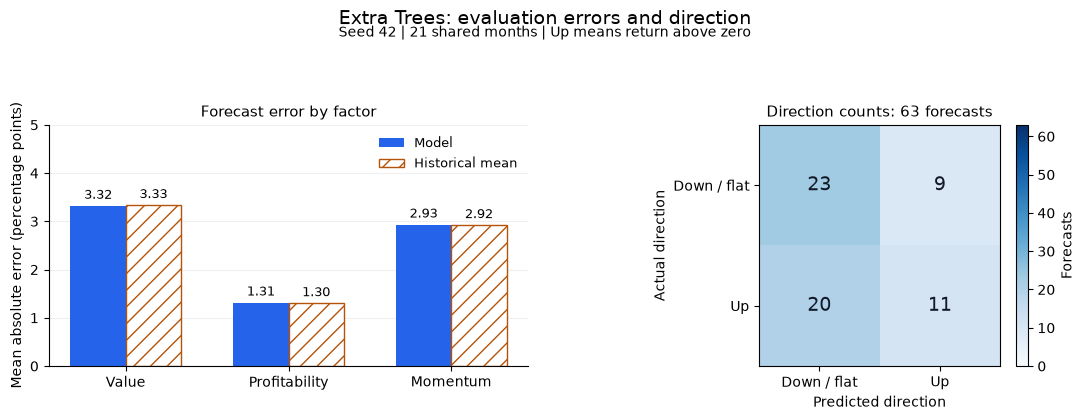

In [31]:
plot_model = "Extra Trees"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "extra_trees_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "extra_trees_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

XGBoost

In [32]:
model_seeds = [42, 7, 21, 84, 123]
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    xgboost_rows = []
    xgboost_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = MultiOutputRegressor(
            XGBRegressor(
                n_estimators=trees,
                max_depth=max_depth,
                learning_rate=learning_rate,
                subsample=subsample,
                colsample_bytree=column_sample,
                reg_lambda=l2_penalty,
                objective="reg:squarederror",
                random_state=seed,
                n_jobs=2,
            )
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            xgboost_warnings.append(
                {"signal": signal, "model": "XGBoost", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("XGBoost produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            xgboost_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "XGBoost",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    xgboost_predictions = pd.DataFrame(xgboost_rows)
    print("XGBoost | seed:", run_seed, "| monthly forecasts:", len(xgboost_predictions) // 3)
    xgboost_predictions.to_csv(MODEL_FILES / "xgboost_predictions.csv", index=False)
    pd.DataFrame(xgboost_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "xgboost_warnings.csv", index=False
    )
    xgboost_audit = training_audit.assign(model="XGBoost")
    xgboost_audit.to_csv(MODEL_FILES / "xgboost_audit.csv", index=False)
    model_audits.append(xgboost_audit.assign(seed=run_seed))

    prediction_frames.append(xgboost_predictions.assign(seed=run_seed))

XGBoost | seed: 42 | monthly forecasts: 45


XGBoost | seed: 7 | monthly forecasts: 45


XGBoost | seed: 21 | monthly forecasts: 45


XGBoost | seed: 84 | monthly forecasts: 45


XGBoost | seed: 123 | monthly forecasts: 45


XGBoost: forecasts

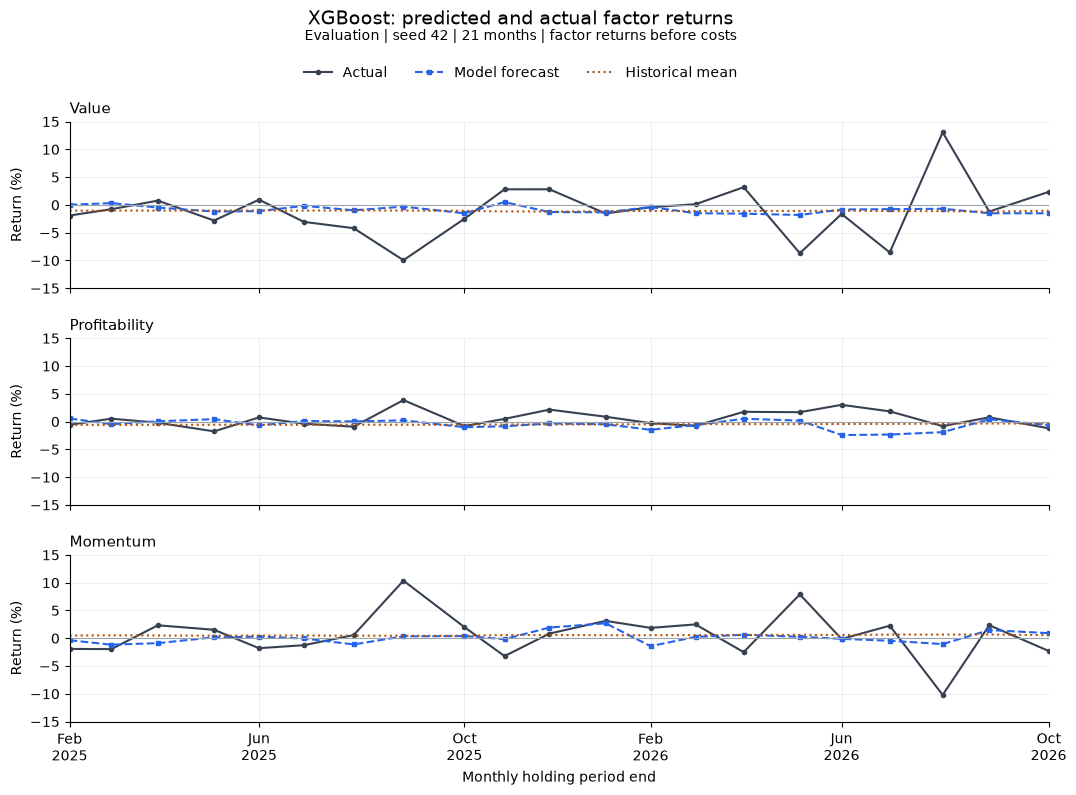

In [33]:
plot_model = "XGBoost"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "xgboost_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "xgboost_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

XGBoost: errors and direction

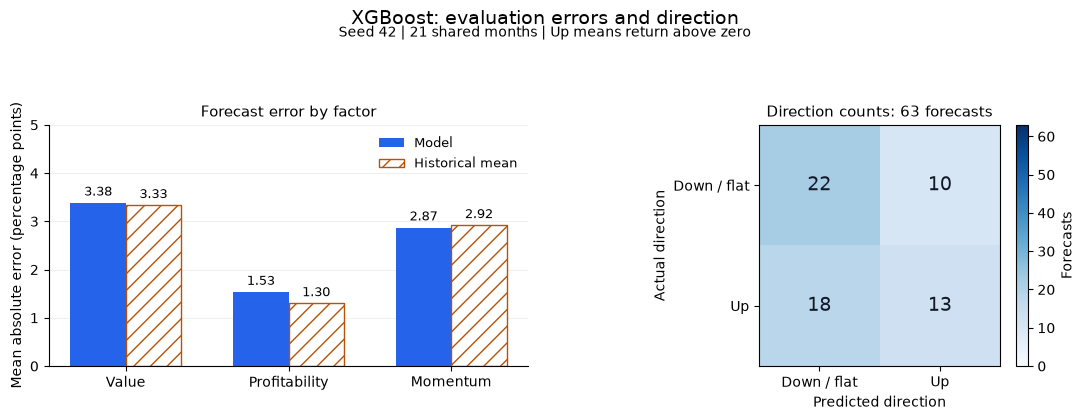

In [34]:
plot_model = "XGBoost"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "xgboost_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "xgboost_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Decision Tree

In [35]:
model_seeds = [42, 7, 21, 84, 123]
max_depth = 3
min_leaf = 12

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    decision_tree_rows = []
    decision_tree_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = DecisionTreeRegressor(
            max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            decision_tree_warnings.append(
                {"signal": signal, "model": "Decision Tree", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("Decision Tree produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            decision_tree_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Decision Tree",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    decision_tree_predictions = pd.DataFrame(decision_tree_rows)
    print(
        "Decision Tree | seed:",
        run_seed,
        "| monthly forecasts:",
        len(decision_tree_predictions) // 3,
    )
    decision_tree_predictions.to_csv(MODEL_FILES / "decision_tree_predictions.csv", index=False)
    pd.DataFrame(decision_tree_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "decision_tree_warnings.csv", index=False
    )
    decision_tree_audit = training_audit.assign(model="Decision Tree")
    decision_tree_audit.to_csv(MODEL_FILES / "decision_tree_audit.csv", index=False)
    model_audits.append(decision_tree_audit.assign(seed=run_seed))

    prediction_frames.append(decision_tree_predictions.assign(seed=run_seed))

Decision Tree | seed: 42 | monthly forecasts: 45
Decision Tree | seed: 7 | monthly forecasts: 45
Decision Tree | seed: 21 | monthly forecasts: 45


Decision Tree | seed: 84 | monthly forecasts: 45
Decision Tree | seed: 123 | monthly forecasts: 45


Decision Tree: forecasts

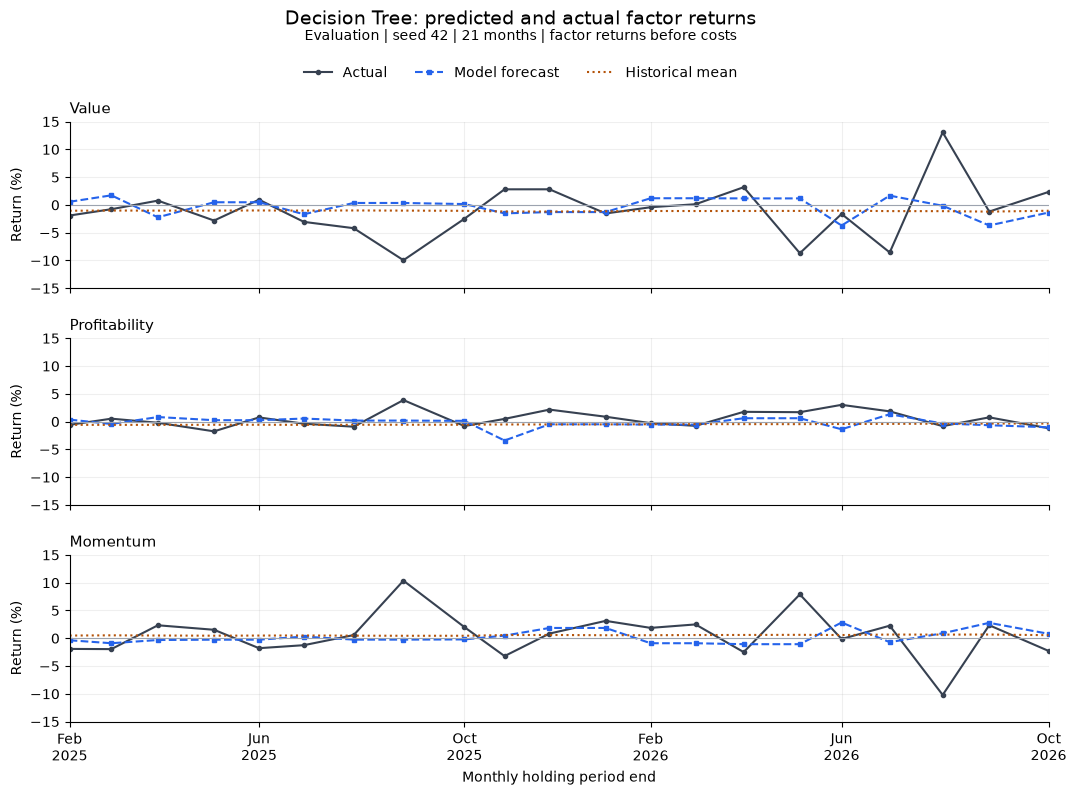

In [36]:
plot_model = "Decision Tree"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "decision_tree_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "decision_tree_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Decision Tree: errors and direction

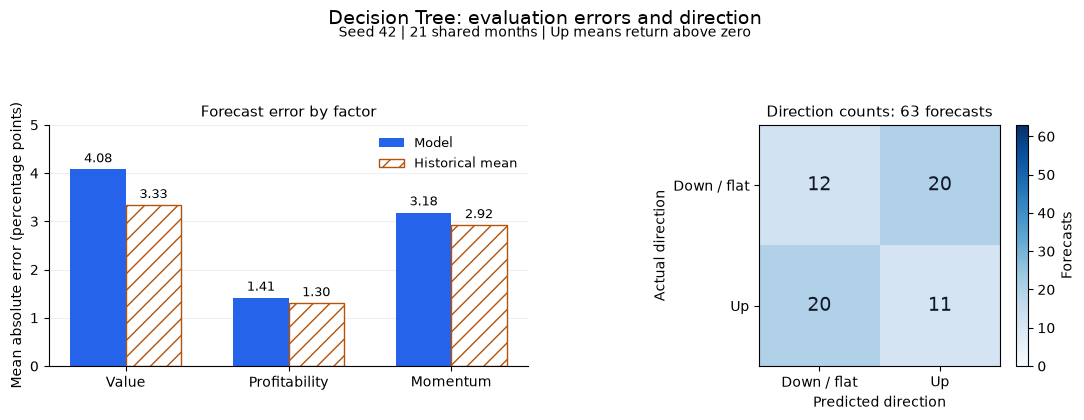

In [37]:
plot_model = "Decision Tree"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "decision_tree_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "decision_tree_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

AdaBoost

In [38]:
model_seeds = [42, 7, 21, 84, 123]
trees = 100
max_depth = 2
min_leaf = 8
learning_rate = 0.03
loss = "linear"

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    adaboost_rows = []
    adaboost_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        base_tree = DecisionTreeRegressor(
            max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed
        )
        model = MultiOutputRegressor(
            AdaBoostRegressor(
                estimator=base_tree,
                n_estimators=trees,
                learning_rate=learning_rate,
                loss=loss,
                random_state=seed,
            )
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            adaboost_warnings.append(
                {"signal": signal, "model": "AdaBoost", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("AdaBoost produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            adaboost_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "AdaBoost",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    adaboost_predictions = pd.DataFrame(adaboost_rows)
    print("AdaBoost | seed:", run_seed, "| monthly forecasts:", len(adaboost_predictions) // 3)
    adaboost_predictions.to_csv(MODEL_FILES / "adaboost_predictions.csv", index=False)
    pd.DataFrame(adaboost_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "adaboost_warnings.csv", index=False
    )
    adaboost_audit = training_audit.assign(model="AdaBoost")
    adaboost_audit.to_csv(MODEL_FILES / "adaboost_audit.csv", index=False)
    model_audits.append(adaboost_audit.assign(seed=run_seed))

    prediction_frames.append(adaboost_predictions.assign(seed=run_seed))

AdaBoost | seed: 42 | monthly forecasts: 45


AdaBoost | seed: 7 | monthly forecasts: 45


AdaBoost | seed: 21 | monthly forecasts: 45


AdaBoost | seed: 84 | monthly forecasts: 45


AdaBoost | seed: 123 | monthly forecasts: 45


AdaBoost: forecasts

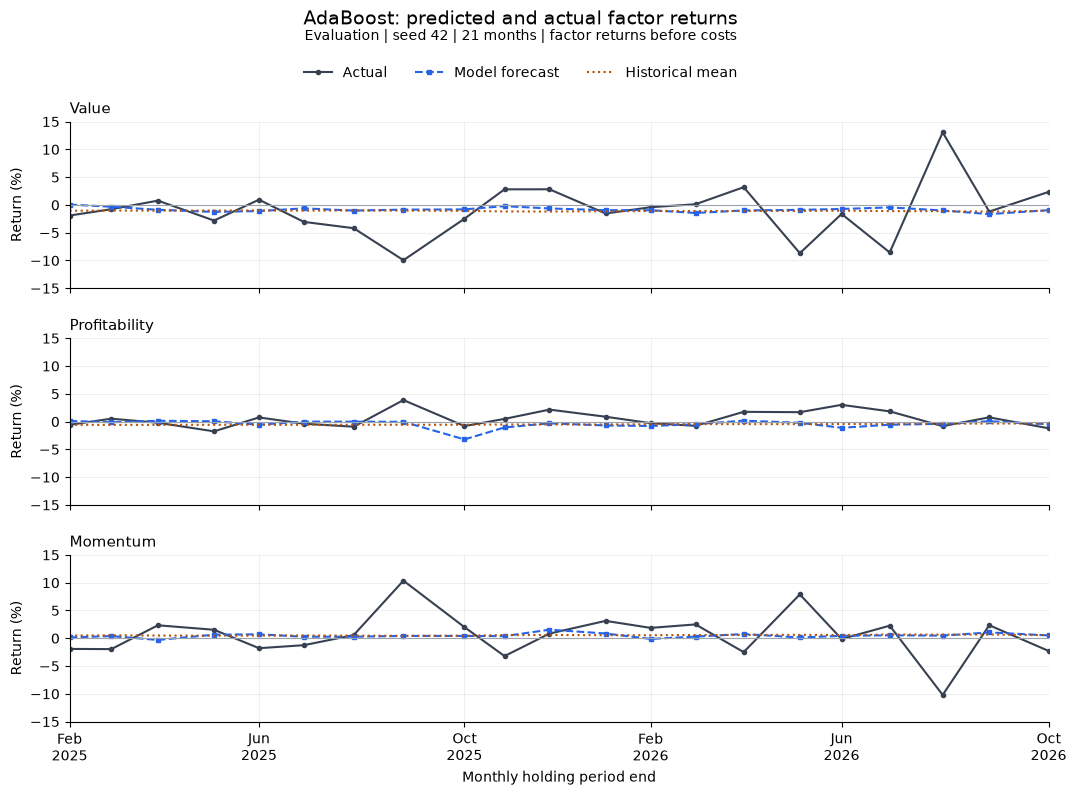

In [39]:
plot_model = "AdaBoost"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "adaboost_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "adaboost_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

AdaBoost: errors and direction

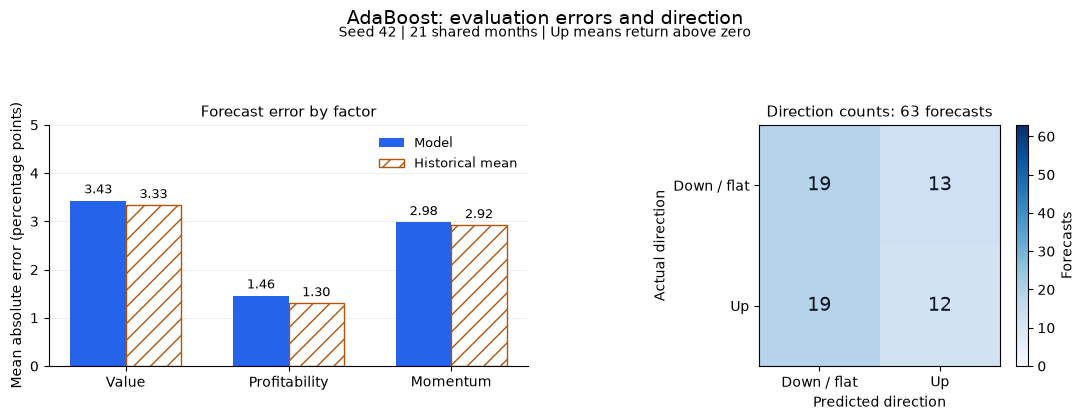

In [40]:
plot_model = "AdaBoost"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "adaboost_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "adaboost_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

LightGBM

In [41]:
model_seeds = [42, 7, 21, 84, 123]
trees = 120
max_depth = 2
leaves = 4
min_leaf = 12
learning_rate = 0.03
l2_penalty = 5.0
workers = 2

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    lightgbm_rows = []
    lightgbm_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        input_names = [f"input_{number}" for number in range(train_x.shape[1])]
        fitting_x = pd.DataFrame(train_x, columns=input_names)
        fitting_y = train_y
        prediction_x = pd.DataFrame(test_x, columns=input_names)
        model = MultiOutputRegressor(
            LGBMRegressor(
                n_estimators=trees,
                max_depth=max_depth,
                num_leaves=leaves,
                min_child_samples=min_leaf,
                learning_rate=learning_rate,
                reg_lambda=l2_penalty,
                random_state=seed,
                n_jobs=workers,
                deterministic=True,
                force_col_wise=True,
                verbosity=-1,
            )
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            lightgbm_warnings.append(
                {"signal": signal, "model": "LightGBM", "message": str(warning.message)}
            )
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("LightGBM produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            lightgbm_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "LightGBM",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    lightgbm_predictions = pd.DataFrame(lightgbm_rows)
    print("LightGBM | seed:", run_seed, "| monthly forecasts:", len(lightgbm_predictions) // 3)
    lightgbm_predictions.to_csv(MODEL_FILES / "lightgbm_predictions.csv", index=False)
    pd.DataFrame(lightgbm_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "lightgbm_warnings.csv", index=False
    )
    lightgbm_audit = training_audit.assign(model="LightGBM")
    lightgbm_audit.to_csv(MODEL_FILES / "lightgbm_audit.csv", index=False)
    model_audits.append(lightgbm_audit.assign(seed=run_seed))

    prediction_frames.append(lightgbm_predictions.assign(seed=run_seed))

LightGBM | seed: 42 | monthly forecasts: 45


LightGBM | seed: 7 | monthly forecasts: 45


LightGBM | seed: 21 | monthly forecasts: 45


LightGBM | seed: 84 | monthly forecasts: 45


LightGBM | seed: 123 | monthly forecasts: 45


LightGBM: forecasts

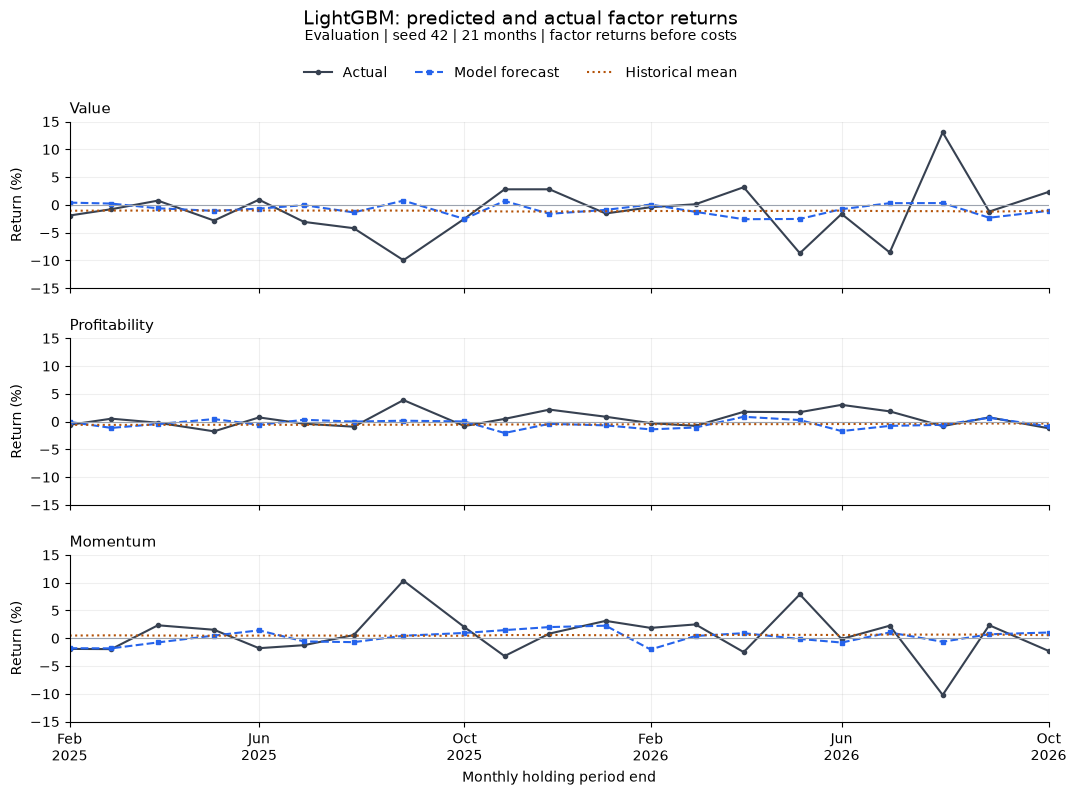

In [42]:
plot_model = "LightGBM"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lightgbm_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "lightgbm_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

LightGBM: errors and direction

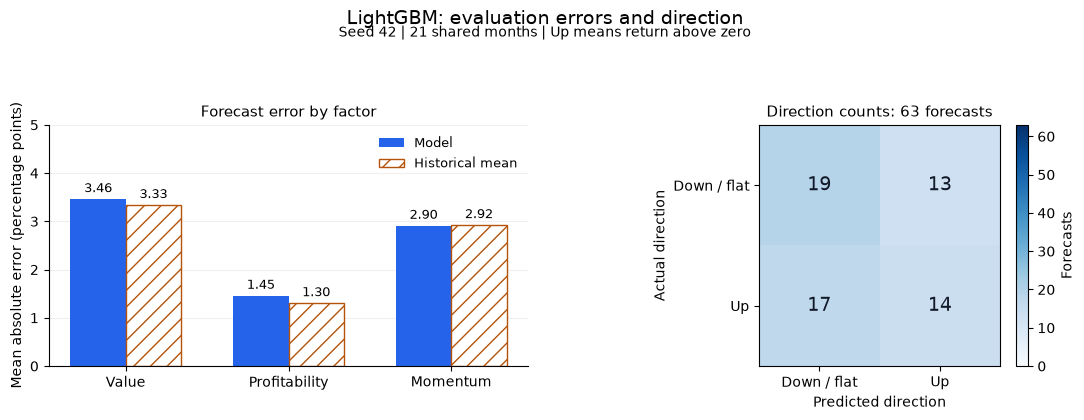

In [43]:
plot_model = "LightGBM"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lightgbm_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "lightgbm_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

MLP

In [44]:
model_seeds = [42, 7, 21, 84, 123]
hidden_units = (12,)
alpha = 5.0
max_iterations = 1500
max_function_calls = 30000
tolerance = 0.0001

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    mlp_rows = []
    mlp_warnings = []

    for signal in run_signals:

        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1].reshape(1, -1)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = MLPRegressor(
            hidden_layer_sizes=hidden_units,
            solver="lbfgs",
            alpha=alpha,
            max_iter=max_iterations,
            max_fun=max_function_calls,
            tol=tolerance,
            random_state=seed,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            mlp_warnings.append({"signal": signal, "model": "MLP", "message": str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("MLP produced an invalid forecast.")
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            mlp_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "MLP",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    mlp_predictions = pd.DataFrame(mlp_rows)
    print("MLP | seed:", run_seed, "| monthly forecasts:", len(mlp_predictions) // 3)
    mlp_predictions.to_csv(MODEL_FILES / "mlp_predictions.csv", index=False)
    pd.DataFrame(mlp_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "mlp_warnings.csv", index=False
    )
    mlp_audit = training_audit.assign(model="MLP")
    mlp_audit.to_csv(MODEL_FILES / "mlp_audit.csv", index=False)
    model_audits.append(mlp_audit.assign(seed=run_seed))

    prediction_frames.append(mlp_predictions.assign(seed=run_seed))

MLP | seed: 42 | monthly forecasts: 45


MLP | seed: 7 | monthly forecasts: 45


MLP | seed: 21 | monthly forecasts: 45


MLP | seed: 84 | monthly forecasts: 45


MLP | seed: 123 | monthly forecasts: 45


MLP: forecasts

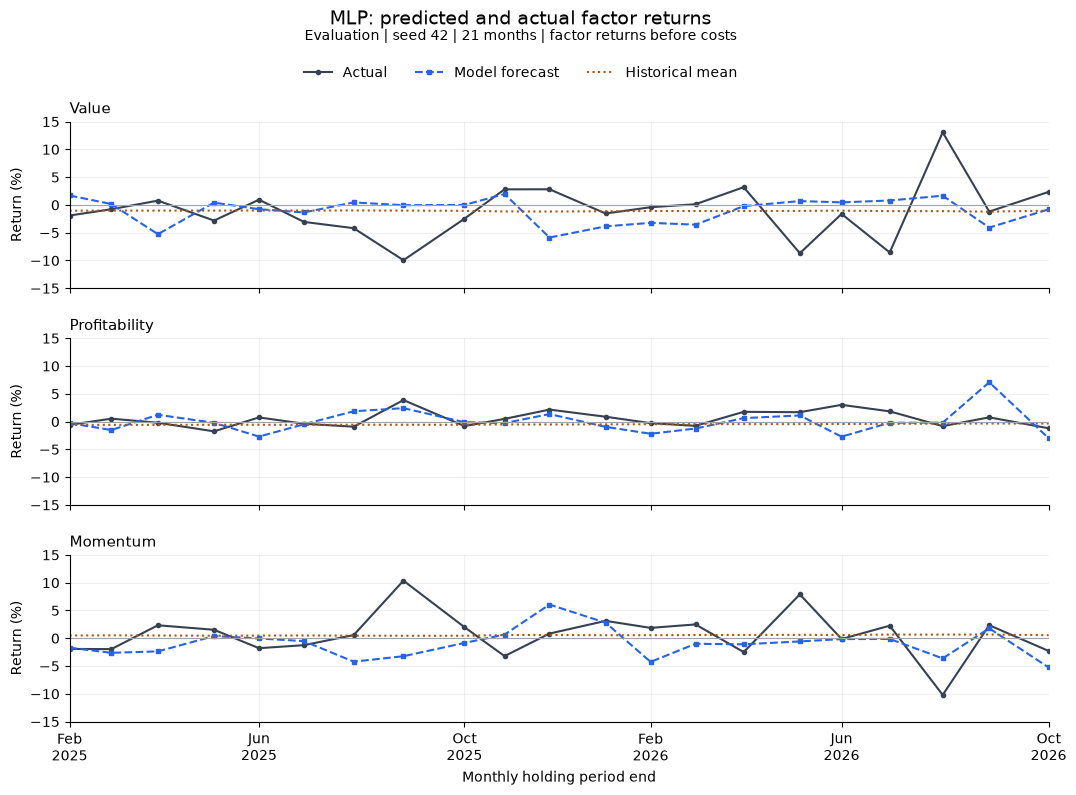

In [45]:
plot_model = "MLP"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "mlp_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "mlp_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

MLP: errors and direction

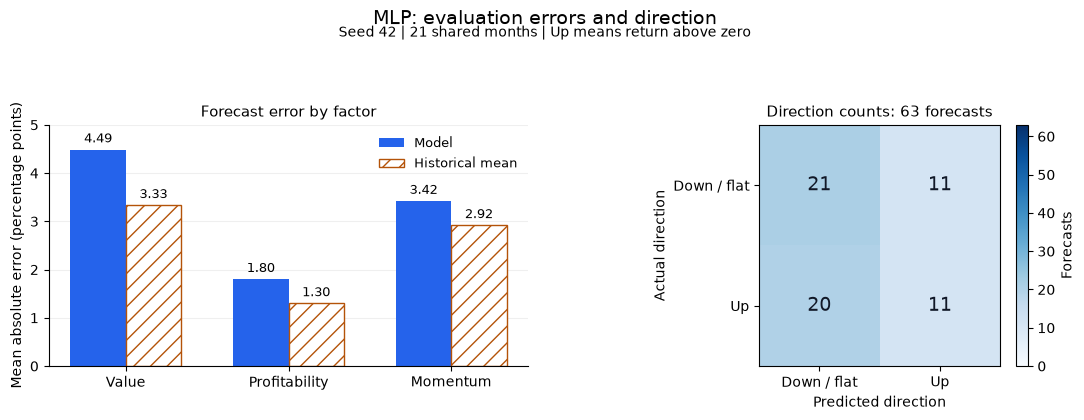

In [46]:
plot_model = "MLP"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "mlp_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "mlp_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

LSTM

In [47]:
MIN_TRAINING = 36
model_seeds = [42, 7, 21, 84, 123]
hidden_units = 32
layers = 2
dropout = 0.1
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    lstm_rows = []
    lstm_training_rows = []
    lstm_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1]
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )

        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, "exit"].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError("Too few completed fitting months for the LSTM.")

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(
            fitting_x.shape
        )
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(
            validation_x.shape
        )
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
        validation_targets = torch.tensor(
            target_scaler.transform(validation_y), dtype=torch.float32
        )
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

        lstm = nn.LSTM(
            input_size=features,
            hidden_size=hidden_units,
            num_layers=layers,
            dropout=dropout,
            batch_first=True,
        )
        output_layer = nn.Linear(hidden_units, len(FACTORS))
        optimizer = torch.optim.Adam(
            list(lstm.parameters()) + list(output_layer.parameters()),
            lr=learning_rate,
            weight_decay=weight_decay,
        )
        loss_function = nn.MSELoss()
        best_validation_loss = float("inf")
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            lstm.train()
            output_layer.train()
            optimizer.zero_grad()
            sequence_output, _ = lstm(inputs)
            fitted_returns = output_layer(sequence_output[:, -1, :])
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError("The LSTM fitting loss is not finite.")
            loss.backward()
            optimizer.step()

            lstm.eval()
            output_layer.eval()
            with torch.no_grad():
                validation_sequence, _ = lstm(validation_inputs)
                validation_returns = output_layer(validation_sequence[:, -1, :])
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError("The LSTM validation loss is not finite.")
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            lstm_epoch_rows.append(
                {
                    "signal": signal,
                    "split": split,
                    "epoch": epoch,
                    "training_loss": loss.item(),
                    "validation_loss": validation_loss,
                }
            )

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_lstm_weights = {
                    name: value.detach().clone() for name, value in lstm.state_dict().items()
                }
                best_output_weights = {
                    name: value.detach().clone()
                    for name, value in output_layer.state_dict().items()
                }
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        lstm.load_state_dict(best_lstm_weights)
        output_layer.load_state_dict(best_output_weights)
        lstm.eval()
        output_layer.eval()
        with torch.no_grad():
            prediction_sequence, _ = lstm(prediction_inputs)
            scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError("LSTM produced an invalid forecast.")

        lstm_training_rows.append(
            {
                "signal": signal,
                "split": split,
                "model": "LSTM",
                "first_loss": training_losses[0],
                "last_loss": training_losses[-1],
                "epochs_run": epoch,
                "best_epoch": best_epoch,
                "best_validation_loss": best_validation_loss,
                "fit_months": len(fitting_index),
                "internal_validation_months": len(validation_index),
                "fit_target_end": samples.loc[fitting_index, "exit"].max(),
                "internal_validation_start": validation_index[0],
                "internal_validation_end": samples.loc[validation_index, "exit"].max(),
            }
        )
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            lstm_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "LSTM",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    lstm_predictions = pd.DataFrame(lstm_rows)
    lstm_training = pd.DataFrame(lstm_training_rows)
    if not lstm_training.fit_target_end.le(lstm_training.internal_validation_start).all():
        raise ValueError("LSTM fitting targets overlap the internal validation decisions.")
    if not lstm_training.internal_validation_end.le(lstm_training.signal).all():
        raise ValueError("LSTM early stopping uses a return from after the forecast date.")
    print("LSTM | seed:", run_seed, "| monthly forecasts:", len(lstm_predictions) // 3)
    display(lstm_training[["signal", "epochs_run", "best_epoch", "best_validation_loss"]].tail())

    lstm_predictions.to_csv(MODEL_FILES / "lstm_predictions.csv", index=False)
    lstm_training.to_csv(MODEL_FILES / "lstm_training.csv", index=False)
    pd.DataFrame(lstm_epoch_rows).to_csv(MODEL_FILES / "lstm_epoch_losses.csv", index=False)
    lstm_audit = training_audit.assign(model="LSTM").merge(
        lstm_training.drop(columns=["split", "model"]), on="signal", validate="one_to_one"
    )
    lstm_audit.to_csv(MODEL_FILES / "lstm_audit.csv", index=False)
    model_audits.append(lstm_audit.assign(seed=run_seed))

    prediction_frames.append(lstm_predictions.assign(seed=run_seed))

LSTM | seed: 42 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,93,83,0.649
41,2026-05-29,11,1,0.725
42,2026-06-30,11,1,0.738
43,2026-07-31,11,1,0.797
44,2026-08-31,20,10,1.195


LSTM | seed: 7 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,100,100,0.633
41,2026-05-29,100,100,0.675
42,2026-06-30,100,100,0.711
43,2026-07-31,79,69,0.827
44,2026-08-31,93,83,1.168


LSTM | seed: 21 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,96,86,0.620
41,2026-05-29,17,7,0.711
42,2026-06-30,11,1,0.713
43,2026-07-31,11,1,0.783
44,2026-08-31,12,2,1.171


LSTM | seed: 84 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,89,79,0.654
41,2026-05-29,96,86,0.686
42,2026-06-30,97,87,0.706
43,2026-07-31,97,87,0.812
44,2026-08-31,85,75,1.168


LSTM | seed: 123 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,22,12,0.664
41,2026-05-29,100,100,0.665
42,2026-06-30,23,13,0.745
43,2026-07-31,25,15,0.822
44,2026-08-31,16,6,1.185


LSTM: forecasts

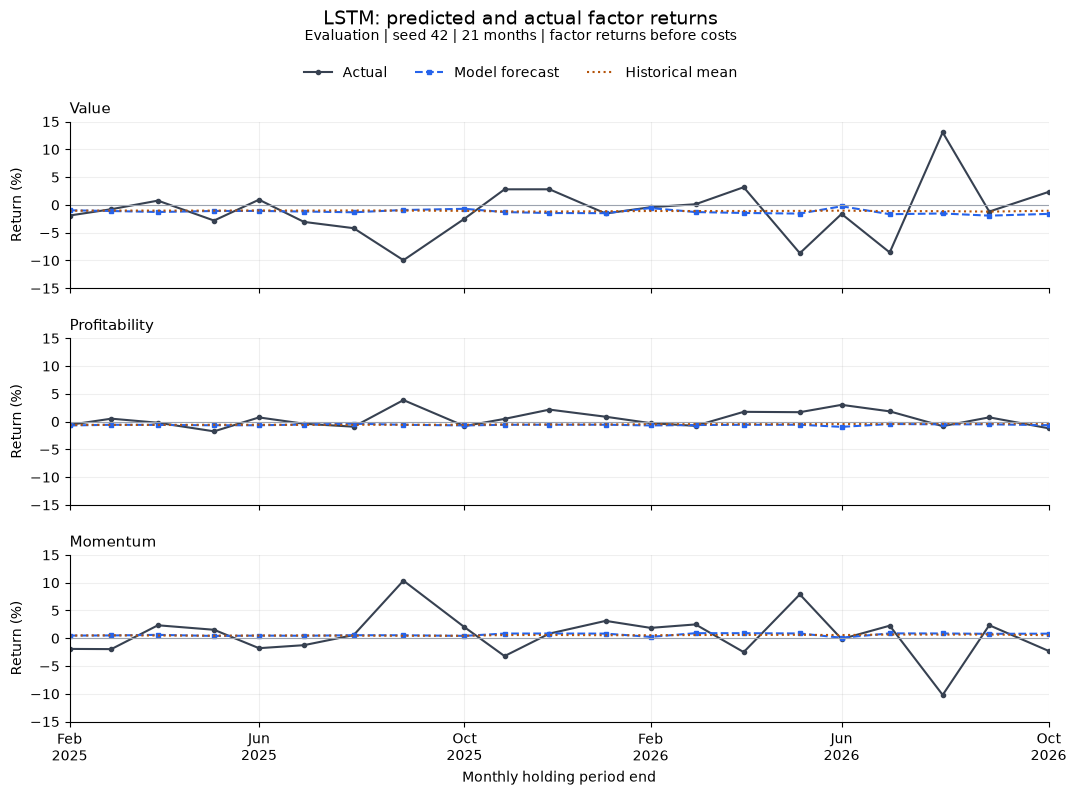

In [48]:
plot_model = "LSTM"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lstm_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "lstm_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

LSTM: errors and direction

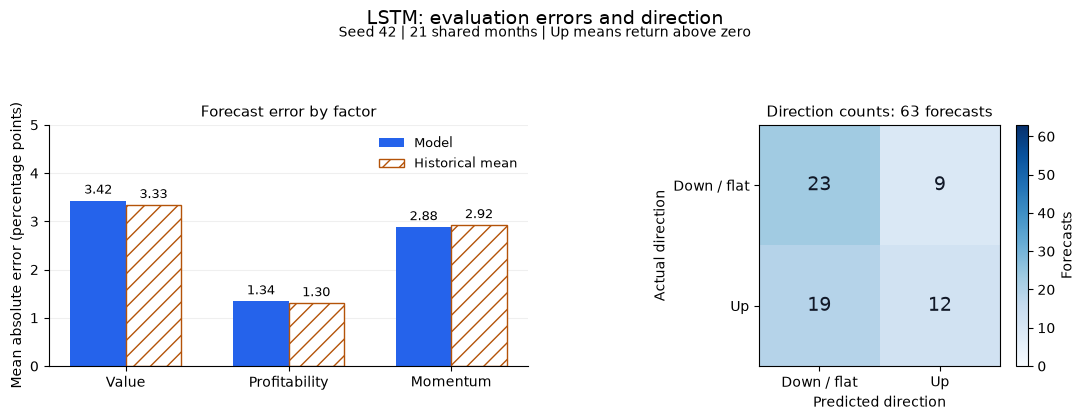

In [49]:
plot_model = "LSTM"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lstm_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "lstm_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

LSTM: training

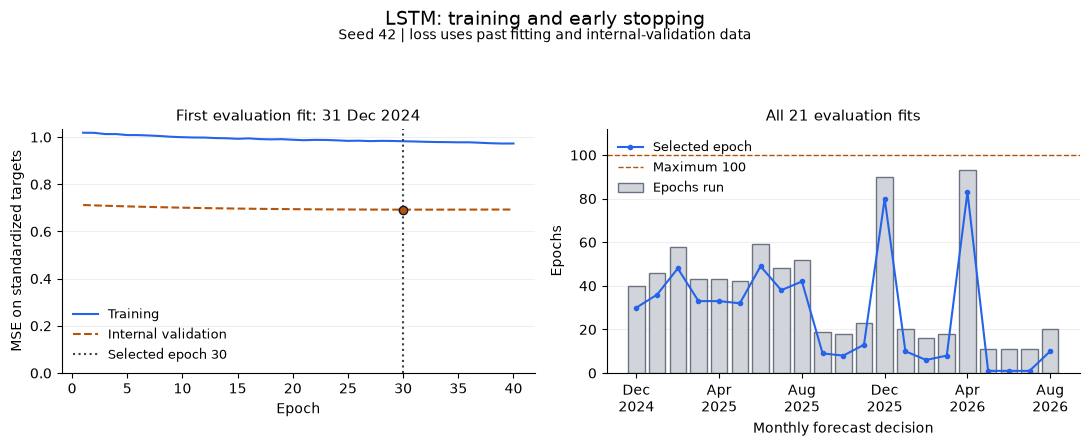

In [50]:
plot_model = "LSTM"
plot_seed = 42
epoch_limit = 100
training_color = "#2563eb"
validation_color = "#b45309"
figure_folder = RESULTS / "model_charts"

epoch_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lstm_epoch_losses.csv", parse_dates=["signal"]
)
training_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "lstm_training.csv", parse_dates=["signal"]
)
evaluation_training = training_history.loc[training_history.split.eq("evaluation")].sort_values(
    "signal"
)
example_fit = evaluation_training.iloc[0]
example_epochs = epoch_history.loc[epoch_history.signal.eq(example_fit.signal)].sort_values("epoch")
chosen_epoch = int(example_fit.best_epoch)
chosen_loss = float(example_fit.best_validation_loss)
if len(example_epochs) != int(example_fit.epochs_run):
    raise ValueError("The training curve does not match the saved epoch count.")
if not np.isclose(
    example_epochs.set_index("epoch").loc[chosen_epoch, "validation_loss"], chosen_loss
):
    raise ValueError("The saved selected epoch does not match its validation loss.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(
    example_epochs.epoch, example_epochs.training_loss, color=training_color, label="Training"
)
axes[0].plot(
    example_epochs.epoch,
    example_epochs.validation_loss,
    color=validation_color,
    linestyle="--",
    label="Internal validation",
)
axes[0].axvline(
    chosen_epoch, color="#374151", linestyle=":", label="Selected epoch " + str(chosen_epoch)
)
axes[0].scatter(
    [chosen_epoch], [chosen_loss], color=validation_color, edgecolor="#111827", zorder=3
)
axes[0].set_title("First evaluation fit: " + example_fit.signal.strftime("%d %b %Y"), fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on standardized targets")
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9)

fit_positions = np.arange(len(evaluation_training))
axes[1].bar(
    fit_positions,
    evaluation_training.epochs_run,
    color="#d1d5db",
    edgecolor="#6b7280",
    label="Epochs run",
)
axes[1].plot(
    fit_positions,
    evaluation_training.best_epoch,
    color=training_color,
    marker="o",
    markersize=3,
    label="Selected epoch",
)
axes[1].axhline(
    epoch_limit, color=validation_color, linestyle="--", linewidth=1, label="Maximum 100"
)
fit_ticks = sorted(set([0, *range(4, len(fit_positions), 4), len(fit_positions) - 1]))
axes[1].set_xticks(fit_ticks, evaluation_training.signal.iloc[fit_ticks].dt.strftime("%b\n%Y"))
axes[1].set_ylim(0, 112)
axes[1].set_xlabel("Monthly forecast decision")
axes[1].set_ylabel("Epochs")
axes[1].set_title("All 21 evaluation fits", fontsize=11)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
for plot_axis in axes:
    plot_axis.grid(axis="y", alpha=0.2)
    plot_axis.set_axisbelow(True)
    plot_axis.spines[["top", "right"]].set_visible(False)
figure.suptitle(plot_model + ": training and early stopping", fontsize=14)
figure.text(
    0.5,
    0.915,
    "Seed 42 | loss uses past fitting and internal-validation data",
    ha="center",
    fontsize=10,
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "lstm_training.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

GRU

In [51]:
MIN_TRAINING = 36
model_seeds = [42, 7, 21, 84, 123]
hidden_units = 32
layers = 2
dropout = 0.1
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    gru_rows = []
    gru_training_rows = []
    gru_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1]
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )

        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, "exit"].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError("Too few completed fitting months for the GRU.")

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(
            fitting_x.shape
        )
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(
            validation_x.shape
        )
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
        validation_targets = torch.tensor(
            target_scaler.transform(validation_y), dtype=torch.float32
        )
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

        gru = nn.GRU(
            input_size=features,
            hidden_size=hidden_units,
            num_layers=layers,
            dropout=dropout,
            batch_first=True,
        )
        output_layer = nn.Linear(hidden_units, len(FACTORS))
        optimizer = torch.optim.Adam(
            list(gru.parameters()) + list(output_layer.parameters()),
            lr=learning_rate,
            weight_decay=weight_decay,
        )
        loss_function = nn.MSELoss()
        best_validation_loss = float("inf")
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            gru.train()
            output_layer.train()
            optimizer.zero_grad()
            sequence_output, _ = gru(inputs)
            fitted_returns = output_layer(sequence_output[:, -1, :])
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError("The GRU fitting loss is not finite.")
            loss.backward()
            optimizer.step()

            gru.eval()
            output_layer.eval()
            with torch.no_grad():
                validation_sequence, _ = gru(validation_inputs)
                validation_returns = output_layer(validation_sequence[:, -1, :])
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError("The GRU validation loss is not finite.")
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            gru_epoch_rows.append(
                {
                    "signal": signal,
                    "split": split,
                    "epoch": epoch,
                    "training_loss": loss.item(),
                    "validation_loss": validation_loss,
                }
            )

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_gru_weights = {
                    name: value.detach().clone() for name, value in gru.state_dict().items()
                }
                best_output_weights = {
                    name: value.detach().clone()
                    for name, value in output_layer.state_dict().items()
                }
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        gru.load_state_dict(best_gru_weights)
        output_layer.load_state_dict(best_output_weights)
        gru.eval()
        output_layer.eval()
        with torch.no_grad():
            prediction_sequence, _ = gru(prediction_inputs)
            scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError("GRU produced an invalid forecast.")

        gru_training_rows.append(
            {
                "signal": signal,
                "split": split,
                "model": "GRU",
                "first_loss": training_losses[0],
                "last_loss": training_losses[-1],
                "epochs_run": epoch,
                "best_epoch": best_epoch,
                "best_validation_loss": best_validation_loss,
                "fit_months": len(fitting_index),
                "internal_validation_months": len(validation_index),
                "fit_target_end": samples.loc[fitting_index, "exit"].max(),
                "internal_validation_start": validation_index[0],
                "internal_validation_end": samples.loc[validation_index, "exit"].max(),
            }
        )
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            gru_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "GRU",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    gru_predictions = pd.DataFrame(gru_rows)
    gru_training = pd.DataFrame(gru_training_rows)
    if not gru_training.fit_target_end.le(gru_training.internal_validation_start).all():
        raise ValueError("GRU fitting targets overlap the internal validation decisions.")
    if not gru_training.internal_validation_end.le(gru_training.signal).all():
        raise ValueError("GRU early stopping uses a return from after the forecast date.")
    print("GRU | seed:", run_seed, "| monthly forecasts:", len(gru_predictions) // 3)
    display(gru_training[["signal", "epochs_run", "best_epoch", "best_validation_loss"]].tail())

    gru_predictions.to_csv(MODEL_FILES / "gru_predictions.csv", index=False)
    gru_training.to_csv(MODEL_FILES / "gru_training.csv", index=False)
    pd.DataFrame(gru_epoch_rows).to_csv(MODEL_FILES / "gru_epoch_losses.csv", index=False)
    gru_audit = training_audit.assign(model="GRU").merge(
        gru_training.drop(columns=["split", "model"]), on="signal", validate="one_to_one"
    )
    gru_audit.to_csv(MODEL_FILES / "gru_audit.csv", index=False)
    model_audits.append(gru_audit.assign(seed=run_seed))

    prediction_frames.append(gru_predictions.assign(seed=run_seed))

GRU | seed: 42 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,14,4,0.656
41,2026-05-29,12,2,0.714
42,2026-06-30,11,1,0.729
43,2026-07-31,11,1,0.795
44,2026-08-31,11,1,1.165


GRU | seed: 7 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,31,21,0.673
41,2026-05-29,58,48,0.693
42,2026-06-30,60,50,0.722
43,2026-07-31,27,17,0.820
44,2026-08-31,32,22,1.176


GRU | seed: 21 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,40,30,0.662
41,2026-05-29,39,29,0.681
42,2026-06-30,47,37,0.713
43,2026-07-31,22,12,0.800
44,2026-08-31,27,17,1.170


GRU | seed: 84 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,16,6,0.685
41,2026-05-29,67,57,0.705
42,2026-06-30,63,53,0.736
43,2026-07-31,13,3,0.823
44,2026-08-31,12,2,1.180


GRU | seed: 123 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,38,28,0.675
41,2026-05-29,67,57,0.708
42,2026-06-30,67,57,0.738
43,2026-07-31,36,26,0.846
44,2026-08-31,40,30,1.186


GRU: forecasts

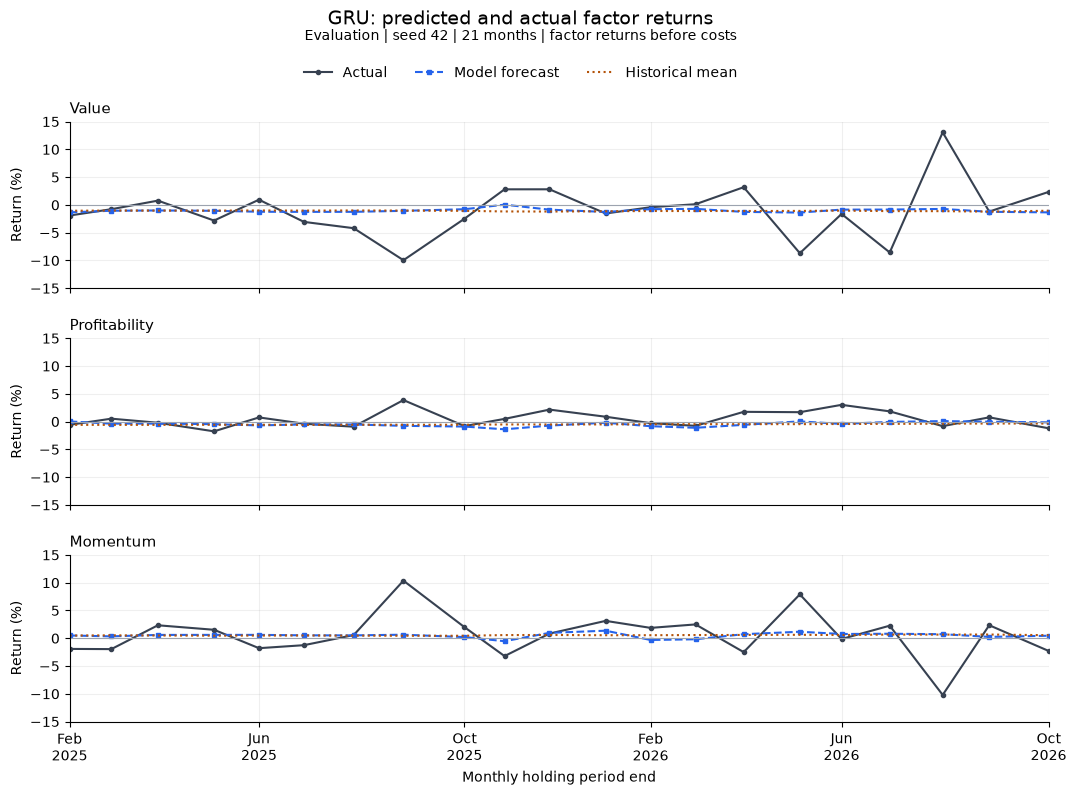

In [52]:
plot_model = "GRU"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "gru_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "gru_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

GRU: errors and direction

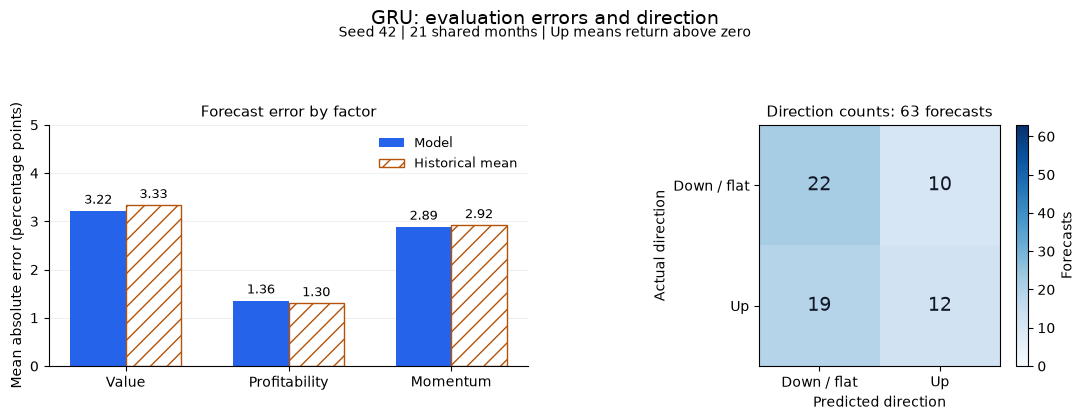

In [53]:
plot_model = "GRU"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "gru_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "gru_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

GRU: training

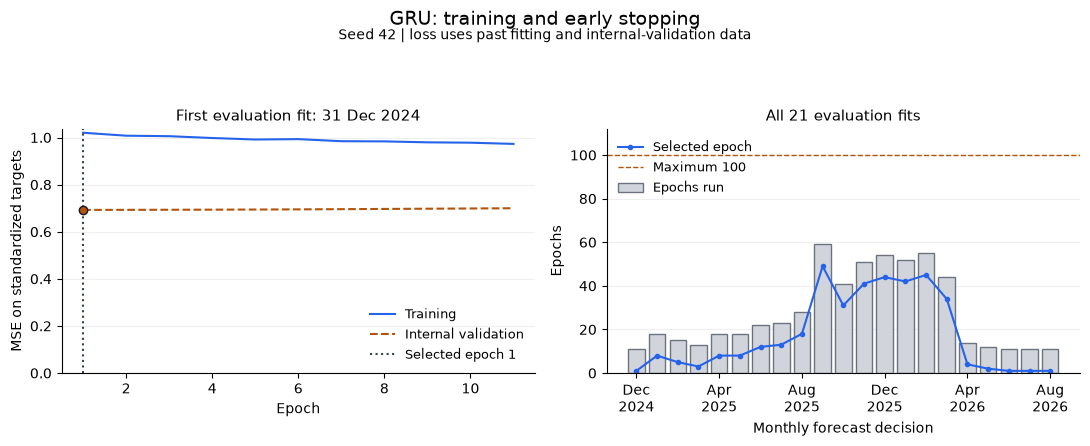

In [54]:
plot_model = "GRU"
plot_seed = 42
epoch_limit = 100
training_color = "#2563eb"
validation_color = "#b45309"
figure_folder = RESULTS / "model_charts"

epoch_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "gru_epoch_losses.csv", parse_dates=["signal"]
)
training_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "gru_training.csv", parse_dates=["signal"]
)
evaluation_training = training_history.loc[training_history.split.eq("evaluation")].sort_values(
    "signal"
)
example_fit = evaluation_training.iloc[0]
example_epochs = epoch_history.loc[epoch_history.signal.eq(example_fit.signal)].sort_values("epoch")
chosen_epoch = int(example_fit.best_epoch)
chosen_loss = float(example_fit.best_validation_loss)
if len(example_epochs) != int(example_fit.epochs_run):
    raise ValueError("The training curve does not match the saved epoch count.")
if not np.isclose(
    example_epochs.set_index("epoch").loc[chosen_epoch, "validation_loss"], chosen_loss
):
    raise ValueError("The saved selected epoch does not match its validation loss.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(
    example_epochs.epoch, example_epochs.training_loss, color=training_color, label="Training"
)
axes[0].plot(
    example_epochs.epoch,
    example_epochs.validation_loss,
    color=validation_color,
    linestyle="--",
    label="Internal validation",
)
axes[0].axvline(
    chosen_epoch, color="#374151", linestyle=":", label="Selected epoch " + str(chosen_epoch)
)
axes[0].scatter(
    [chosen_epoch], [chosen_loss], color=validation_color, edgecolor="#111827", zorder=3
)
axes[0].set_title("First evaluation fit: " + example_fit.signal.strftime("%d %b %Y"), fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on standardized targets")
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9)

fit_positions = np.arange(len(evaluation_training))
axes[1].bar(
    fit_positions,
    evaluation_training.epochs_run,
    color="#d1d5db",
    edgecolor="#6b7280",
    label="Epochs run",
)
axes[1].plot(
    fit_positions,
    evaluation_training.best_epoch,
    color=training_color,
    marker="o",
    markersize=3,
    label="Selected epoch",
)
axes[1].axhline(
    epoch_limit, color=validation_color, linestyle="--", linewidth=1, label="Maximum 100"
)
fit_ticks = sorted(set([0, *range(4, len(fit_positions), 4), len(fit_positions) - 1]))
axes[1].set_xticks(fit_ticks, evaluation_training.signal.iloc[fit_ticks].dt.strftime("%b\n%Y"))
axes[1].set_ylim(0, 112)
axes[1].set_xlabel("Monthly forecast decision")
axes[1].set_ylabel("Epochs")
axes[1].set_title("All 21 evaluation fits", fontsize=11)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
for plot_axis in axes:
    plot_axis.grid(axis="y", alpha=0.2)
    plot_axis.set_axisbelow(True)
    plot_axis.spines[["top", "right"]].set_visible(False)
figure.suptitle(plot_model + ": training and early stopping", fontsize=14)
figure.text(
    0.5,
    0.915,
    "Seed 42 | loss uses past fitting and internal-validation data",
    ha="center",
    fontsize=10,
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "gru_training.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

CNN

In [55]:
MIN_TRAINING = 36
model_seeds = [42, 7, 21, 84, 123]
filters = 8
kernel_size = 3
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    cnn_rows = []
    cnn_training_rows = []
    cnn_epoch_rows = []
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)

    for signal in run_signals:
        torch.manual_seed(seed)
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask]
        train_y = sample_y[training_mask]
        test_x = sample_x[position : position + 1]
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )

        validation_count = math.ceil(len(train_x) * validation_fraction)
        split_position = len(train_x) - validation_count
        validation_index = training_index[split_position:]
        fitting_index = training_index[:split_position]
        completed = samples.loc[fitting_index, "exit"].le(validation_index[0]).to_numpy()
        fitting_index = fitting_index[completed]
        fitting_x = train_x[:split_position][completed]
        fitting_y = train_y[:split_position][completed]
        validation_x = train_x[split_position:]
        validation_y = train_y[split_position:]
        if len(fitting_x) < MIN_TRAINING:
            raise ValueError("Too few completed fitting months for the CNN.")

        features = fitting_x.shape[-1]
        feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
        target_scaler = StandardScaler().fit(fitting_y)
        scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(
            fitting_x.shape
        )
        scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(
            validation_x.shape
        )
        scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
        inputs = torch.tensor(scaled_fit, dtype=torch.float32).transpose(1, 2)
        targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
        validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32).transpose(1, 2)
        validation_targets = torch.tensor(
            target_scaler.transform(validation_y), dtype=torch.float32
        )
        prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32).transpose(1, 2)

        cnn = nn.Sequential(
            nn.Conv1d(features, filters, kernel_size),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(filters, len(FACTORS)),
        )
        optimizer = torch.optim.Adam(cnn.parameters(), lr=learning_rate, weight_decay=weight_decay)
        loss_function = nn.MSELoss()
        best_validation_loss = float("inf")
        best_epoch = 0
        waiting = 0
        training_losses = []
        validation_losses = []

        for epoch in range(1, max_epochs + 1):
            cnn.train()
            optimizer.zero_grad()
            fitted_returns = cnn(inputs)
            loss = loss_function(fitted_returns, targets)
            if not torch.isfinite(loss):
                raise ValueError("The CNN fitting loss is not finite.")
            loss.backward()
            optimizer.step()

            cnn.eval()
            with torch.no_grad():
                validation_returns = cnn(validation_inputs)
                validation_loss = loss_function(validation_returns, validation_targets).item()
            if not np.isfinite(validation_loss):
                raise ValueError("The CNN validation loss is not finite.")
            training_losses.append(loss.item())
            validation_losses.append(validation_loss)
            cnn_epoch_rows.append(
                {
                    "signal": signal,
                    "split": split,
                    "epoch": epoch,
                    "training_loss": loss.item(),
                    "validation_loss": validation_loss,
                }
            )

            if validation_loss < best_validation_loss - minimum_improvement:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_weights = {
                    name: value.detach().clone() for name, value in cnn.state_dict().items()
                }
                waiting = 0
            else:
                waiting += 1
            if waiting >= patience:
                break

        cnn.load_state_dict(best_weights)
        cnn.eval()
        with torch.no_grad():
            scaled_forecast = cnn(prediction_inputs).numpy()
        forecast = target_scaler.inverse_transform(scaled_forecast)[0]
        if not np.isfinite(forecast).all():
            raise ValueError("CNN produced an invalid forecast.")

        cnn_training_rows.append(
            {
                "signal": signal,
                "split": split,
                "model": "CNN",
                "first_loss": training_losses[0],
                "last_loss": training_losses[-1],
                "epochs_run": epoch,
                "best_epoch": best_epoch,
                "best_validation_loss": best_validation_loss,
                "fit_months": len(fitting_index),
                "internal_validation_months": len(validation_index),
                "fit_target_end": samples.loc[fitting_index, "exit"].max(),
                "internal_validation_start": validation_index[0],
                "internal_validation_end": samples.loc[validation_index, "exit"].max(),
            }
        )
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            cnn_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "CNN",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": actual,
                }
            )

    cnn_predictions = pd.DataFrame(cnn_rows)
    cnn_training = pd.DataFrame(cnn_training_rows)
    if not cnn_training.fit_target_end.le(cnn_training.internal_validation_start).all():
        raise ValueError("CNN fitting targets overlap internal validation decisions.")
    if not cnn_training.internal_validation_end.le(cnn_training.signal).all():
        raise ValueError("CNN early stopping uses a future return.")
    cnn_predictions.to_csv(MODEL_FILES / "cnn_predictions.csv", index=False)
    cnn_training.to_csv(MODEL_FILES / "cnn_training.csv", index=False)
    pd.DataFrame(cnn_epoch_rows).to_csv(MODEL_FILES / "cnn_epoch_losses.csv", index=False)
    cnn_audit = training_audit.assign(model="CNN").merge(
        cnn_training.drop(columns=["split", "model"]), on="signal", validate="one_to_one"
    )
    cnn_audit.to_csv(MODEL_FILES / "cnn_audit.csv", index=False)
    model_audits.append(cnn_audit.assign(seed=run_seed))
    print("CNN | seed:", run_seed, "| monthly forecasts:", len(cnn_predictions) // 3)
    display(cnn_training[["signal", "epochs_run", "best_epoch", "best_validation_loss"]].tail())

    prediction_frames.append(cnn_predictions.assign(seed=run_seed))

CNN | seed: 42 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,100,100,0.716
41,2026-05-29,92,82,0.763
42,2026-06-30,93,83,0.790
43,2026-07-31,62,52,0.865
44,2026-08-31,100,100,1.255


CNN | seed: 7 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,65,55,0.649
41,2026-05-29,60,50,0.680
42,2026-06-30,52,42,0.693
43,2026-07-31,35,25,0.772
44,2026-08-31,90,80,1.125


CNN | seed: 21 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,78,68,0.648
41,2026-05-29,100,100,0.657
42,2026-06-30,100,93,0.681
43,2026-07-31,66,56,0.788
44,2026-08-31,62,52,1.176


CNN | seed: 84 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,97,87,0.624
41,2026-05-29,89,79,0.682
42,2026-06-30,95,85,0.695
43,2026-07-31,70,60,0.803
44,2026-08-31,93,83,1.128


CNN | seed: 123 | monthly forecasts: 45


,signal,epochs_run,best_epoch,best_validation_loss
40,2026-04-30,75,65,0.651
41,2026-05-29,100,94,0.699
42,2026-06-30,97,87,0.720
43,2026-07-31,36,26,0.824
44,2026-08-31,45,35,1.160


CNN: forecasts

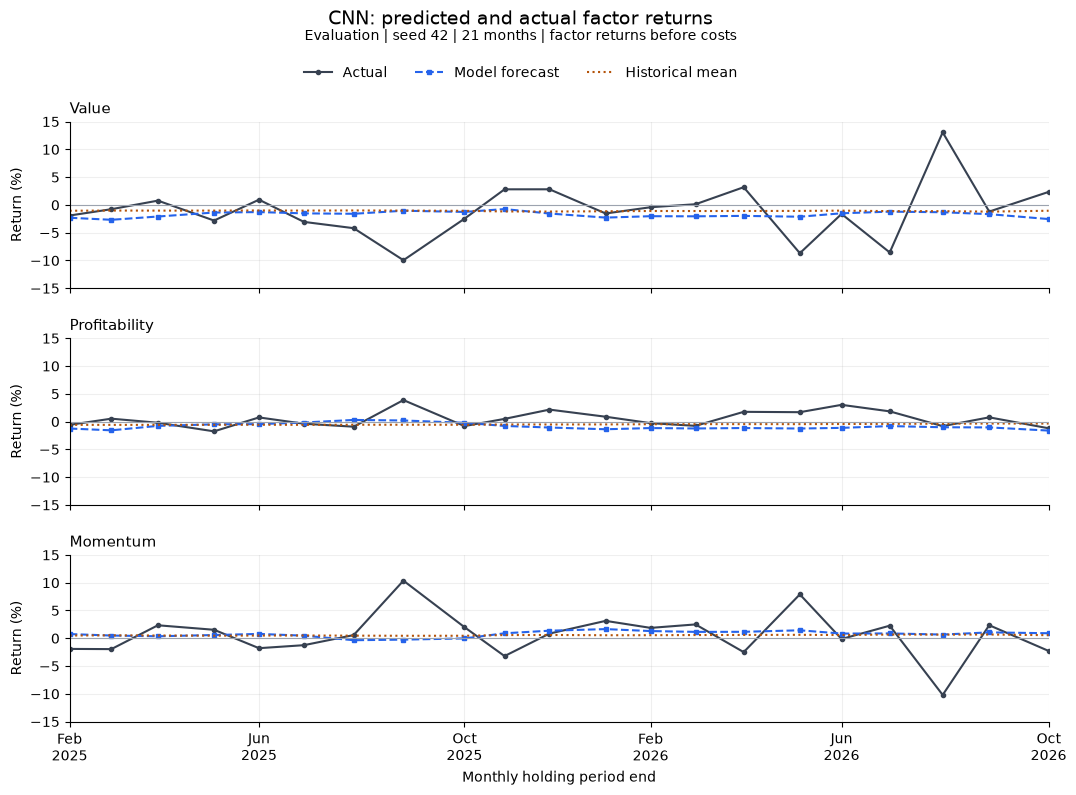

In [56]:
plot_model = "CNN"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "cnn_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "cnn_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

CNN: errors and direction

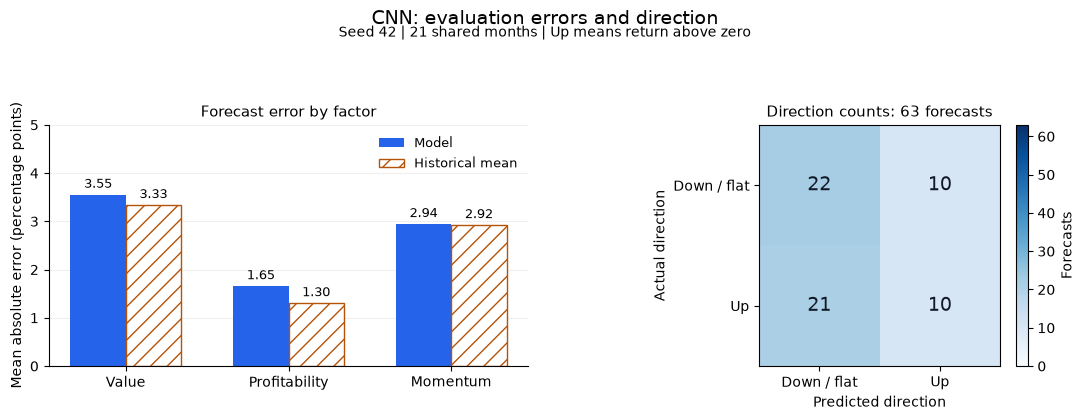

In [57]:
plot_model = "CNN"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "cnn_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "cnn_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

CNN: training

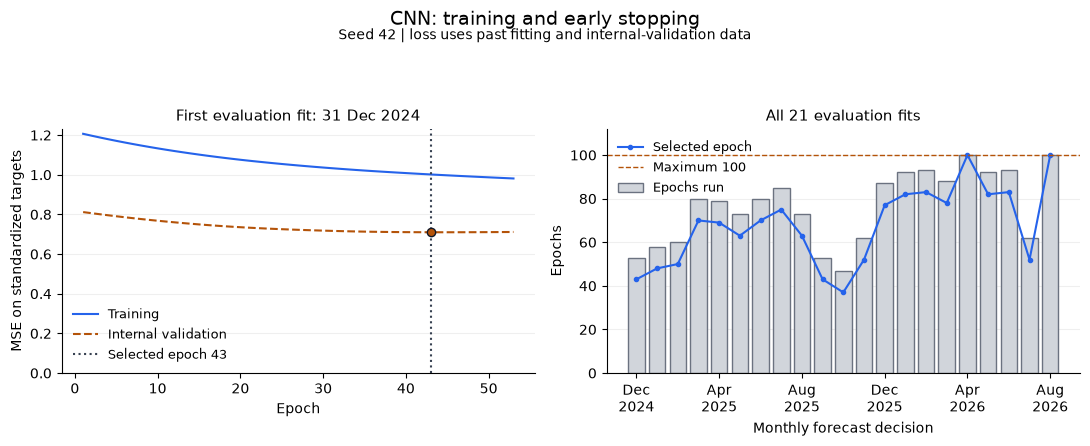

In [58]:
plot_model = "CNN"
plot_seed = 42
epoch_limit = 100
training_color = "#2563eb"
validation_color = "#b45309"
figure_folder = RESULTS / "model_charts"

epoch_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "cnn_epoch_losses.csv", parse_dates=["signal"]
)
training_history = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "cnn_training.csv", parse_dates=["signal"]
)
evaluation_training = training_history.loc[training_history.split.eq("evaluation")].sort_values(
    "signal"
)
example_fit = evaluation_training.iloc[0]
example_epochs = epoch_history.loc[epoch_history.signal.eq(example_fit.signal)].sort_values("epoch")
chosen_epoch = int(example_fit.best_epoch)
chosen_loss = float(example_fit.best_validation_loss)
if len(example_epochs) != int(example_fit.epochs_run):
    raise ValueError("The training curve does not match the saved epoch count.")
if not np.isclose(
    example_epochs.set_index("epoch").loc[chosen_epoch, "validation_loss"], chosen_loss
):
    raise ValueError("The saved selected epoch does not match its validation loss.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(
    example_epochs.epoch, example_epochs.training_loss, color=training_color, label="Training"
)
axes[0].plot(
    example_epochs.epoch,
    example_epochs.validation_loss,
    color=validation_color,
    linestyle="--",
    label="Internal validation",
)
axes[0].axvline(
    chosen_epoch, color="#374151", linestyle=":", label="Selected epoch " + str(chosen_epoch)
)
axes[0].scatter(
    [chosen_epoch], [chosen_loss], color=validation_color, edgecolor="#111827", zorder=3
)
axes[0].set_title("First evaluation fit: " + example_fit.signal.strftime("%d %b %Y"), fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on standardized targets")
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9)

fit_positions = np.arange(len(evaluation_training))
axes[1].bar(
    fit_positions,
    evaluation_training.epochs_run,
    color="#d1d5db",
    edgecolor="#6b7280",
    label="Epochs run",
)
axes[1].plot(
    fit_positions,
    evaluation_training.best_epoch,
    color=training_color,
    marker="o",
    markersize=3,
    label="Selected epoch",
)
axes[1].axhline(
    epoch_limit, color=validation_color, linestyle="--", linewidth=1, label="Maximum 100"
)
fit_ticks = sorted(set([0, *range(4, len(fit_positions), 4), len(fit_positions) - 1]))
axes[1].set_xticks(fit_ticks, evaluation_training.signal.iloc[fit_ticks].dt.strftime("%b\n%Y"))
axes[1].set_ylim(0, 112)
axes[1].set_xlabel("Monthly forecast decision")
axes[1].set_ylabel("Epochs")
axes[1].set_title("All 21 evaluation fits", fontsize=11)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
for plot_axis in axes:
    plot_axis.grid(axis="y", alpha=0.2)
    plot_axis.set_axisbelow(True)
    plot_axis.spines[["top", "right"]].set_visible(False)
figure.suptitle(plot_model + ": training and early stopping", fontsize=14)
figure.text(
    0.5,
    0.915,
    "Seed 42 | loss uses past fitting and internal-validation data",
    ha="center",
    fontsize=10,
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "cnn_training.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Prophet

In [59]:
get_cmdstanpy_logger().setLevel(logging.WARNING)
model_seeds = [42]
changepoints = 10
changepoint_scale = 0.05

for run_seed in model_seeds:
    MODEL_FILES = RESULTS / "model_outputs" / str(run_seed)
    MODEL_FILES.mkdir(parents=True, exist_ok=True)
    seed = run_seed
    prophet_rows = []
    prophet_warnings = []
    logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
    logging.getLogger("prophet").setLevel(logging.WARNING)

    for signal in run_signals:
        training_mask = samples.exit.le(signal).to_numpy()
        training_index = sample_signals[training_mask]
        position = sample_signals.get_loc(signal)
        split = (
            "validation"
            if signal in validation_signals
            else ("evaluation" if signal in test_signals else "bridge")
        )
        target_month = (signal.to_period("M") + 1).to_timestamp("M")
        for factor in FACTORS:
            training = pd.DataFrame(
                {
                    "ds": (training_index.to_period("M") + 1).to_timestamp("M"),
                    "y": samples.loc[training_index, factor].to_numpy(),
                }
            )
            model = Prophet(
                yearly_seasonality=False,
                weekly_seasonality=False,
                daily_seasonality=False,
                n_changepoints=changepoints,
                changepoint_prior_scale=changepoint_scale,
                uncertainty_samples=0,
            )
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model.fit(training, seed=seed, show_console=False)
                forecast = model.predict(pd.DataFrame({"ds": [target_month]}))
            for warning in caught:
                prophet_warnings.append(
                    {"signal": signal, "model": "Prophet", "message": str(warning.message)}
                )
            value = float(forecast.yhat.iloc[0])
            if not np.isfinite(value):
                raise ValueError("Prophet produced an invalid forecast.")
            prophet_rows.append(
                {
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                    "split": split,
                    "model": "Prophet",
                    "factor": factor,
                    "predicted_return": value,
                    "actual_return": samples.loc[signal, factor],
                }
            )

    prophet_predictions = pd.DataFrame(prophet_rows)
    print("Prophet | seed:", run_seed, "| monthly forecasts:", len(prophet_predictions) // 3)
    prophet_predictions.to_csv(MODEL_FILES / "prophet_predictions.csv", index=False)
    pd.DataFrame(prophet_warnings, columns=["signal", "model", "message"]).to_csv(
        MODEL_FILES / "prophet_warnings.csv", index=False
    )
    prophet_audit = training_audit.assign(model="Prophet")
    prophet_audit.to_csv(MODEL_FILES / "prophet_audit.csv", index=False)
    model_audits.append(prophet_audit.assign(seed=run_seed))

    prediction_frames.append(prophet_predictions.assign(seed=run_seed))

Prophet | seed: 42 | monthly forecasts: 45


Prophet: forecasts

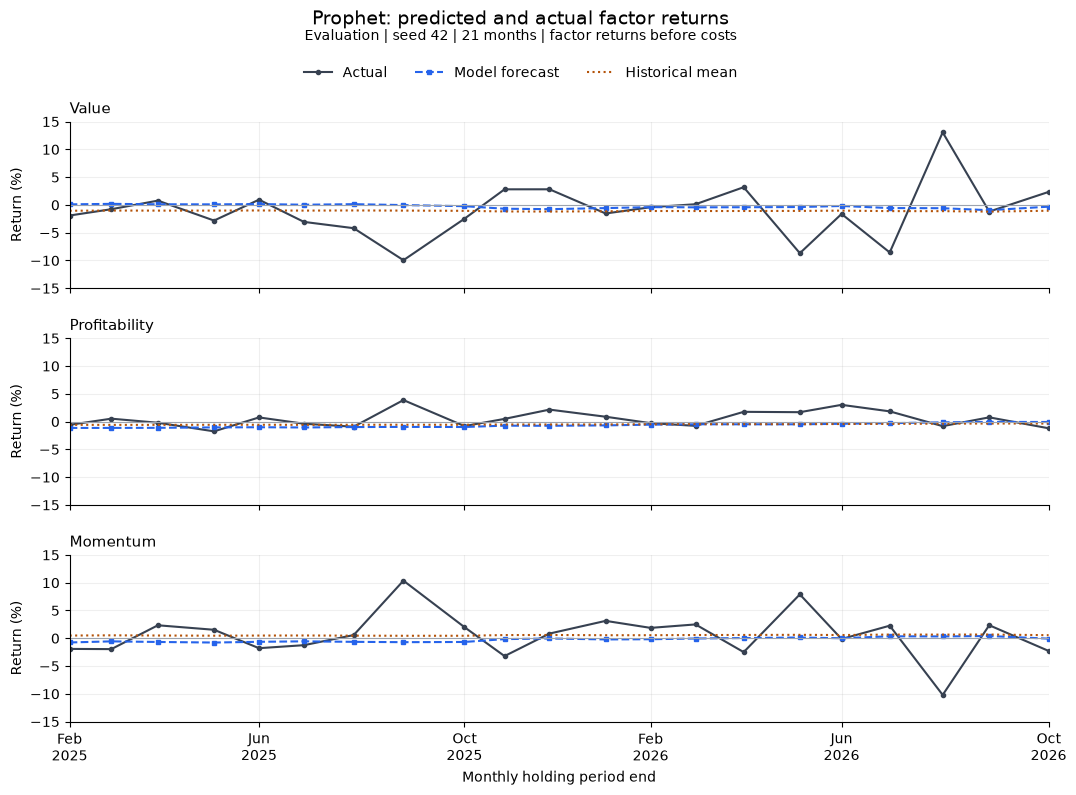

In [60]:
plot_model = "Prophet"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
actual_color = "#374151"
forecast_color = "#2563eb"
mean_color = "#b45309"
figure_folder = RESULTS / "model_charts"
figure_folder.mkdir(exist_ok=True)

plot_predictions = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "prophet_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
plot_predictions = plot_predictions.loc[plot_predictions.split.eq("evaluation")].copy()
mean_predictions = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv",
    parse_dates=["signal", "entry", "exit"],
)
mean_predictions = mean_predictions.loc[mean_predictions.split.eq("evaluation")]
plot_predictions = plot_predictions.merge(
    mean_predictions[["signal", "factor", "predicted_return"]].rename(
        columns={"predicted_return": "mean_forecast"}
    ),
    on=["signal", "factor"],
    validate="one_to_one",
)
if len(plot_predictions) != 63 or plot_predictions.signal.nunique() != 21:
    raise ValueError("The chart needs the same 21 evaluation months for all factors.")
plot_dates = pd.DatetimeIndex(sorted(plot_predictions.exit.unique()))
tick_dates = plot_dates[::4].union(plot_dates[-1:])
return_limit = max(
    15.0,
    5
    * np.ceil(
        np.abs(
            plot_predictions[["actual_return", "predicted_return", "mean_forecast"]].to_numpy()
        ).max()
        * 100
        / 5
    ),
)

figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for plot_axis, plot_factor in zip(axes, plot_factors):
    factor_plot = plot_predictions.loc[plot_predictions.factor.eq(plot_factor)].sort_values("exit")
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.actual_return * 100,
        color=actual_color,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label="Actual",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.predicted_return * 100,
        color=forecast_color,
        linestyle="--",
        marker="s",
        markersize=3,
        linewidth=1.5,
        label="Model forecast",
    )
    plot_axis.plot(
        factor_plot.exit,
        factor_plot.mean_forecast * 100,
        color=mean_color,
        linestyle=":",
        linewidth=1.5,
        label="Historical mean",
    )
    plot_axis.axhline(0, color="#9ca3af", linewidth=0.8)
    plot_axis.set_title(plot_factor, loc="left", fontsize=11)
    plot_axis.set_ylabel("Return (%)")
    plot_axis.set_ylim(-return_limit, return_limit)
    plot_axis.grid(alpha=0.2)
    plot_axis.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(tick_dates)
axes[-1].xaxis.set_major_formatter(DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Monthly holding period end")
axes[-1].set_xlim(plot_dates[0], plot_dates[-1])
figure.suptitle(plot_model + ": predicted and actual factor returns", fontsize=14, y=0.99)
figure.text(
    0.5,
    0.952,
    "Evaluation | seed 42 | 21 months | factor returns before costs",
    ha="center",
    fontsize=10,
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.935), ncol=3, frameon=False
)
figure.subplots_adjust(top=0.85, bottom=0.10, left=0.09, right=0.98, hspace=0.30)
figure.savefig(figure_folder / "prophet_forecasts.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Prophet: errors and direction

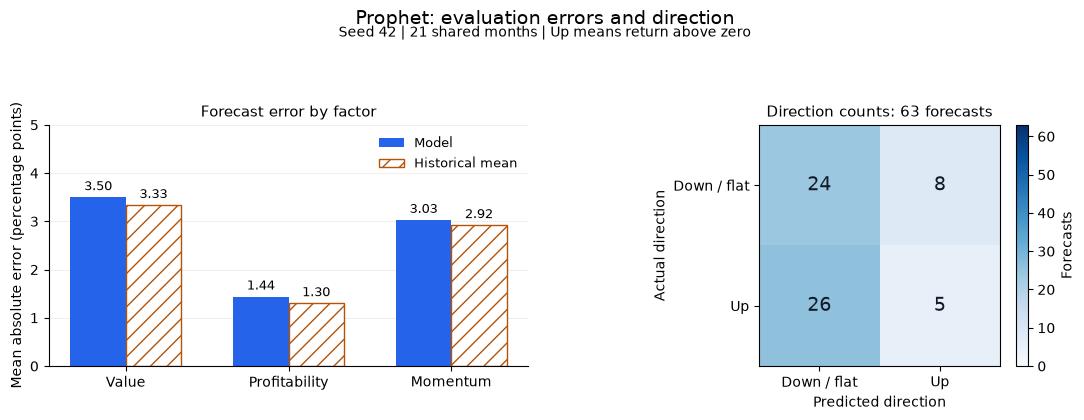

In [61]:
plot_model = "Prophet"
plot_seed = 42
plot_factors = ["Value", "Profitability", "Momentum"]
model_color = "#2563eb"
baseline_color = "#b45309"
bar_width = 0.34
figure_folder = RESULTS / "model_charts"

diagnostic_data = pd.read_csv(
    RESULTS / "model_outputs" / str(plot_seed) / "prophet_predictions.csv",
    parse_dates=["signal"],
)
diagnostic_data = diagnostic_data.loc[diagnostic_data.split.eq("evaluation")].copy()
diagnostic_mean = pd.read_csv(
    RESULTS / "model_outputs/historical_mean_predictions.csv", parse_dates=["signal"]
)
diagnostic_mean = diagnostic_mean.loc[diagnostic_mean.split.eq("evaluation")].copy()
diagnostic_data["absolute_error_pp"] = (
    diagnostic_data.predicted_return - diagnostic_data.actual_return
).abs() * 100
diagnostic_mean["absolute_error_pp"] = (
    diagnostic_mean.predicted_return - diagnostic_mean.actual_return
).abs() * 100
model_errors = diagnostic_data.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
mean_errors = diagnostic_mean.groupby("factor").absolute_error_pp.mean().reindex(plot_factors)
actual_up = diagnostic_data.actual_return.gt(0).to_numpy()
predicted_up = diagnostic_data.predicted_return.gt(0).to_numpy()
direction_counts = np.zeros((2, 2), dtype=int)
for actual_direction, predicted_direction in zip(actual_up, predicted_up):
    direction_counts[int(actual_direction), int(predicted_direction)] += 1
if direction_counts.sum() != 63:
    raise ValueError("The direction chart must contain all 63 factor forecasts.")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
factor_positions = np.arange(3)
model_bars = axes[0].bar(
    factor_positions - bar_width / 2,
    model_errors,
    width=bar_width,
    color=model_color,
    label="Model",
)
mean_bars = axes[0].bar(
    factor_positions + bar_width / 2,
    mean_errors,
    width=bar_width,
    facecolor="white",
    edgecolor=baseline_color,
    hatch="//",
    label="Historical mean",
)
axes[0].bar_label(model_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].bar_label(mean_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_xticks(factor_positions, plot_factors)
axes[0].set_ylim(0, max(5, np.ceil(max(model_errors.max(), mean_errors.max()) + 0.5)))
axes[0].set_ylabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error by factor", fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

heatmap = axes[1].imshow(direction_counts, cmap="Blues", vmin=0, vmax=63)
axes[1].set_xticks([0, 1], ["Down / flat", "Up"])
axes[1].set_yticks([0, 1], ["Down / flat", "Up"])
axes[1].set_xlabel("Predicted direction")
axes[1].set_ylabel("Actual direction")
axes[1].set_title("Direction counts: 63 forecasts", fontsize=11)
axes[1].grid(False)
for row_number in range(2):
    for column_number in range(2):
        count = direction_counts[row_number, column_number]
        axes[1].text(
            column_number,
            row_number,
            str(count),
            ha="center",
            va="center",
            fontsize=14,
            color="white" if count > 31 else "#111827",
        )
colorbar = figure.colorbar(heatmap, ax=axes[1], fraction=0.045, pad=0.04)
colorbar.set_label("Forecasts")
figure.suptitle(plot_model + ": evaluation errors and direction", fontsize=14)
figure.text(
    0.5, 0.915, "Seed 42 | 21 shared months | Up means return above zero", ha="center", fontsize=10
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(figure_folder / "prophet_diagnostics.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Collect all model forecasts

In [62]:
SEEDS = [42, 7, 21, 84, 123]

predictions_all_seeds = pd.concat(prediction_frames, ignore_index=True)
fixed_models = ["Historical mean", "Ridge", "Elastic Net", "KNN", "SVR", "Prophet"]
for run_seed in SEEDS[1:]:
    repeated = predictions_all_seeds.loc[
        predictions_all_seeds.seed.eq(42) & predictions_all_seeds.model.isin(fixed_models)
    ].copy()
    repeated["seed"] = run_seed
    predictions_all_seeds = pd.concat([predictions_all_seeds, repeated], ignore_index=True)
predictions_all_seeds = predictions_all_seeds.sort_values(["seed", "signal", "model", "factor"])
if (
    len(predictions_all_seeds) != 5 * 45 * 16 * 3
    or predictions_all_seeds.duplicated(["seed", "signal", "model", "factor"]).any()
):
    raise ValueError("Every seed needs every model and factor on all 45 dates.")
if not np.isfinite(predictions_all_seeds[["predicted_return", "actual_return"]].to_numpy()).all():
    raise ValueError("A forecast is not finite.")
predictions_all_seeds.to_csv(RESULTS / "predictions_all_seeds.csv", index=False)
predictions = (
    predictions_all_seeds.loc[predictions_all_seeds.seed.eq(42)].drop(columns="seed").copy()
)
predictions.to_csv(RESULTS / "predictions_all.csv", index=False)
evaluation_predictions = predictions.loc[predictions.split.eq("evaluation")].copy()
evaluation_predictions.to_csv(RESULTS / "predictions.csv", index=False)
pd.concat(model_audits, ignore_index=True).to_csv(RESULTS / "training_audit.csv", index=False)
library_versions = pd.DataFrame(
    [
        {"library": name, "version": version(name)}
        for name in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "torch", "prophet"]
    ]
)
library_versions.to_csv(RESULTS / "library_versions.csv", index=False)
print("Saved forecasts:", len(predictions_all_seeds))

Saved forecasts: 10800


Check the earlier forecasts

In [63]:
BASELINE = ROOT / "results/china_factor_timing_m6"

previous_predictions = pd.read_csv(BASELINE / "predictions_all.csv", parse_dates=["signal"])
matched = previous_predictions.merge(
    predictions, on=["signal", "model", "factor"], suffixes=("_m6", "_final"), validate="one_to_one"
)
maximum_difference = (matched.predicted_return_m6 - matched.predicted_return_final).abs().max()
if len(matched) != len(previous_predictions) or maximum_difference > 1e-8:
    raise ValueError("The main seed forecasts do not reproduce the M6 settings.")
pd.DataFrame(
    [{"matched_forecasts": len(matched), "maximum_absolute_difference": maximum_difference}]
).to_csv(RESULTS / "baseline_reproduction.csv", index=False)
print("Matched forecasts:", len(matched))
print("Largest forecast difference:", maximum_difference)

Matched forecasts: 2112
Largest forecast difference: 9.974659986866641e-17


Measure forecast accuracy

In [64]:
LEARNED_MODELS = [
    "Ridge",
    "Elastic Net",
    "KNN",
    "SVR",
    "Random Forest",
    "Extra Trees",
    "XGBoost",
    "Decision Tree",
    "AdaBoost",
    "LightGBM",
    "MLP",
    "LSTM",
    "GRU",
    "CNN",
    "Prophet",
]

metric_rows = []
for split in ["validation", "evaluation"]:
    for name in ["Historical mean"] + LEARNED_MODELS:
        frame = predictions.loc[predictions.split.eq(split) & predictions.model.eq(name)]
        actual = frame.pivot(index="signal", columns="factor", values="actual_return").reindex(
            columns=FACTORS
        )
        forecast = frame.pivot(index="signal", columns="factor", values="predicted_return").reindex(
            index=actual.index, columns=FACTORS
        )
        errors = forecast.to_numpy() - actual.to_numpy()
        metric_rows.append(
            {
                "model": name,
                "split": split,
                "months": len(actual),
                "mae_pp": np.abs(errors).mean() * 100,
                "direction_accuracy_pct": (
                    (forecast.to_numpy() > 0) == (actual.to_numpy() > 0)
                ).mean()
                * 100,
                "best_factor_hit_rate_pct": (
                    np.argmax(forecast.to_numpy(), axis=1) == np.argmax(actual.to_numpy(), axis=1)
                ).mean()
                * 100,
            }
        )
forecast_metrics = pd.DataFrame(metric_rows)
forecast_metrics.to_csv(RESULTS / "forecast_metrics.csv", index=False)
display(
    forecast_metrics.loc[forecast_metrics.split.eq("evaluation")].drop(columns="split").round(3)
)

,model,months,mae_pp,direction_accuracy_pct,best_factor_hit_rate_pct
16,Historical mean,21,2.517,55.556,52.381
17,Ridge,21,2.793,55.556,28.571
18,Elastic Net,21,2.784,57.143,23.810
19,KNN,21,2.537,55.556,52.381
20,SVR,21,2.626,49.206,38.095
21,Random Forest,21,2.577,52.381,47.619
22,Extra Trees,21,2.520,53.968,52.381
23,XGBoost,21,2.596,55.556,52.381
24,Decision Tree,21,2.890,36.508,23.810
25,AdaBoost,21,2.624,49.206,47.619


Set the past portfolio weights

In [65]:
SEEDS = [42, 7, 21, 84, 123]
LEARNED_MODELS = [
    "Ridge",
    "Elastic Net",
    "KNN",
    "SVR",
    "Random Forest",
    "Extra Trees",
    "XGBoost",
    "Decision Tree",
    "AdaBoost",
    "LightGBM",
    "MLP",
    "LSTM",
    "GRU",
    "CNN",
    "Prophet",
]

FACTOR_ALLOCATION = np.array([0.50, 0.30, 0.20])
targets_by_strategy = {}
shadow_factor_rows = []
shadow_stock_rows = []
for run_seed in SEEDS:
    seed_predictions = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(run_seed)]
    for model_name in ["Equal factors"] + LEARNED_MODELS:
        key = str(run_seed) + "|" + model_name
        targets_by_strategy[key] = {}
        for signal in run_signals:
            weights = pd.Series(1 / 3, index=FACTORS)
            if model_name != "Equal factors":
                forecast = (
                    seed_predictions.loc[
                        seed_predictions.signal.eq(signal) & seed_predictions.model.eq(model_name)
                    ]
                    .set_index("factor")
                    .predicted_return.reindex(FACTORS)
                )
                weights[:] = 0.0
                weights.loc[forecast.sort_values(ascending=False, kind="stable").index] = (
                    FACTOR_ALLOCATION
                )
            raw_target = (
                baskets[signal]
                .reindex(index=STOCKS, columns=FACTORS)
                .mul(weights, axis=1)
                .sum(axis=1)
            )
            target = raw_target / raw_target.abs().sum()
            if not np.isclose(target.sum(), 0, atol=1e-10) or not np.isclose(target.abs().sum(), 1):
                raise ValueError("A stock target has invalid exposure.")
            targets_by_strategy[key][signal] = target
            shadow_factor_rows.append(
                {"seed": run_seed, "signal": signal, "model": model_name, **weights.to_dict()}
            )
            for stock in STOCKS:
                shadow_stock_rows.append(
                    {"strategy": key, "signal": signal, "code": stock, "weight": target.loc[stock]}
                )
shadow_targets = targets_by_strategy
pd.DataFrame(shadow_factor_rows).to_csv(RESULTS / "shadow_factor_weights.csv", index=False)
SHADOW = RESULTS / "shadow"
SHADOW.mkdir(parents=True, exist_ok=True)
pd.DataFrame(shadow_stock_rows).to_csv(SHADOW / "stock_weights.csv", index=False)

print("Past portfolios:", len(targets_by_strategy))

Past portfolios: 80


Run the past portfolios after costs

In [66]:
shadow_signals = run_signals.copy()

INITIAL_BUDGET = 100000.0
TRADING_COST = 0.001
ANNUAL_BORROW_COST = 0.03
SIDE_EXPOSURE = 0.50
FEE_SOLVER_STEPS = 60
shadow_start = pd.Timestamp(samples.loc[shadow_signals[0], "entry"])
shadow_end = pd.Timestamp(samples.loc[shadow_signals[-1], "exit"])
base_date = calendar[calendar < shadow_start][-1]
simulation_dates = calendar[(calendar >= shadow_start) & (calendar <= shadow_end)]
price_array = prices.reindex(index=simulation_dates, columns=STOCKS).to_numpy(dtype=float)
trade_array = (
    tradable.reindex(index=simulation_dates, columns=STOCKS).fillna(False).to_numpy(dtype=bool)
)
signal_by_entry = {pd.Timestamp(samples.loc[signal, "entry"]): signal for signal in shadow_signals}
scenarios = [
    {
        "kind": "Main",
        "strategy": name,
        "trading_cost": TRADING_COST,
        "borrow_cost": ANNUAL_BORROW_COST,
    }
    for name in targets_by_strategy
]
curve_rows = []
exposure_rows = []
trade_rows = []
trade_detail_rows = []
holding_rows = []
monthly_rows = []
annual_rows = []
statistics_rows = []
scenario_curves = []

for scenario_number, scenario in enumerate(scenarios):
    strategy = scenario["strategy"]
    trading_rate = scenario["trading_cost"]
    borrow_rate = scenario["borrow_cost"]
    is_main = scenario["kind"] == "Main"
    units = np.zeros(len(STOCKS), dtype=float)
    cash = INITIAL_BUDGET
    previous_date = base_date
    previous_short_value = 0.0
    trading_cost_total = 0.0
    borrow_cost_total = 0.0
    traded_notional_total = 0.0
    turnover_total = 0.0
    local_curve = [
        {
            "date": base_date,
            "value": INITIAL_BUDGET,
            "cash": INITIAL_BUDGET,
            "gross": 0.0,
            "net": 0.0,
        }
    ]
    pretrade_values = {}

    for day_number, date in enumerate(simulation_dates):
        quote = price_array[day_number]
        active_position = np.abs(units) > 1e-12
        if np.any(active_position & (~np.isfinite(quote) | (quote <= 0))):
            raise ValueError("An existing position has no valid price for valuation.")
        safe_quote = np.where(np.isfinite(quote) & (quote > 0), quote, 0.0)
        current_market = units * safe_quote
        elapsed_days = (date - previous_date).days
        borrow_fee = previous_short_value * borrow_rate * elapsed_days / 365
        cash -= borrow_fee
        borrow_cost_total += borrow_fee
        nav_before_trade = float(cash + current_market.sum())
        if not np.isfinite(nav_before_trade) or nav_before_trade <= 0:
            raise ValueError("The simulated portfolio has no positive capital left.")
        pretrade_values[date] = nav_before_trade
        trading_fee = 0.0

        if date in signal_by_entry:
            signal = signal_by_entry[date]
            target = targets_by_strategy[strategy][signal].reindex(STOCKS).to_numpy(dtype=float)
            can_trade = trade_array[day_number] & (safe_quote > 0)
            frozen = ~can_trade
            frozen_values = np.where(frozen, current_market, 0.0)
            frozen_long = float(np.maximum(frozen_values, 0).sum())
            frozen_short = float(-np.minimum(frozen_values, 0).sum())
            long_ratio = np.where(can_trade & (target > 0), target, 0.0)
            short_ratio = np.where(can_trade & (target < 0), -target, 0.0)
            if long_ratio.sum() > 0:
                long_ratio = long_ratio / long_ratio.sum()
            if short_ratio.sum() > 0:
                short_ratio = short_ratio / short_ratio.sum()

            lower_capital = 0.0
            upper_capital = nav_before_trade
            for fee_step in range(FEE_SOLVER_STEPS):
                trial_capital = (lower_capital + upper_capital) / 2
                long_budget = max(SIDE_EXPOSURE * trial_capital - frozen_long, 0.0)
                short_budget = max(SIDE_EXPOSURE * trial_capital - frozen_short, 0.0)
                desired_market = (
                    frozen_values + long_ratio * long_budget - short_ratio * short_budget
                )
                trade_market = desired_market - current_market
                trial_fee = trading_rate * np.abs(trade_market).sum()
                if trial_capital + trial_fee > nav_before_trade:
                    upper_capital = trial_capital
                else:
                    lower_capital = trial_capital

            capital_after_fee = (lower_capital + upper_capital) / 2
            long_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_long, 0.0)
            short_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_short, 0.0)
            desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
            trade_market = desired_market - current_market
            trading_fee = float(trading_rate * np.abs(trade_market).sum())
            traded_notional = float(np.abs(trade_market).sum())
            new_units = np.divide(
                desired_market, safe_quote, out=np.zeros_like(units), where=safe_quote > 0
            )
            new_units[frozen] = units[frozen]
            if np.any(np.abs(trade_market[frozen]) > 1e-8):
                raise ValueError("A stock traded without a valid quote.")
            cash -= float(trade_market.sum()) + trading_fee
            units = new_units
            current_market = units * safe_quote
            nav_after_trade = float(cash + current_market.sum())
            if not np.isclose(
                nav_after_trade, nav_before_trade - trading_fee, rtol=1e-10, atol=1e-7
            ):
                raise ValueError("Cash, holdings and trading fees do not reconcile.")
            if not np.isclose(nav_after_trade, capital_after_fee, rtol=1e-9, atol=1e-6):
                raise ValueError("The trading-fee calculation did not converge.")
            trading_cost_total += trading_fee
            traded_notional_total += traded_notional
            turnover_total += traded_notional / nav_before_trade
            if is_main:
                trade_rows.append(
                    {
                        "signal": signal,
                        "date": date,
                        "strategy": strategy,
                        "value_before_trade": nav_before_trade,
                        "value_after_trade": nav_after_trade,
                        "traded_notional": traded_notional,
                        "turnover": traded_notional / nav_before_trade,
                        "cost": trading_fee,
                        "frozen_long_value": frozen_long,
                        "frozen_short_value": frozen_short,
                        "gross_after_trade": np.abs(current_market).sum() / nav_after_trade,
                        "net_after_trade": current_market.sum() / nav_after_trade,
                        "unavailable_targets": int(np.sum(frozen & (np.abs(target) > 1e-12))),
                    }
                )
                for stock_number, stock in enumerate(STOCKS):
                    holding_rows.append(
                        {
                            "signal": signal,
                            "date": date,
                            "strategy": strategy,
                            "code": stock,
                            "target_weight": target[stock_number],
                            "actual_weight": current_market[stock_number] / nav_after_trade,
                            "market_value": current_market[stock_number],
                            "units": units[stock_number],
                            "tradable": bool(can_trade[stock_number]),
                        }
                    )
                    if abs(trade_market[stock_number]) > 1e-8:
                        trade_detail_rows.append(
                            {
                                "signal": signal,
                                "date": date,
                                "strategy": strategy,
                                "code": stock,
                                "signed_trade_value": trade_market[stock_number],
                                "cost": abs(trade_market[stock_number]) * trading_rate,
                            }
                        )

        nav = float(cash + current_market.sum())
        gross = float(np.abs(current_market).sum() / nav)
        net = float(current_market.sum() / nav)
        local_curve.append({"date": date, "value": nav, "cash": cash, "gross": gross, "net": net})
        if is_main:
            exposure_rows.append(
                {
                    "date": date,
                    "strategy": strategy,
                    "value": nav,
                    "cash": cash,
                    "long_value": np.maximum(current_market, 0).sum(),
                    "short_value": -np.minimum(current_market, 0).sum(),
                    "gross": gross,
                    "net": net,
                    "borrow_fee": borrow_fee,
                    "trading_fee": trading_fee,
                    "value_before_trade": nav_before_trade,
                }
            )
        previous_short_value = float(-np.minimum(current_market, 0).sum())
        previous_date = date

    curve = pd.DataFrame(local_curve).set_index("date")
    daily_returns = curve.value.pct_change(fill_method=None).dropna()
    years = (shadow_end - shadow_start).days / 365.25
    daily_standard_deviation = float(daily_returns.std(ddof=1))
    statistics = {
        "scenario": scenario_number,
        "kind": scenario["kind"],
        "strategy": strategy,
        "trading_cost_rate": trading_rate,
        "annual_borrow_cost_rate": borrow_rate,
        "start": shadow_start,
        "end": shadow_end,
        "initial_value": INITIAL_BUDGET,
        "final_value": curve.value.iloc[-1],
        "total_return": (curve.value.iloc[-1] / INITIAL_BUDGET - 1) * 100,
        "annual_return": ((curve.value.iloc[-1] / INITIAL_BUDGET) ** (1 / years) - 1) * 100,
        "volatility": daily_standard_deviation * np.sqrt(252) * 100,
        "sharpe": (
            float(daily_returns.mean() / daily_standard_deviation * np.sqrt(252))
            if daily_standard_deviation > 0
            else np.nan
        ),
        "drawdown": float((curve.value / curve.value.cummax() - 1).min() * 100),
        "trading_costs": trading_cost_total,
        "borrow_costs": borrow_cost_total,
        "traded_notional": traded_notional_total,
        "turnover": turnover_total,
        "average_monthly_turnover": turnover_total / len(shadow_signals),
        "average_gross": curve.gross.iloc[1:].mean(),
        "maximum_gross": curve.gross.iloc[1:].max(),
        "average_net": curve.net.iloc[1:].mean(),
        "maximum_absolute_net": curve.net.iloc[1:].abs().max(),
    }
    statistics_rows.append(statistics)
    scenario_curves.append(curve[["value"]].assign(scenario=scenario_number).reset_index())
    if is_main:
        curve_rows.append(curve[["value"]].assign(strategy=strategy).reset_index())
        for signal in shadow_signals:
            entry = pd.Timestamp(samples.loc[signal, "entry"])
            exit_date = pd.Timestamp(samples.loc[signal, "exit"])
            monthly_rows.append(
                {
                    "signal": signal,
                    "entry": entry,
                    "exit": exit_date,
                    "strategy": strategy,
                    "start_value_before_trade": pretrade_values[entry],
                    "end_value_before_next_trade": pretrade_values[exit_date],
                    "return": pretrade_values[exit_date] / pretrade_values[entry] - 1,
                }
            )
        previous_year_end = base_date
        for year in sorted(set(curve.index[curve.index >= shadow_start].year)):
            year_dates = curve.index[(curve.index.year == year) & (curve.index >= shadow_start)]
            year_end = year_dates[-1]
            year_curve = curve.loc[previous_year_end:year_end, "value"]
            annual_rows.append(
                {
                    "year": year,
                    "strategy": strategy,
                    "base": previous_year_end,
                    "first_observation": year_dates[0],
                    "end": year_end,
                    "total_return": (year_curve.iloc[-1] / year_curve.iloc[0] - 1) * 100,
                    "drawdown": (year_curve / year_curve.cummax() - 1).min() * 100,
                }
            )
            previous_year_end = year_end
print("Past portfolios completed:", len(statistics_rows))

Past portfolios completed: 80


Save the past portfolio returns

In [67]:
all_scenario_results = pd.DataFrame(statistics_rows)
performance = all_scenario_results.loc[all_scenario_results.kind.eq("Main")].copy()
portfolio_values = pd.concat(curve_rows, ignore_index=True).pivot(
    index="date", columns="strategy", values="value"
)
monthly_results = pd.DataFrame(monthly_rows)
annual_results = pd.DataFrame(annual_rows)
trade_history = pd.DataFrame(trade_rows)
daily_exposure = pd.DataFrame(exposure_rows)
portfolio_values.to_csv(SHADOW / "portfolio_values.csv", index_label="date")
performance.to_csv(SHADOW / "performance.csv", index=False)
monthly_results.to_csv(SHADOW / "monthly_returns.csv", index=False)
annual_results.to_csv(SHADOW / "annual_results.csv", index=False)
trade_history.to_csv(SHADOW / "trades.csv", index=False)
pd.DataFrame(trade_detail_rows).to_csv(SHADOW / "trade_log.csv", index=False)
pd.DataFrame(holding_rows).to_csv(SHADOW / "actual_stock_weights.csv", index=False)
daily_exposure.to_csv(SHADOW / "daily_exposure.csv", index=False)
all_scenario_results.to_csv(SHADOW / "scenario_results.csv", index=False)
pd.concat(scenario_curves, ignore_index=True).to_csv(SHADOW / "scenario_values.csv", index=False)


print("Shadow portfolios:", len(performance), "| completed months each:", len(shadow_signals))

shadow_monthly_results = monthly_results.copy()
shadow_trade_history = trade_history.copy()

Shadow portfolios: 80 | completed months each: 45


Choose a model every six months

In [68]:
SEEDS = [42, 7, 21, 84, 123]

SELECTION_DATES = pd.to_datetime(["2024-12-31", "2025-06-30", "2025-12-31", "2026-06-30"])
LOOKBACK_PERIODS = 18
SCORE_TOLERANCE = 1e-12
shadow_monthly = shadow_monthly_results.copy()
shadow_trades = shadow_trade_history.copy()
shadow_monthly[["seed", "model"]] = shadow_monthly.strategy.str.split("|", n=1, expand=True)
shadow_trades[["seed", "model"]] = shadow_trades.strategy.str.split("|", n=1, expand=True)
shadow_monthly["seed"] = shadow_monthly.seed.astype(int)
shadow_trades["seed"] = shadow_trades.seed.astype(int)
selection_rows = []
score_rows = []
window_rows = []
for run_seed in SEEDS:
    for selection_date in SELECTION_DATES:
        finished = (
            samples.loc[run_signals]
            .loc[samples.loc[run_signals].exit.le(selection_date)]
            .tail(LOOKBACK_PERIODS)
        )
        if len(finished) != LOOKBACK_PERIODS:
            raise ValueError("We need exactly eighteen completed expected periods.")
        expected = finished.index
        returns = (
            shadow_monthly.loc[
                shadow_monthly.seed.eq(run_seed) & shadow_monthly.signal.isin(expected)
            ]
            .pivot(index="signal", columns="model", values="return")
            .reindex(index=expected, columns=["Equal factors"] + LEARNED_MODELS)
        )
        turnovers = (
            shadow_trades.loc[shadow_trades.seed.eq(run_seed) & shadow_trades.signal.isin(expected)]
            .pivot(index="signal", columns="model", values="turnover")
            .reindex(index=expected, columns=LEARNED_MODELS)
        )
        if not np.isfinite(returns.to_numpy()).all() or not np.isfinite(turnovers.to_numpy()).all():
            raise ValueError("An expected candidate return or turnover is missing.")
        scores = returns[LEARNED_MODELS].sub(returns["Equal factors"], axis=0).mean()
        tied = scores.index[(scores - scores.max()).abs().le(SCORE_TOLERANCE)]
        tie_table = pd.DataFrame(
            {"model": tied, "turnover": turnovers[tied].mean().to_numpy()}
        ).sort_values(["turnover", "model"])
        selected = tie_table.iloc[0].model
        selection_rows.append(
            {
                "seed": run_seed,
                "selection_date": selection_date,
                "execution_date": samples.loc[selection_date, "entry"],
                "model": selected,
                "score": scores[selected],
                "lookback_count": len(expected),
                "first_entry": finished.entry.iloc[0],
                "last_completed_exit": finished.exit.iloc[-1],
            }
        )
        for name in LEARNED_MODELS:
            score_rows.append(
                {
                    "seed": run_seed,
                    "selection_date": selection_date,
                    "model": name,
                    "score": scores[name],
                    "mean_turnover": turnovers[name].mean(),
                    "lookback_count": len(expected),
                    "first_signal": expected[0],
                    "last_signal": expected[-1],
                    "last_exit": finished.exit.iloc[-1],
                    "selected": name == selected,
                }
            )
        for signal in expected:
            window_rows.append(
                {
                    "seed": run_seed,
                    "selection_date": selection_date,
                    "signal": signal,
                    "entry": samples.loc[signal, "entry"],
                    "exit": samples.loc[signal, "exit"],
                }
            )
selected_models = pd.DataFrame(selection_rows)
pd.DataFrame(score_rows).to_csv(RESULTS / "selection_scores.csv", index=False)
pd.DataFrame(window_rows).to_csv(RESULTS / "selection_windows.csv", index=False)
selected_models.to_csv(RESULTS / "selected_models_all_seeds.csv", index=False)
selected_models.loc[selected_models.seed.eq(42)].to_csv(RESULTS / "selection.csv", index=False)
display(selected_models.loc[selected_models.seed.eq(42)].drop(columns="seed"))

,selection_date,execution_date,model,score,lookback_count,first_entry,last_completed_exit
0,2024-12-31,2025-01-02,Extra Trees,0.001,18,2023-06-01,2024-12-02
1,2025-06-30,2025-07-01,KNN,0.004,18,2023-12-01,2025-06-03
2,2025-12-31,2026-01-05,GRU,0.005,18,2024-06-03,2025-12-01
3,2026-06-30,2026-07-01,GRU,0.007,18,2024-12-02,2026-06-01


Set the evaluation portfolio weights

In [69]:
SEEDS = [42, 7, 21, 84, 123]
FACTOR_ALLOCATION = np.array([0.50, 0.30, 0.20])

targets_by_strategy = {}
factor_weight_rows = []
target_stock_rows = []
for run_seed in SEEDS:
    seed_predictions = predictions_all_seeds.loc[predictions_all_seeds.seed.eq(run_seed)]
    seed_selection = selected_models.loc[selected_models.seed.eq(run_seed)].set_index(
        "selection_date"
    )
    first_family = seed_selection.iloc[0].model
    first_forecast = (
        seed_predictions.loc[
            seed_predictions.signal.eq(test_signals[0]) & seed_predictions.model.eq(first_family)
        ]
        .set_index("factor")
        .predicted_return.reindex(FACTORS)
    )
    fixed_mix = pd.Series(0.0, index=FACTORS)
    fixed_mix.loc[first_forecast.sort_values(ascending=False, kind="stable").index] = (
        FACTOR_ALLOCATION
    )
    names = ["Six-month selector", "Equal factors", "Initial model family", "Initial factor mix"]
    if run_seed == 42:
        names += ["Historical mean"] + LEARNED_MODELS
    for name in names:
        key = str(run_seed) + "|" + name
        targets_by_strategy[key] = {}
        for signal in test_signals:
            current_family = seed_selection.loc[:signal].iloc[-1].model
            source_model = (
                current_family
                if name == "Six-month selector"
                else (first_family if name == "Initial model family" else name)
            )
            if name == "Equal factors":
                allocation = pd.Series(1 / 3, index=FACTORS)
            elif name == "Initial factor mix":
                allocation = fixed_mix.copy()
                source_model = first_family
            else:
                forecast = (
                    seed_predictions.loc[
                        seed_predictions.signal.eq(signal) & seed_predictions.model.eq(source_model)
                    ]
                    .set_index("factor")
                    .predicted_return.reindex(FACTORS)
                )
                if not np.isfinite(forecast).all():
                    raise ValueError("The selected model has no valid forecast.")
                allocation = pd.Series(0.0, index=FACTORS)
                allocation.loc[forecast.sort_values(ascending=False, kind="stable").index] = (
                    FACTOR_ALLOCATION
                )
            raw_target = (
                baskets[signal]
                .reindex(index=STOCKS, columns=FACTORS)
                .mul(allocation, axis=1)
                .sum(axis=1)
            )
            target = raw_target / raw_target.abs().sum()
            if not np.isclose(target.sum(), 0, atol=1e-10) or not np.isclose(target.abs().sum(), 1):
                raise ValueError("A combined portfolio has invalid target exposure.")
            targets_by_strategy[key][signal] = target
            factor_weight_rows.append(
                {
                    "seed": run_seed,
                    "strategy": name,
                    "signal": signal,
                    "selected_model": source_model,
                    **allocation.to_dict(),
                }
            )
            for stock in STOCKS:
                target_stock_rows.append(
                    {
                        "seed": run_seed,
                        "strategy": name,
                        "signal": signal,
                        "code": stock,
                        "weight": target.loc[stock],
                    }
                )
factor_weight_table = pd.DataFrame(factor_weight_rows)
factor_weight_table.to_csv(RESULTS / "factor_weights_all_seeds.csv", index=False)
factor_weight_table.loc[factor_weight_table.seed.eq(42)].to_csv(
    RESULTS / "factor_weights.csv", index=False
)
pd.DataFrame(target_stock_rows).to_csv(RESULTS / "stock_weights_all_seeds.csv", index=False)

print("Evaluation portfolios:", len(targets_by_strategy))

Evaluation portfolios: 36


Run the evaluation portfolios after costs

In [70]:
INITIAL_BUDGET = 100000.0
TRADING_COST = 0.001
ANNUAL_BORROW_COST = 0.03
SIDE_EXPOSURE = 0.50
FEE_SOLVER_STEPS = 60
evaluation_start = pd.Timestamp(samples.loc[test_signals[0], "entry"])
evaluation_end = pd.Timestamp(samples.loc[test_signals[-1], "exit"])
base_date = calendar[calendar < evaluation_start][-1]
simulation_dates = calendar[(calendar >= evaluation_start) & (calendar <= evaluation_end)]
price_array = prices.reindex(index=simulation_dates, columns=STOCKS).to_numpy(dtype=float)
trade_array = (
    tradable.reindex(index=simulation_dates, columns=STOCKS).fillna(False).to_numpy(dtype=bool)
)
signal_by_entry = {pd.Timestamp(samples.loc[signal, "entry"]): signal for signal in test_signals}
scenarios = [
    {
        "kind": "Main",
        "strategy": name,
        "trading_cost": TRADING_COST,
        "borrow_cost": ANNUAL_BORROW_COST,
    }
    for name in targets_by_strategy
]

comparison_names = [
    "Six-month selector",
    "Equal factors",
    "Initial model family",
    "Initial factor mix",
    "Prophet",
    "Historical mean",
]
for name in comparison_names:
    key = "42|" + name
    for rate in [0.0, 0.003]:
        scenarios.append(
            {
                "kind": "Trading cost",
                "strategy": key,
                "trading_cost": rate,
                "borrow_cost": ANNUAL_BORROW_COST,
            }
        )
    for rate in [0.0, 0.06]:
        scenarios.append(
            {
                "kind": "Borrow cost",
                "strategy": key,
                "trading_cost": TRADING_COST,
                "borrow_cost": rate,
            }
        )
curve_rows = []
exposure_rows = []
trade_rows = []
trade_detail_rows = []
holding_rows = []
monthly_rows = []
annual_rows = []
statistics_rows = []
scenario_curves = []

for scenario_number, scenario in enumerate(scenarios):
    strategy = scenario["strategy"]
    trading_rate = scenario["trading_cost"]
    borrow_rate = scenario["borrow_cost"]
    is_main = scenario["kind"] == "Main"
    units = np.zeros(len(STOCKS), dtype=float)
    cash = INITIAL_BUDGET
    previous_date = base_date
    previous_short_value = 0.0
    trading_cost_total = 0.0
    borrow_cost_total = 0.0
    traded_notional_total = 0.0
    turnover_total = 0.0
    local_curve = [
        {
            "date": base_date,
            "value": INITIAL_BUDGET,
            "cash": INITIAL_BUDGET,
            "gross": 0.0,
            "net": 0.0,
        }
    ]
    pretrade_values = {}

    for day_number, date in enumerate(simulation_dates):
        quote = price_array[day_number]
        active_position = np.abs(units) > 1e-12
        if np.any(active_position & (~np.isfinite(quote) | (quote <= 0))):
            raise ValueError("An existing position has no valid price for valuation.")
        safe_quote = np.where(np.isfinite(quote) & (quote > 0), quote, 0.0)
        current_market = units * safe_quote
        elapsed_days = (date - previous_date).days
        borrow_fee = previous_short_value * borrow_rate * elapsed_days / 365
        cash -= borrow_fee
        borrow_cost_total += borrow_fee
        nav_before_trade = float(cash + current_market.sum())
        if not np.isfinite(nav_before_trade) or nav_before_trade <= 0:
            raise ValueError("The simulated portfolio has no positive capital left.")
        pretrade_values[date] = nav_before_trade
        trading_fee = 0.0

        if date in signal_by_entry:
            signal = signal_by_entry[date]
            target = targets_by_strategy[strategy][signal].reindex(STOCKS).to_numpy(dtype=float)
            can_trade = trade_array[day_number] & (safe_quote > 0)
            frozen = ~can_trade
            frozen_values = np.where(frozen, current_market, 0.0)
            frozen_long = float(np.maximum(frozen_values, 0).sum())
            frozen_short = float(-np.minimum(frozen_values, 0).sum())
            long_ratio = np.where(can_trade & (target > 0), target, 0.0)
            short_ratio = np.where(can_trade & (target < 0), -target, 0.0)
            if long_ratio.sum() > 0:
                long_ratio = long_ratio / long_ratio.sum()
            if short_ratio.sum() > 0:
                short_ratio = short_ratio / short_ratio.sum()

            lower_capital = 0.0
            upper_capital = nav_before_trade
            for fee_step in range(FEE_SOLVER_STEPS):
                trial_capital = (lower_capital + upper_capital) / 2
                long_budget = max(SIDE_EXPOSURE * trial_capital - frozen_long, 0.0)
                short_budget = max(SIDE_EXPOSURE * trial_capital - frozen_short, 0.0)
                desired_market = (
                    frozen_values + long_ratio * long_budget - short_ratio * short_budget
                )
                trade_market = desired_market - current_market
                trial_fee = trading_rate * np.abs(trade_market).sum()
                if trial_capital + trial_fee > nav_before_trade:
                    upper_capital = trial_capital
                else:
                    lower_capital = trial_capital

            capital_after_fee = (lower_capital + upper_capital) / 2
            long_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_long, 0.0)
            short_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_short, 0.0)
            desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
            trade_market = desired_market - current_market
            trading_fee = float(trading_rate * np.abs(trade_market).sum())
            traded_notional = float(np.abs(trade_market).sum())
            new_units = np.divide(
                desired_market, safe_quote, out=np.zeros_like(units), where=safe_quote > 0
            )
            new_units[frozen] = units[frozen]
            if np.any(np.abs(trade_market[frozen]) > 1e-8):
                raise ValueError("A stock traded without a valid quote.")
            cash -= float(trade_market.sum()) + trading_fee
            units = new_units
            current_market = units * safe_quote
            nav_after_trade = float(cash + current_market.sum())
            if not np.isclose(
                nav_after_trade, nav_before_trade - trading_fee, rtol=1e-10, atol=1e-7
            ):
                raise ValueError("Cash, holdings and trading fees do not reconcile.")
            if not np.isclose(nav_after_trade, capital_after_fee, rtol=1e-9, atol=1e-6):
                raise ValueError("The trading-fee calculation did not converge.")
            trading_cost_total += trading_fee
            traded_notional_total += traded_notional
            turnover_total += traded_notional / nav_before_trade
            if is_main:
                trade_rows.append(
                    {
                        "signal": signal,
                        "date": date,
                        "strategy": strategy,
                        "value_before_trade": nav_before_trade,
                        "value_after_trade": nav_after_trade,
                        "traded_notional": traded_notional,
                        "turnover": traded_notional / nav_before_trade,
                        "cost": trading_fee,
                        "frozen_long_value": frozen_long,
                        "frozen_short_value": frozen_short,
                        "gross_after_trade": np.abs(current_market).sum() / nav_after_trade,
                        "net_after_trade": current_market.sum() / nav_after_trade,
                        "unavailable_targets": int(np.sum(frozen & (np.abs(target) > 1e-12))),
                    }
                )
                for stock_number, stock in enumerate(STOCKS):
                    holding_rows.append(
                        {
                            "signal": signal,
                            "date": date,
                            "strategy": strategy,
                            "code": stock,
                            "target_weight": target[stock_number],
                            "actual_weight": current_market[stock_number] / nav_after_trade,
                            "market_value": current_market[stock_number],
                            "units": units[stock_number],
                            "tradable": bool(can_trade[stock_number]),
                        }
                    )
                    if abs(trade_market[stock_number]) > 1e-8:
                        trade_detail_rows.append(
                            {
                                "signal": signal,
                                "date": date,
                                "strategy": strategy,
                                "code": stock,
                                "signed_trade_value": trade_market[stock_number],
                                "cost": abs(trade_market[stock_number]) * trading_rate,
                            }
                        )

        nav = float(cash + current_market.sum())
        gross = float(np.abs(current_market).sum() / nav)
        net = float(current_market.sum() / nav)
        local_curve.append({"date": date, "value": nav, "cash": cash, "gross": gross, "net": net})
        if is_main:
            exposure_rows.append(
                {
                    "date": date,
                    "strategy": strategy,
                    "value": nav,
                    "cash": cash,
                    "long_value": np.maximum(current_market, 0).sum(),
                    "short_value": -np.minimum(current_market, 0).sum(),
                    "gross": gross,
                    "net": net,
                    "borrow_fee": borrow_fee,
                    "trading_fee": trading_fee,
                    "value_before_trade": nav_before_trade,
                }
            )
        previous_short_value = float(-np.minimum(current_market, 0).sum())
        previous_date = date

    curve = pd.DataFrame(local_curve).set_index("date")
    daily_returns = curve.value.pct_change(fill_method=None).dropna()
    years = (evaluation_end - evaluation_start).days / 365.25
    daily_standard_deviation = float(daily_returns.std(ddof=1))
    statistics = {
        "scenario": scenario_number,
        "kind": scenario["kind"],
        "strategy": strategy,
        "trading_cost_rate": trading_rate,
        "annual_borrow_cost_rate": borrow_rate,
        "start": evaluation_start,
        "end": evaluation_end,
        "initial_value": INITIAL_BUDGET,
        "final_value": curve.value.iloc[-1],
        "total_return": (curve.value.iloc[-1] / INITIAL_BUDGET - 1) * 100,
        "annual_return": ((curve.value.iloc[-1] / INITIAL_BUDGET) ** (1 / years) - 1) * 100,
        "volatility": daily_standard_deviation * np.sqrt(252) * 100,
        "sharpe": (
            float(daily_returns.mean() / daily_standard_deviation * np.sqrt(252))
            if daily_standard_deviation > 0
            else np.nan
        ),
        "drawdown": float((curve.value / curve.value.cummax() - 1).min() * 100),
        "trading_costs": trading_cost_total,
        "borrow_costs": borrow_cost_total,
        "traded_notional": traded_notional_total,
        "turnover": turnover_total,
        "average_monthly_turnover": turnover_total / len(test_signals),
        "average_gross": curve.gross.iloc[1:].mean(),
        "maximum_gross": curve.gross.iloc[1:].max(),
        "average_net": curve.net.iloc[1:].mean(),
        "maximum_absolute_net": curve.net.iloc[1:].abs().max(),
    }
    statistics_rows.append(statistics)
    scenario_curves.append(curve[["value"]].assign(scenario=scenario_number).reset_index())
    if is_main:
        curve_rows.append(curve[["value"]].assign(strategy=strategy).reset_index())
        for signal in test_signals:
            entry = pd.Timestamp(samples.loc[signal, "entry"])
            exit_date = pd.Timestamp(samples.loc[signal, "exit"])
            monthly_rows.append(
                {
                    "signal": signal,
                    "entry": entry,
                    "exit": exit_date,
                    "strategy": strategy,
                    "start_value_before_trade": pretrade_values[entry],
                    "end_value_before_next_trade": pretrade_values[exit_date],
                    "return": pretrade_values[exit_date] / pretrade_values[entry] - 1,
                }
            )
        previous_year_end = base_date
        for year in sorted(set(curve.index[curve.index >= evaluation_start].year)):
            year_dates = curve.index[(curve.index.year == year) & (curve.index >= evaluation_start)]
            year_end = year_dates[-1]
            year_curve = curve.loc[previous_year_end:year_end, "value"]
            annual_rows.append(
                {
                    "year": year,
                    "strategy": strategy,
                    "base": previous_year_end,
                    "first_observation": year_dates[0],
                    "end": year_end,
                    "total_return": (year_curve.iloc[-1] / year_curve.iloc[0] - 1) * 100,
                    "drawdown": (year_curve / year_curve.cummax() - 1).min() * 100,
                }
            )
            previous_year_end = year_end
print("Portfolio and cost runs:", len(statistics_rows))

Portfolio and cost runs: 60


Save the evaluation returns and trades

In [71]:
all_scenario_results = pd.DataFrame(statistics_rows)
performance = all_scenario_results.loc[all_scenario_results.kind.eq("Main")].copy()
portfolio_values = pd.concat(curve_rows, ignore_index=True).pivot(
    index="date", columns="strategy", values="value"
)
monthly_results = pd.DataFrame(monthly_rows)
annual_results = pd.DataFrame(annual_rows)
trade_history = pd.DataFrame(trade_rows)
daily_exposure = pd.DataFrame(exposure_rows)
portfolio_values.to_csv(RESULTS / "portfolio_values.csv", index_label="date")
performance.to_csv(RESULTS / "performance.csv", index=False)
monthly_results.to_csv(RESULTS / "monthly_returns.csv", index=False)
annual_results.to_csv(RESULTS / "annual_results.csv", index=False)
trade_history.to_csv(RESULTS / "trades.csv", index=False)
pd.DataFrame(trade_detail_rows).to_csv(RESULTS / "trade_log.csv", index=False)
pd.DataFrame(holding_rows).to_csv(RESULTS / "actual_stock_weights.csv", index=False)
daily_exposure.to_csv(RESULTS / "daily_exposure.csv", index=False)
all_scenario_results.to_csv(RESULTS / "scenario_results.csv", index=False)
pd.concat(scenario_curves, ignore_index=True).to_csv(RESULTS / "scenario_values.csv", index=False)

print("Evaluation dates:", evaluation_start.date(), "to", evaluation_end.date())

Evaluation dates: 2025-01-02 to 2026-10-08


Compare the portfolios and training seeds

In [72]:
seed_folder = RESULTS / "seed_runs"
seed_folder.mkdir(parents=True, exist_ok=True)
for filename in [
    "performance",
    "monthly_returns",
    "annual_results",
    "trades",
    "trade_log",
    "actual_stock_weights",
    "daily_exposure",
    "scenario_results",
]:
    frame = pd.read_csv(RESULTS / (filename + ".csv"), dtype={"code": str})
    frame[["seed", "strategy"]] = frame.strategy.str.split("|", n=1, expand=True)
    frame["seed"] = frame.seed.astype(int)
    frame.to_csv(seed_folder / (filename + ".csv"), index=False)
    frame.loc[frame.seed.eq(42)].to_csv(RESULTS / (filename + ".csv"), index=False)
portfolio_values.to_csv(seed_folder / "portfolio_values.csv", index_label="date")
main_columns = [name for name in portfolio_values if name.startswith("42|")]
portfolio_values = portfolio_values[main_columns].copy()
portfolio_values.columns = [name.split("|", 1)[1] for name in main_columns]
portfolio_values.to_csv(RESULTS / "portfolio_values.csv", index_label="date")
performance = pd.read_csv(RESULTS / "performance.csv")
monthly_results = pd.read_csv(
    RESULTS / "monthly_returns.csv", parse_dates=["signal", "entry", "exit"]
)
all_performance = pd.read_csv(seed_folder / "performance.csv")
seed_results = all_performance.loc[all_performance.strategy.eq("Six-month selector")].copy()
seed_results.to_csv(RESULTS / "seed_results.csv", index=False)
scenario_results = pd.read_csv(RESULTS / "scenario_results.csv")
stress = scenario_results.loc[scenario_results.kind.ne("Main")].copy()
for kind in ["Trading cost", "Borrow cost"]:
    stress = pd.concat(
        [stress, performance.loc[performance.strategy.isin(comparison_names)].assign(kind=kind)],
        ignore_index=True,
    )
stress.to_csv(RESULTS / "cost_sensitivity.csv", index=False)
pd.DataFrame(target_stock_rows).query("seed == 42").to_csv(
    RESULTS / "stock_weights.csv", index=False
)
main_results = performance.set_index("strategy").loc[comparison_names]
display(
    main_results[
        ["annual_return", "sharpe", "drawdown", "final_value", "trading_costs", "borrow_costs"]
    ].round(3)
)
display(seed_results[["seed", "annual_return", "sharpe", "drawdown"]].round(3))

,annual_return,sharpe,drawdown,final_value,trading_costs,borrow_costs
strategy,,,,,,
Six-month selector,0.270,0.075,-10.093,"100,475.970","1,017.661","2,599.834"
Equal factors,-2.562,-0.420,-11.808,"95,526.548",812.987,"2,508.082"
Initial model family,1.713,0.263,-9.898,"103,039.591","1,025.547","2,639.145"
Initial factor mix,1.406,0.222,-9.898,"102,492.204",976.891,"2,632.850"
Prophet,-6.824,-0.916,-17.107,"88,283.496",897.266,"2,418.880"
Historical mean,1.406,0.222,-9.898,"102,492.204",976.891,"2,632.850"


,seed,annual_return,sharpe,drawdown
0,42,0.270,0.075,-10.093
20,7,-2.699,-0.347,-9.911
24,21,-0.535,-0.032,-10.505
28,84,0.619,0.124,-9.329
32,123,-0.929,-0.088,-9.329


Check uncertainty in the return difference

In [73]:
BOOTSTRAP_REPETITIONS = 10000
BOOTSTRAP_SEED = 20261025
EXPECTED_BLOCK_LENGTHS = [3, 2, 6]
monthly_wide = monthly_results.pivot(index="signal", columns="strategy", values="return").reindex(
    test_signals
)
paired = (monthly_wide["Six-month selector"] - monthly_wide["Equal factors"]).to_numpy()
if len(paired) != 21 or not np.isfinite(paired).all():
    raise ValueError("The bootstrap needs all 21 paired months.")
bootstrap_rows = []
for block_length in EXPECTED_BLOCK_LENGTHS:
    generator = np.random.default_rng(BOOTSTRAP_SEED)
    indices = np.empty((BOOTSTRAP_REPETITIONS, len(paired)), dtype=int)
    indices[:, 0] = generator.integers(0, len(paired), size=BOOTSTRAP_REPETITIONS)
    for step in range(1, len(paired)):
        restart = generator.random(BOOTSTRAP_REPETITIONS) < 1 / block_length
        fresh = generator.integers(0, len(paired), size=BOOTSTRAP_REPETITIONS)
        indices[:, step] = np.where(restart, fresh, (indices[:, step - 1] + 1) % len(paired))
    means = paired[indices].mean(axis=1) * 100
    low, high = np.quantile(means, [0.025, 0.975])
    bootstrap_rows.append(
        {
            "block_length": block_length,
            "mean_difference": paired.mean() * 100,
            "lower": low,
            "upper": high,
            "months": len(paired),
            "repetitions": BOOTSTRAP_REPETITIONS,
            "seed": BOOTSTRAP_SEED,
        }
    )
uncertainty = pd.DataFrame(bootstrap_rows)
uncertainty.to_csv(RESULTS / "uncertainty.csv", index=False)
display(uncertainty.round(4))
paired_table = monthly_results.loc[monthly_results.strategy.isin(comparison_names)].copy()
paired_table.to_csv(RESULTS / "comparison_monthly_returns.csv", index=False)

,block_length,mean_difference,lower,upper,months,repetitions,seed
0,3,0.248,-0.310,0.755,21,10000,20261025
1,2,0.248,-0.364,0.822,21,10000,20261025
2,6,0.248,-0.216,0.677,21,10000,20261025


Prepare other return and risk windows

In [74]:
WINDOW_LOOKBACK = 8
WINDOW_MIN_TRAINING = 36
WINDOW_OPTIONS = [
    ("1/4/13; risk13", (1, 4, 13), 13),
    ("1/3/12; risk12", (1, 3, 12), 12),
    ("1/6/26; risk26", (1, 6, 26), 26),
]
window_sequences = {}
window_dates = {}
window_availability = []
window_run_signals = validation_signals.append(test_signals)

for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    current_sequences = {}
    current_dates = {}
    for signal in sample_signals:
        history = factor_values.loc[:signal]
        weekly = history.groupby(history.index.to_period("W-FRI")).tail(1)
        if len(weekly) < WINDOW_LOOKBACK + max(max(return_windows), risk_weeks):
            continue
        changes = weekly.pct_change(fill_method=None)
        input_rows = []
        for week_number in range(len(weekly) - WINDOW_LOOKBACK, len(weekly)):
            weekly_values = {}
            risk_returns = changes.iloc[week_number - risk_weeks + 1 : week_number + 1]
            for factor in FACTORS:
                for return_weeks in return_windows:
                    weekly_values[f"{factor}_{return_weeks}w"] = (
                        weekly[factor].iloc[week_number]
                        / weekly[factor].iloc[week_number - return_weeks]
                        - 1
                    )
                weekly_values[f"{factor}_volatility"] = risk_returns[factor].std(ddof=1) * np.sqrt(
                    52
                )
            correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
            weekly_values["factor_correlation"] = float(correlations.mean())
            input_rows.append(weekly_values)
        frame = pd.DataFrame(input_rows, index=weekly.tail(WINDOW_LOOKBACK).index)
        if not np.isfinite(frame.to_numpy()).all():
            continue
        current_sequences[signal] = frame.to_numpy()
        current_dates[signal] = frame.index.max()
    window_sequences[window_name] = current_sequences
    window_dates[window_name] = current_dates
    window_availability.append(
        {
            "window": window_name,
            "available_samples": len(current_sequences),
            "first_available_signal": min(current_sequences),
            "last_available_signal": max(current_sequences),
        }
    )

common_window_signals = pd.DatetimeIndex(sample_signals)
for window_name, _, _ in WINDOW_OPTIONS:
    common_window_signals = common_window_signals.intersection(
        pd.DatetimeIndex(window_sequences[window_name])
    )
common_window_signals = common_window_signals.sort_values()
if not window_run_signals.isin(common_window_signals).all():
    raise ValueError("A window check is missing a required forecast month.")
window_samples = samples.loc[common_window_signals]
window_y = window_samples[FACTORS].to_numpy()
window_x = {}
for window_name, _, _ in WINDOW_OPTIONS:
    window_x[window_name] = np.stack(
        [window_sequences[window_name][signal] for signal in common_window_signals]
    )
for signal in window_run_signals:
    if int(window_samples.exit.le(signal).sum()) < WINDOW_MIN_TRAINING:
        raise ValueError("Too few common training months for the window check.")
window_coverage = pd.DataFrame(window_availability)
window_coverage["common_samples"] = len(common_window_signals)
window_coverage["first_common_signal"] = common_window_signals.min()
window_coverage["last_common_signal"] = common_window_signals.max()
window_coverage["validation_months"] = len(validation_signals)
window_coverage["evaluation_months"] = len(test_signals)
window_coverage.to_csv(RESULTS / "window_sensitivity_coverage.csv", index=False)
display(window_coverage)

,window,available_samples,first_available_signal,last_available_signal,common_samples,first_common_signal,last_common_signal,validation_months,evaluation_months
0,1/4/13; risk13,93,2018-12-28,2026-08-31,89,2019-04-30,2026-08-31,23,21
1,1/3/12; risk12,93,2018-12-28,2026-08-31,89,2019-04-30,2026-08-31,23,21
2,1/6/26; risk26,89,2019-04-30,2026-08-31,89,2019-04-30,2026-08-31,23,21


Ridge: return-window check

In [75]:
window_prediction_rows = []
window_audit_rows = []
window_warning_rows = []

alpha = 10.0

window_model_name = "Ridge"
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position : position + 1].reshape(1, -1)
        split = "validation" if signal in validation_signals else "evaluation"
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = Ridge(alpha=alpha)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "message": str(warning.message),
                }
            )
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("A window comparison forecast is not finite.")
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "entry": window_samples.loc[signal, "entry"],
                    "exit": window_samples.loc[signal, "exit"],
                    "split": split,
                    "factor": factor,
                    "predicted_return": predicted,
                    "actual_return": actual,
                }
            )
        window_audit_rows.append(
            {
                "window": window_name,
                "model": window_model_name,
                "signal": signal,
                "training_months": int(training_mask.sum()),
                "first_training_signal": common_window_signals[training_mask][0],
                "last_training_exit": window_samples.loc[training_mask, "exit"].max(),
                "last_input_week": window_dates[window_name][signal],
            }
        )
print(
    window_model_name
    + ": "
    + str(len(window_run_signals))
    + " months for each of the three window choices"
)

Ridge: 44 months for each of the three window choices


Random Forest: return-window check

In [76]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42

window_model_name = "Random Forest"
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position : position + 1].reshape(1, -1)
        split = "validation" if signal in validation_signals else "evaluation"
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = RandomForestRegressor(
            n_estimators=trees,
            max_depth=max_depth,
            min_samples_leaf=min_leaf,
            random_state=seed,
            n_jobs=2,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "message": str(warning.message),
                }
            )

        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("A window comparison forecast is not finite.")
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "entry": window_samples.loc[signal, "entry"],
                    "exit": window_samples.loc[signal, "exit"],
                    "split": split,
                    "factor": factor,
                    "predicted_return": predicted,
                    "actual_return": actual,
                }
            )
        window_audit_rows.append(
            {
                "window": window_name,
                "model": window_model_name,
                "signal": signal,
                "training_months": int(training_mask.sum()),
                "first_training_signal": common_window_signals[training_mask][0],
                "last_training_exit": window_samples.loc[training_mask, "exit"].max(),
                "last_input_week": window_dates[window_name][signal],
            }
        )
print(
    window_model_name
    + ": "
    + str(len(window_run_signals))
    + " months for each of the three window choices"
)

Random Forest: 44 months for each of the three window choices


XGBoost: return-window check

In [77]:
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0
seed = 42

window_model_name = "XGBoost"
for window_name, return_windows, risk_weeks in WINDOW_OPTIONS:
    inputs = window_x[window_name]
    for signal in window_run_signals:
        training_mask = window_samples.exit.le(signal).to_numpy()
        position = common_window_signals.get_loc(signal)
        train_x = inputs[training_mask].reshape(training_mask.sum(), -1)
        train_y = window_y[training_mask]
        test_x = inputs[position : position + 1].reshape(1, -1)
        split = "validation" if signal in validation_signals else "evaluation"
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = MultiOutputRegressor(
            XGBRegressor(
                n_estimators=trees,
                max_depth=max_depth,
                learning_rate=learning_rate,
                subsample=subsample,
                colsample_bytree=column_sample,
                reg_lambda=l2_penalty,
                objective="reg:squarederror",
                random_state=seed,
                n_jobs=2,
            )
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            window_warning_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "message": str(warning.message),
                }
            )

        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError("A window comparison forecast is not finite.")
        for factor, predicted, actual in zip(FACTORS, forecast, window_y[position]):
            window_prediction_rows.append(
                {
                    "window": window_name,
                    "model": window_model_name,
                    "signal": signal,
                    "entry": window_samples.loc[signal, "entry"],
                    "exit": window_samples.loc[signal, "exit"],
                    "split": split,
                    "factor": factor,
                    "predicted_return": predicted,
                    "actual_return": actual,
                }
            )
        window_audit_rows.append(
            {
                "window": window_name,
                "model": window_model_name,
                "signal": signal,
                "training_months": int(training_mask.sum()),
                "first_training_signal": common_window_signals[training_mask][0],
                "last_training_exit": window_samples.loc[training_mask, "exit"].max(),
                "last_input_week": window_dates[window_name][signal],
            }
        )
print(
    window_model_name
    + ": "
    + str(len(window_run_signals))
    + " months for each of the three window choices"
)

XGBoost: 44 months for each of the three window choices


Compare the return-window checks

In [78]:
window_predictions = pd.DataFrame(window_prediction_rows)
window_audit = pd.DataFrame(window_audit_rows)
if window_predictions.duplicated(["window", "model", "signal", "factor"]).any():
    raise ValueError("A window forecast is duplicated.")
if not window_audit.last_training_exit.le(window_audit.signal).all():
    raise ValueError("A window model uses a future training outcome.")
if not window_audit.last_input_week.le(window_audit.signal).all():
    raise ValueError("A window input uses a future observation.")
if not window_audit.groupby("signal").training_months.nunique().eq(1).all():
    raise ValueError("Window models use different training histories.")
window_metric_rows = []
for (window_name, model_name, split), frame in window_predictions.groupby(
    ["window", "model", "split"], sort=False
):
    actual = frame.pivot(index="signal", columns="factor", values="actual_return").reindex(
        columns=FACTORS
    )
    forecast = frame.pivot(index="signal", columns="factor", values="predicted_return").reindex(
        index=actual.index, columns=FACTORS
    )
    expected_signals = validation_signals if split == "validation" else test_signals
    if not actual.index.equals(pd.DatetimeIndex(expected_signals).sort_values()):
        raise ValueError("A window comparison uses different forecast dates.")
    errors = forecast.to_numpy() - actual.to_numpy()
    window_metric_rows.append(
        {
            "window": window_name,
            "model": model_name,
            "split": split,
            "months": len(actual),
            "mae_pp": float(np.abs(errors).mean() * 100),
            "rmse_pp": float(np.sqrt(np.square(errors).mean()) * 100),
            "direction_accuracy_pct": float(
                ((forecast.to_numpy() > 0) == (actual.to_numpy() > 0)).mean() * 100
            ),
            "best_factor_hit_rate_pct": float(
                (forecast.to_numpy().argmax(axis=1) == actual.to_numpy().argmax(axis=1)).mean()
                * 100
            ),
            "first_entry": frame.entry.min(),
            "last_exit": frame.exit.max(),
            "first_training_signal": window_audit.first_training_signal.min(),
            "first_fit_months": int(window_audit.training_months.min()),
            "last_fit_months": int(window_audit.training_months.max()),
        }
    )
window_metrics = pd.DataFrame(window_metric_rows)
window_metrics.to_csv(RESULTS / "window_sensitivity.csv", index=False)
window_predictions.to_csv(RESULTS / "window_sensitivity_predictions.csv", index=False)
window_audit.to_csv(RESULTS / "window_sensitivity_training.csv", index=False)
pd.DataFrame(window_warning_rows, columns=["window", "model", "signal", "message"]).to_csv(
    RESULTS / "window_sensitivity_warnings.csv", index=False
)
display(
    window_metrics[
        [
            "window",
            "model",
            "split",
            "months",
            "mae_pp",
            "direction_accuracy_pct",
            "best_factor_hit_rate_pct",
        ]
    ].round(3)
)

,window,model,split,months,mae_pp,direction_accuracy_pct,best_factor_hit_rate_pct
0,1/4/13; risk13,Ridge,validation,23,3.123,52.174,34.783
1,1/4/13; risk13,Ridge,evaluation,21,3.000,42.857,19.048
2,1/3/12; risk12,Ridge,validation,23,3.301,56.522,43.478
3,1/3/12; risk12,Ridge,evaluation,21,3.154,52.381,19.048
4,1/6/26; risk26,Ridge,validation,23,2.933,49.275,39.130
5,1/6/26; risk26,Ridge,evaluation,21,3.249,52.381,28.571
6,1/4/13; risk13,Random Forest,validation,23,2.358,56.522,34.783
7,1/4/13; risk13,Random Forest,evaluation,21,2.591,49.206,47.619
8,1/3/12; risk12,Random Forest,validation,23,2.338,57.971,34.783
9,1/3/12; risk12,Random Forest,evaluation,21,2.530,52.381,47.619


Portfolio value chart

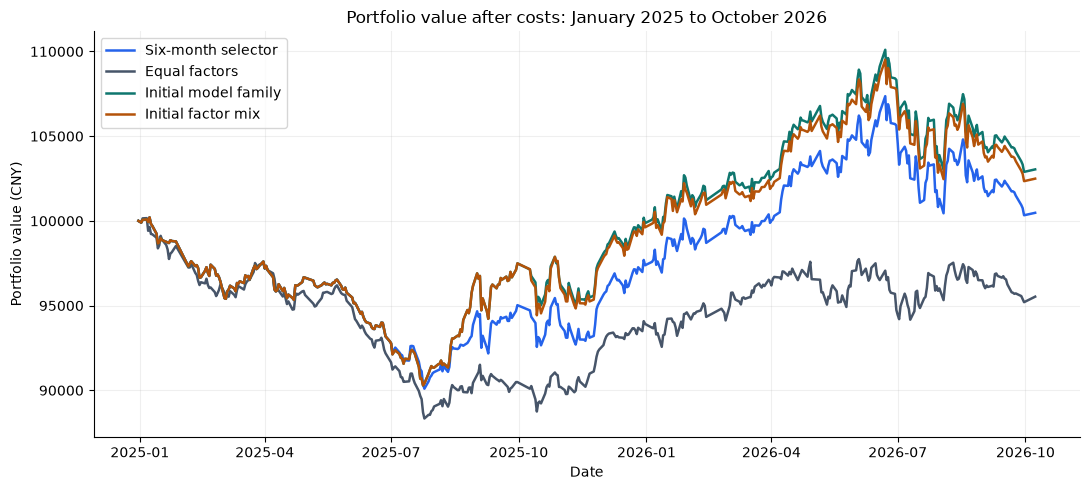

In [79]:
PLOT_COLORS = ["#2563eb", "#475569", "#0f766e", "#b45309"]
PLOT_SIZE = (11, 5)
chart_names = comparison_names[:4]
plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)

figure, axis = plt.subplots(figsize=PLOT_SIZE)
for i, name in enumerate(chart_names):
    axis.plot(
        portfolio_values.index,
        portfolio_values[name],
        label=name,
        color=PLOT_COLORS[i],
        linewidth=1.8,
    )
axis.set_title("Portfolio value after costs: January 2025 to October 2026")
axis.set_xlabel("Date")
axis.set_ylabel("Portfolio value (CNY)")
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / "portfolio_values.png", dpi=160)
plt.show()

Drawdown chart

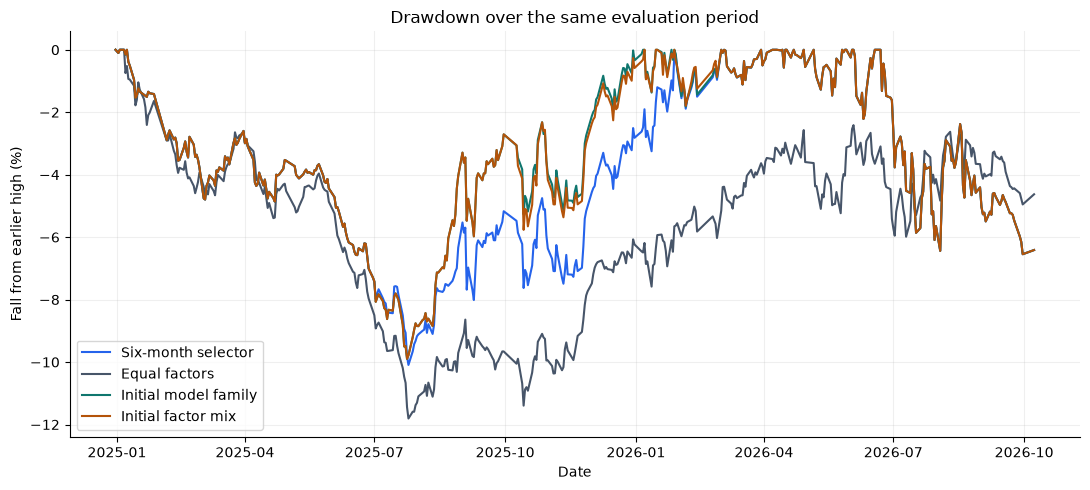

In [80]:
PLOT_COLORS = ["#2563eb", "#475569", "#0f766e", "#b45309"]
PLOT_SIZE = (11, 5)
chart_names = comparison_names[:4]
plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)

figure, axis = plt.subplots(figsize=PLOT_SIZE)
for i, name in enumerate(chart_names):
    series = portfolio_values[name]
    axis.plot(
        series.index,
        (series / series.cummax() - 1) * 100,
        label=name,
        color=PLOT_COLORS[i],
        linewidth=1.5,
    )
axis.set_title("Drawdown over the same evaluation period")
axis.set_xlabel("Date")
axis.set_ylabel("Fall from earlier high (%)")
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / "drawdowns.png", dpi=160)
plt.show()

Factor weights chart

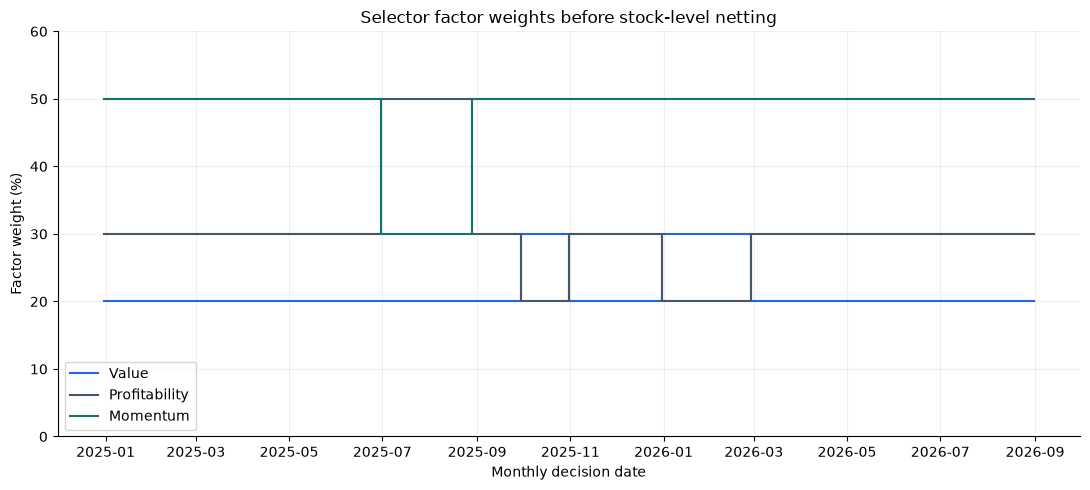

In [81]:
PLOT_COLORS = ["#2563eb", "#475569", "#0f766e", "#b45309"]
PLOT_SIZE = (11, 5)
plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)

figure, axis = plt.subplots(figsize=PLOT_SIZE)
weight_plot = factor_weight_table.loc[
    factor_weight_table.seed.eq(42) & factor_weight_table.strategy.eq("Six-month selector")
].set_index("signal")[FACTORS]
for i, factor in enumerate(FACTORS):
    axis.step(
        weight_plot.index,
        weight_plot[factor] * 100,
        label=factor,
        where="post",
        color=PLOT_COLORS[i],
    )
axis.set_title("Selector factor weights before stock-level netting")
axis.set_xlabel("Monthly decision date")
axis.set_ylabel("Factor weight (%)")
axis.set_ylim(0, 60)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / "factor_weights.png", dpi=160)
plt.show()

Model return chart

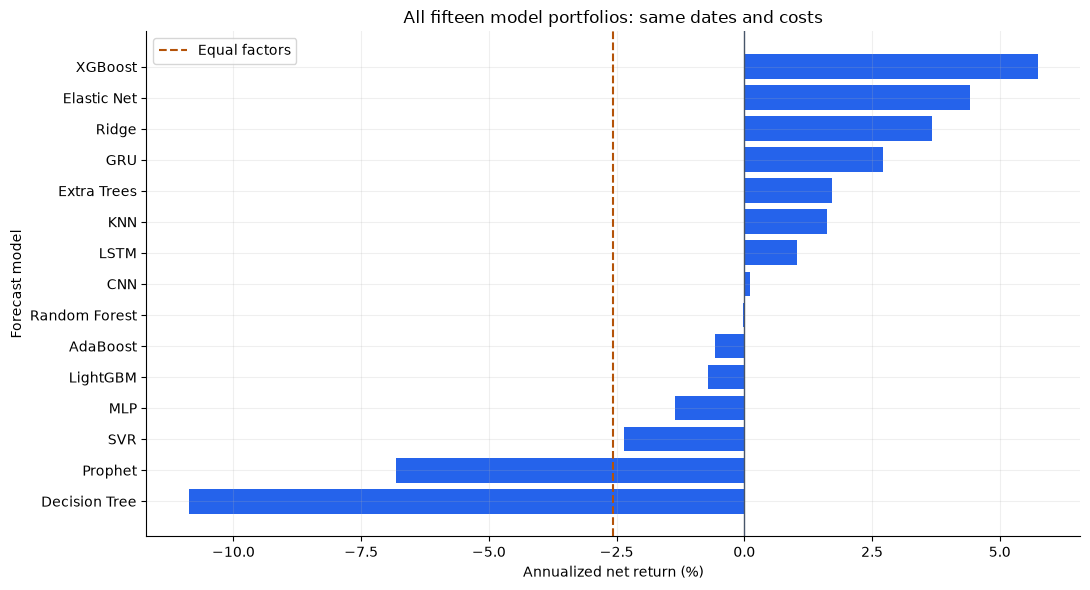

In [82]:
plt.rcParams.update(
    {
        "figure.figsize": (11, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)

figure, axis = plt.subplots(figsize=(11, 6))
model_plot = performance.set_index("strategy").loc[LEARNED_MODELS, "annual_return"].sort_values()
axis.barh(model_plot.index, model_plot.values, color="#2563eb")
axis.axvline(0, color="#475569", linewidth=1)
axis.axvline(
    main_results.loc["Equal factors", "annual_return"],
    color="#b45309",
    linestyle="--",
    label="Equal factors",
)
axis.set_title("All fifteen model portfolios: same dates and costs")
axis.set_xlabel("Annualized net return (%)")
axis.set_ylabel("Forecast model")
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / "all_models.png", dpi=160)
plt.show()

Compare forecast errors and direction

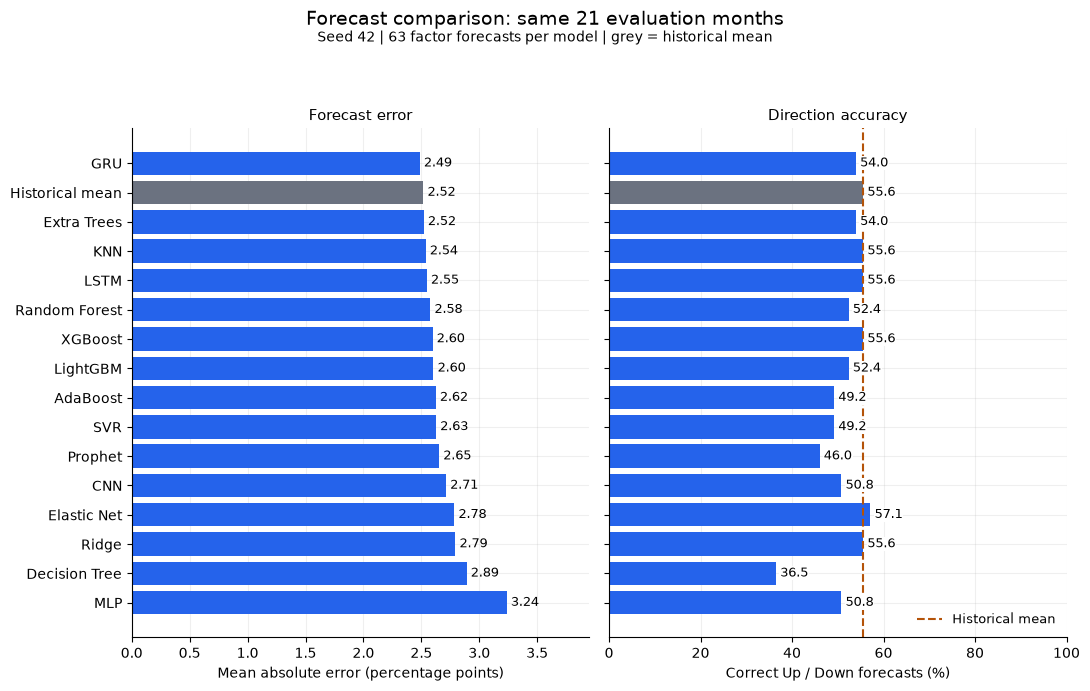

In [83]:
model_color = "#2563eb"
baseline_color = "#6b7280"
plot_metrics = forecast_metrics.loc[forecast_metrics.split.eq("evaluation")].copy()
plot_metrics = plot_metrics.sort_values("mae_pp", ascending=False)
metric_positions = np.arange(len(plot_metrics))
metric_colors = [
    baseline_color if name == "Historical mean" else model_color for name in plot_metrics.model
]
baseline_direction = float(
    plot_metrics.loc[plot_metrics.model.eq("Historical mean"), "direction_accuracy_pct"].iloc[0]
)

figure, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
error_bars = axes[0].barh(metric_positions, plot_metrics.mae_pp, color=metric_colors)
axes[0].bar_label(error_bars, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_yticks(metric_positions, plot_metrics.model)
axes[0].set_xlim(0, plot_metrics.mae_pp.max() * 1.22)
axes[0].set_xlabel("Mean absolute error (percentage points)")
axes[0].set_title("Forecast error", fontsize=11)
direction_bars = axes[1].barh(
    metric_positions, plot_metrics.direction_accuracy_pct, color=metric_colors
)
axes[1].bar_label(
    direction_bars,
    fmt="%.1f",
    padding=3,
    fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5},
)
axes[1].axvline(baseline_direction, color="#b45309", linestyle="--", label="Historical mean")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Correct Up / Down forecasts (%)")
axes[1].set_title("Direction accuracy", fontsize=11)
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
for plot_axis in axes:
    plot_axis.grid(axis="x", alpha=0.2)
    plot_axis.set_axisbelow(True)
    plot_axis.spines[["top", "right"]].set_visible(False)
figure.suptitle("Forecast comparison: same 21 evaluation months", fontsize=14)
figure.text(
    0.5,
    0.935,
    "Seed 42 | 63 factor forecasts per model | grey = historical mean",
    ha="center",
    fontsize=10,
)
figure.tight_layout(rect=(0, 0, 1, 0.91))
figure.savefig(RESULTS / "forecast_comparison.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)

Uncertainty and training seeds

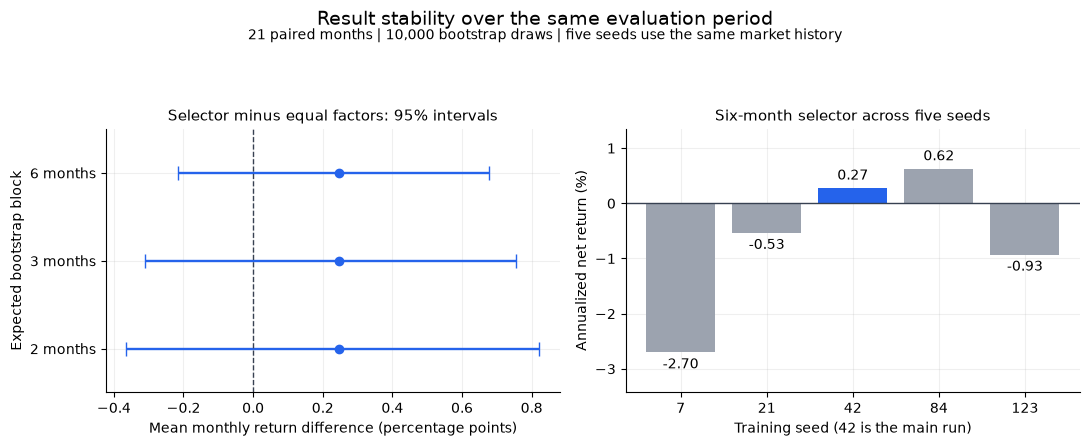

In [84]:
selector_color = "#2563eb"
other_seed_color = "#9ca3af"
interval_data = pd.read_csv(RESULTS / "uncertainty.csv").sort_values("block_length")
seed_plot = pd.read_csv(RESULTS / "seed_results.csv").sort_values("seed")
interval_positions = np.arange(len(interval_data))
interval_errors = np.vstack(
    [
        interval_data["mean_difference"] - interval_data["lower"],
        interval_data["upper"] - interval_data["mean_difference"],
    ]
)

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].errorbar(
    interval_data["mean_difference"],
    interval_positions,
    xerr=interval_errors,
    fmt="o",
    color=selector_color,
    capsize=5,
    linewidth=1.7,
)
axes[0].axvline(0, color="#374151", linestyle="--", linewidth=1)
axes[0].set_yticks(
    interval_positions, [str(value) + " months" for value in interval_data.block_length]
)
axes[0].set_xlabel("Mean monthly return difference (percentage points)")
axes[0].set_ylabel("Expected bootstrap block")
axes[0].set_title("Selector minus equal factors: 95% intervals", fontsize=11)
axes[0].set_ylim(-0.5, len(interval_data) - 0.5)
seed_positions = np.arange(len(seed_plot))
seed_colors = [selector_color if seed == 42 else other_seed_color for seed in seed_plot.seed]
seed_bars = axes[1].bar(seed_positions, seed_plot.annual_return, color=seed_colors)
axes[1].bar_label(seed_bars, fmt="%.2f", padding=4, fontsize=10)
axes[1].axhline(0, color="#374151", linewidth=1)
axes[1].set_xticks(seed_positions, seed_plot.seed.astype(str))
axes[1].set_xlabel("Training seed (42 is the main run)")
axes[1].set_ylabel("Annualized net return (%)")
axes[1].set_title("Six-month selector across five seeds", fontsize=11)
axes[1].margins(y=0.22)
for plot_axis in axes:
    plot_axis.grid(alpha=0.2)
    plot_axis.set_axisbelow(True)
    plot_axis.spines[["top", "right"]].set_visible(False)
figure.suptitle("Result stability over the same evaluation period", fontsize=14)
figure.text(
    0.5,
    0.915,
    "21 paired months | 10,000 bootstrap draws | five seeds use the same market history",
    ha="center",
    fontsize=10,
)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(RESULTS / "result_stability.png", dpi=115, bbox_inches="tight")
plt.show()
plt.close(figure)